In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import pickle
from scipy.stats import linregress, norm, percentileofscore, fisher_exact, chi2_contingency, wilcoxon, describe
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import pyreadr
import statistics as stats
import math
from tabulate import tabulate
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.patches as patches
import pyBigWig
import re
import pysam

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

1
1


In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [5]:
tsv_file = open("/home/meuleman/work/projects/ENCODE3/WM20180608_733_sample_metadata/ENCODE 733-sample list WM20180608 - ENCODE3 metadata.tsv")
biosample_df2 = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
# cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
# n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [6]:
n_cycles, n_comps, n_DHSs = mixture_all_cycles.shape

In [7]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [8]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs

In [9]:
removed_DHS_identifiers = np.array(DHS_metadata.loc[removed_DHS_inds]['identifier'])

In [10]:
removed_biosample_ln = np.array(biosample_df.loc[removed_biosample_inds]['Altius Library ID'])
removed_biosample_ln_stripped = np.array([])
for ln in removed_biosample_ln:
    if ln[-1].isalpha():
        removed_biosample_ln_stripped = np.append(removed_biosample_ln_stripped, ln[:-1])
    else:
        removed_biosample_ln_stripped = np.append(removed_biosample_ln_stripped, ln)

In [11]:
identifier2chunk = {}
chunk2identifier = {}
f = open("/home/meuleman/projects/ENCODE3/WM20180608_construct_masterlist_733samples/masterlist_DHSs_733samples_WM20180608_all_chunkIDs2indexIDs.txt", "r")
for line in f:
    line = line.strip().split('\t')
    identifier2chunk[line[0]] = line[1]
    chunk2identifier[line[1]] = line[0]
f.close()

In [12]:
#finding the chunks of each removed DHS
removed_DHS_chunks = np.array([])
for identifier in removed_DHS_identifiers:
    removed_DHS_chunks = np.append(removed_DHS_chunks, identifier2chunk[identifier])

In [ ]:
# #for each removed call, finding the biosamples that contributed to the DHS and where the peak signal is
# removed_DHS_calls = []
# removed_DHS_original_peaks = []
# for chunk in removed_DHS_chunks:
#     chunk_info = []
#     core_chunk = chunk.split('_')[0]
#     core_bed = open("/net/seq/data/projects/ENCODE3_publications/erynes/ENCODEpaper2017/SubsetOf733/masterLists/workdir/peaks_all/"+core_chunk+".bed", "r")
#     for line in core_bed:
#         line = line.strip().split('\t')
#         if line[-1]==chunk:
#             chunk_info.append(line)
#     chunk_info = np.array(chunk_info)
#     removed_DHS_calls.append(chunk_info)
#     removed_DHS_original_peaks.append(np.median(chunk_info[:, 6].astype(int)))
#     core_bed.close()
# removed_DHS_original_peaks = np.array(removed_DHS_original_peaks).astype(int)

In [17]:
# pickle_out = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'wb')
# pickle.dump(removed_DHS_calls, pickle_out)
# pickle_out.close()

In [18]:
# pickle_out = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'wb')
# pickle.dump(removed_DHS_original_peaks, pickle_out)
# pickle_out.close()

In [13]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_per_biosample_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'rb')
removed_DHS_calls=pickle.load(pickle_in)

In [14]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/reconstructed_threshold_flip_median_smooth_peaks_for_removed_call_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220414.pickle', 'rb')
removed_DHS_original_peaks=pickle.load(pickle_in)

In [15]:
DHS_identifiers = np.array(DHS_metadata['identifier'])

In [16]:
identifier2ind = {}
for i in range(len(DHS_identifiers)):
    identifier2ind[DHS_identifiers[i]] = i

In [17]:
all_ln_nums = np.array(biosample_df['Altius Library ID'])
all_ln_stripped = np.array([])
for ln in all_ln_nums:
    if ln[-1].isalpha():
        all_ln_stripped = np.append(all_ln_stripped, ln[:-1])
    else:
        all_ln_stripped = np.append(all_ln_stripped, ln)

In [21]:
# #distances from each removed call peak to consesus peak
# removed_peak_distance_from_consensus_all = []
# max_distance_from_consensus_all = []
# removed_peak_order_from_consensus_all = []
# number_of_unique_distances_all = []
# removed_peak_distance_percentile = []
# removed_score_percentile = []
# all_call_distance_percentiles_from_removed_DHSs = []
# all_call_distance_range_percentile = np.zeros(100)
# removed_call_distance_range_percentile = np.zeros(100)
# all_call_score_range_percentile = np.zeros(100)
# removed_call_score_range_percentile = np.zeros(100)
# all_call_score_percentiles_from_removed_DHSs = []
# core_contingency = np.zeros((733, 2, 2), dtype=int)
# comp_contingency = np.zeros((733, 2, 2), dtype=int)
# used_dhs_inds = set()

# all_call_distance_range_percentile = np.zeros(100)
# for peak_location, chunk_info, removed_ln in zip(removed_DHS_original_peaks, 
#                                                  removed_DHS_calls, 
#                                                  removed_biosample_ln_stripped):
#     #start and end of core region
#     core_95 = np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
#     core_start = core_95[0]
#     core_end = core_95[1]
# #     DHS_ind = np.where(DHS_identifiers==chunk2identifier[chunk_info[0, 7]])[0][0]
#     DHS_ind = identifier2ind[chunk2identifier[chunk_info[0, 7]]]
#     DHS_comp = mixture_all_cycles_top_comp[0, DHS_ind]
#     DHS_start = int(DHS_metadata.loc[DHS_ind]['start'])
#     DHS_end = int(DHS_metadata.loc[DHS_ind]['end'])
#     if core_start < DHS_start:
#         core_start = DHS_start
#     if core_end > DHS_end:
#         core_end = DHS_end
    
#     #all calls distance from consensus
#     all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
    
#     #removed biosample local ind
#     removed_inds = np.where(chunk_info==removed_ln)[0]
    
#     #scores for all calls
#     scores = chunk_info[:, 4].astype(float)
    
#     for removed_ind in removed_inds:
#         #distance of removed call from peak
#         removed_peak_distance_from_consensus = np.abs(chunk_info[removed_ind, 6].astype(int) - peak_location)
#         removed_peak_distance_from_consensus_all.append(removed_peak_distance_from_consensus)
#         #max distance from all calls to consensus peak
#         max_distance_from_consensus = np.max(np.abs(chunk_info[:, 6].astype(int) - peak_location))
#         max_distance_from_consensus_all.append(max_distance_from_consensus)
#         #finding order of distances of removed call (0 is closest to consensus, the larger the number, 
#         #the further away)
#         unique_distances = np.unique(np.abs(chunk_info[:, 6].astype(int) - peak_location))
#         removed_peak_order_from_consensus = np.where(unique_distances==removed_peak_distance_from_consensus)[0][0]
#         removed_peak_order_from_consensus_all.append(removed_peak_order_from_consensus)
#         #number of unique distances
#         number_of_unique_distances = len(unique_distances)
#         number_of_unique_distances_all.append(number_of_unique_distances)
#         #percentile of distance
# #         all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
# #         distance_percentile = percentileofscore(all_distances, removed_peak_distance_from_consensus)
# #         removed_peak_distance_percentile.append(distance_percentile)
#         distance_percentile_range = percentile_range(all_distances, removed_peak_distance_from_consensus)
#         removed_call_distance_range_percentile[int(distance_percentile_range[0]):
#                                                int(distance_percentile_range[1])] += distance_percentile_range[2]
#         #score percentile
#         score = chunk_info[removed_ind, 4].astype(float)
# #         score_percentile = percentileofscore(scores, score)
# #         removed_score_percentile.append(score_percentile)
#         score_percentile_range = percentile_range(scores, score)
#         removed_call_score_range_percentile[int(score_percentile_range[0]):
#                                             int(score_percentile_range[1])] += score_percentile_range[2]

#     ###Need to recalculate such that calls are only counted once. Maybe move to unique DHS cell below###
#     for call in range(len(chunk_info)):
#         #distance percentile
#         call_distance = np.abs(chunk_info[call, 6].astype(int) - peak_location)
# #         call_percentile = percentileofscore(all_distances, call_distance)
# #         all_call_distance_percentiles_from_removed_DHSs.append(call_percentile)
        
#         if DHS_ind not in used_dhs_inds: #temperary fix, but move all to below tomorrow 5/5/22
#             distance_percentile_range = percentile_range(all_distances, call_distance)
#             all_call_distance_range_percentile[int(distance_percentile_range[0]):
#                                                int(distance_percentile_range[1])] += distance_percentile_range[2]
    
        
#         #score percentile
#         score = chunk_info[call, 4].astype(float)
# #         score_percentile = percentileofscore(scores, score)
# #         all_call_score_percentiles_from_removed_DHSs.append(score_percentile)
#         if DHS_ind not in used_dhs_inds: #temperary fix, but move all to below tomorrow 5/5/22
#             score_percentile_range = percentile_range(scores, score)
#             all_call_score_range_percentile[int(score_percentile_range[0]):
#                                             int(score_percentile_range[1])] += score_percentile_range[2]
        
        
        
#         call_peak = chunk_info[call, 6].astype(int)
#         if ((call_peak < core_start) | (call_peak > core_end)): #outside core or not
#             con_col = 0
#         else:
#             con_col = 1

#         if call in removed_inds: #removed or not
#             con_row = 0
#         else:
#             con_row = 1
#         core_contingency[len(chunk_info)-1, con_row, con_col]+=1
#         #comp contingency
#         ln = chunk_info[call, 3]
#         biosample_ind = np.where(all_ln_stripped==ln)[0][0]
#         biosample_comp = basis_all_cycles_top_comp[0, biosample_ind]
#         if biosample_comp!=DHS_comp: #different comp or same
#             con_col = 0
#         else:
#             con_col = 1
#         comp_contingency[len(chunk_info)-1, con_row, con_col]+=1
#     used_dhs_inds.add(DHS_ind)
            

# removed_peak_distance_from_consensus_all = np.array(removed_peak_distance_from_consensus_all)
# max_distance_from_consensus_all = np.array(max_distance_from_consensus_all)
# number_of_unique_distances_all = np.array(number_of_unique_distances_all)
# removed_peak_order_from_consensus_all = np.array(removed_peak_order_from_consensus_all)
# removed_peak_distance_percentile = np.array(removed_peak_distance_percentile)
# removed_score_percentile = np.array(removed_score_percentile)
# all_call_distance_percentiles_from_removed_DHSs = np.array(all_call_distance_percentiles_from_removed_DHSs)
# all_call_score_percentiles_from_removed_DHSs = np.array(all_call_score_percentiles_from_removed_DHSs)

In [18]:
def percentile_range(all_scores, score):
    num_scores = len(all_scores)
    sorted_scores = np.sort(all_scores)
#     high_rank = np.mean(np.where(sorted_scores==score)[0]+1)
#     high_percentile = (high_rank)/num_scores*100
#     low_rank = np.mean(np.where(sorted_scores==score)[0])
#     low_percentile = (low_rank)/num_scores*100
    sorted_score_inds = np.where(sorted_scores==score)[0]
    high_rank = sorted_score_inds[-1]+1
    low_rank = sorted_score_inds[0]
    high_percentile = high_rank/num_scores*100
    low_percentile = low_rank/num_scores*100
    weight = 1/len(sorted_score_inds)
    return low_percentile, high_percentile, weight

In [19]:
#totalling removed biosamples for each chunk
removed_ln_from_each_chunk = {}
unique_removed_DHS_calls = []
unique_removed_DHS_calls_DHS_inds = []
for chunk_info, removed_ln in zip(removed_DHS_calls, 
                                  removed_biosample_ln_stripped):
    chunk = chunk_info[0][-1]
    if chunk not in removed_ln_from_each_chunk:
        removed_ln_from_each_chunk[chunk] = np.array([removed_ln])
        unique_removed_DHS_calls.append(chunk_info)
        unique_removed_DHS_calls_DHS_inds.append(identifier2ind[chunk2identifier[chunk]])
    else:
        removed_ln_from_each_chunk[chunk] = np.append(removed_ln_from_each_chunk[chunk], [removed_ln])
unique_removed_DHS_calls_DHS_inds = np.array(unique_removed_DHS_calls_DHS_inds)

In [20]:
#distances from each removed call peak to consesus peak
removed_peak_distance_from_consensus_all = []
max_distance_from_consensus_all = []
removed_peak_order_from_consensus_all = []
number_of_unique_distances_all = []
#percentile arrays
all_call_distance_range_percentile = np.zeros(100)
removed_call_distance_range_percentile = np.zeros(100)
all_call_score_range_percentile = np.zeros(100)
removed_call_score_range_percentile = np.zeros(100)
#contingency tables
core_contingency = np.zeros((733, 2, 2), dtype=int)
comp_contingency = np.zeros((733, 2, 2), dtype=int)
#cross percentile tracking
removed_call_cross_percentile_track = []
all_call_cross_percentile_track = []
removed_call_cross_fullpercentilerange_track = []

for chunk_info, urdc_ind in zip(unique_removed_DHS_calls, range(len(unique_removed_DHS_calls))):
    
    #chunk
    chunk = chunk_info[0, -1]
    #peak location
    peak_location = np.median(chunk_info[:, 6].astype(int))
    #start and end of core region
    core_95 = np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
    core_start = core_95[0]
    core_end = core_95[1]
    DHS_ind = identifier2ind[chunk2identifier[chunk_info[0, 7]]]
    DHS_comp = mixture_all_cycles_top_comp[0, DHS_ind]
    DHS_start = int(DHS_metadata.loc[DHS_ind]['start'])
    DHS_end = int(DHS_metadata.loc[DHS_ind]['end'])
    if core_start < DHS_start:
        core_start = DHS_start
    if core_end > DHS_end:
        core_end = DHS_end
    
    #all calls distance from consensus
    all_distances = np.abs(chunk_info[:, 6].astype(int) - peak_location)
    
    #removed biosample local ind
    removed_lns = removed_ln_from_each_chunk[chunk]
    removed_inds = np.array([], dtype=int)
    matching_removed_lns = np.array([])
    for removed_ln in removed_lns:
        removed_inds = np.append(removed_inds, np.where(chunk_info==removed_ln)[0])
        matching_removed_lns = np.append(matching_removed_lns, 
                                         np.array([removed_ln]*len(np.where(chunk_info==removed_ln)[0])))
    
    
    #scores for all calls
    scores = chunk_info[:, 4].astype(float)
    
    for removed_ind, removed_ln in zip(removed_inds, matching_removed_lns):
        #distance of removed call from peak
        removed_peak_distance_from_consensus = np.abs(chunk_info[removed_ind, 6].astype(int) - peak_location)
        removed_peak_distance_from_consensus_all.append(removed_peak_distance_from_consensus)
        #max distance from all calls to consensus peak
        max_distance_from_consensus = np.max(np.abs(chunk_info[:, 6].astype(int) - peak_location))
        max_distance_from_consensus_all.append(max_distance_from_consensus)
        #finding order of distances of removed call (0 is closest to consensus, the larger the number, 
        #the further away)
        unique_distances = np.unique(np.abs(chunk_info[:, 6].astype(int) - peak_location))
        removed_peak_order_from_consensus = np.where(unique_distances==removed_peak_distance_from_consensus)[0][0]
        removed_peak_order_from_consensus_all.append(removed_peak_order_from_consensus)
        #number of unique distances
        number_of_unique_distances = len(unique_distances)
        number_of_unique_distances_all.append(number_of_unique_distances)
        #percentile of distance
        distance_percentile_range = percentile_range(all_distances, removed_peak_distance_from_consensus)
        removed_call_distance_range_percentile[int(distance_percentile_range[0]):
                                               int(distance_percentile_range[1])] += distance_percentile_range[2]
        #score percentile
        score = chunk_info[removed_ind, 4].astype(float)
        score_percentile_range = percentile_range(scores, score)
        removed_call_score_range_percentile[int(score_percentile_range[0]):
                                            int(score_percentile_range[1])] += score_percentile_range[2]
        
        #averaging percentiles
        average_distance_per = int(np.mean(distance_percentile_range[:2]))
        average_score_per = int(np.mean(score_percentile_range[:2]))
        #biosample ind, DHS_ind, distance percentile, score percentile, urdc ind
        removed_call_cross_percentile_track.append([np.where(all_ln_stripped==removed_ln)[0][0], 
                                                    DHS_ind, 
                                                    average_distance_per, 
                                                    average_score_per,
                                                    urdc_ind])
        #biosample_ind, DHS ind, distance lower, distance higher, distance weight
        #score lower, score higher, score weight, urdc ind
        removed_call_cross_fullpercentilerange_track.append([np.where(all_ln_stripped==removed_ln)[0][0],
                                                             DHS_ind,
                                                             distance_percentile_range[0],
                                                             distance_percentile_range[1],
                                                             distance_percentile_range[2],
                                                             score_percentile_range[0],
                                                             score_percentile_range[1],
                                                             score_percentile_range[2],
                                                             urdc_ind])
        

    #for all calls, find percentiles and build contingency tables
    for call in range(len(chunk_info)):
        #distance percentile
        call_distance = np.abs(chunk_info[call, 6].astype(int) - peak_location)
        distance_percentile_range = percentile_range(all_distances, call_distance)
        all_call_distance_range_percentile[int(distance_percentile_range[0]):
                                           int(distance_percentile_range[1])] += distance_percentile_range[2]
    
        #score percentile
        score = chunk_info[call, 4].astype(float)
        score_percentile_range = percentile_range(scores, score)
        all_call_score_range_percentile[int(score_percentile_range[0]):
                                        int(score_percentile_range[1])] += score_percentile_range[2]
        
        call_peak = chunk_info[call, 6].astype(int)
        if ((call_peak < core_start) | (call_peak > core_end)): #outside core or not
            con_col = 0
        else:
            con_col = 1

        if call in removed_inds: #removed or not
            con_row = 0
        else:
            con_row = 1
        core_contingency[len(chunk_info)-1, con_row, con_col]+=1
        #comp contingency
        ln = chunk_info[call, 3]
        biosample_ind = np.where(all_ln_stripped==ln)[0][0]
        biosample_comp = basis_all_cycles_top_comp[0, biosample_ind]
        if biosample_comp!=DHS_comp: #different comp or same
            con_col = 0
        else:
            con_col = 1
        comp_contingency[len(chunk_info)-1, con_row, con_col]+=1
        
        #call ln
        call_ln = chunk_info[call, 3]
        #average percentiles
        call_average_distance_per = int(np.mean(distance_percentile_range[:2]))
        call_average_score_per = int(np.mean(score_percentile_range[:2]))
        #biosample ind, DHS_ind, distance percentile, score percentile, urdc ind
        all_call_cross_percentile_track.append([np.where(all_ln_stripped==call_ln)[0][0], 
                                                DHS_ind, 
                                                call_average_distance_per, 
                                                call_average_score_per,
                                                urdc_ind])
        
            

removed_peak_distance_from_consensus_all = np.array(removed_peak_distance_from_consensus_all)
max_distance_from_consensus_all = np.array(max_distance_from_consensus_all)
number_of_unique_distances_all = np.array(number_of_unique_distances_all)
removed_peak_order_from_consensus_all = np.array(removed_peak_order_from_consensus_all)
removed_call_cross_percentile_track = np.array(removed_call_cross_percentile_track)
all_call_cross_percentile_track = np.array(all_call_cross_percentile_track)
removed_call_cross_fullpercentilerange_track = np.array(removed_call_cross_fullpercentilerange_track)

In [100]:
core_contingency_all = np.sum(core_contingency, axis=0)
core_contingency_all

array([[  5198,  17371],
       [ 38056, 987439]])

In [34]:
#ratio of percent removed outside core (out of all removed) 
#to percent not removed outside core (out of all not removed)
(core_contingency_all[0, 0]/np.sum(core_contingency_all[0, :]))/(core_contingency_all[1, 0]/np.sum(core_contingency_all[1, :]))

6.206322904390007

In [35]:
ratio = ((np.sum(core_contingency_all[0, :])/np.sum(core_contingency_all[1, :])) / 
         (np.sum(core_contingency_all[:, 0])/np.sum(core_contingency_all[:, 1])))
ratio

0.5112536740010951

In [36]:
odds_ratio, pval = fisher_exact(core_contingency_all, alternative='two-sided')
print(odds_ratio, pval)

7.764233586389849 0.0


In [37]:
comp_contingency_all = np.sum(comp_contingency, axis=0)
comp_contingency_all

array([[ 22569,      0],
       [686009, 339486]])

In [38]:
#ratio of percent removed with diff comp (out of all removed) 
#to percent not removed with diff comp (out of all not removed)
(comp_contingency_all[0, 0]/np.sum(comp_contingency_all[0, :]))/(comp_contingency_all[1, 0]/np.sum(comp_contingency_all[1, :]))

1.4948710585429636

In [39]:
ratio = ((np.sum(comp_contingency_all[0, :])/np.sum(comp_contingency_all[1, :])) / 
         (np.sum(comp_contingency_all[:, 0])/np.sum(comp_contingency_all[:, 1])))
ratio

0.010544183961285094

In [40]:
odds_ratio, pval = fisher_exact(comp_contingency_all, alternative='two-sided')
print(odds_ratio, pval)

inf 0.0


In [41]:
# #number of removed and all calls in removed call DHSs
# num_all_calls = np.sum(core_contingency_all)
# num_removed_calls = np.sum(core_contingency_all[0, :])

/tmp/ipykernel_131172/3120624240.py:12: RuntimeWarning: invalid value encountered in true_divide
  axes[1, 0].hist(removed_peak_distance_from_consensus_all/max_distance_from_consensus_all, bins=40)


Summit of Removed Calls Are Distant from DHS Consensus Summit


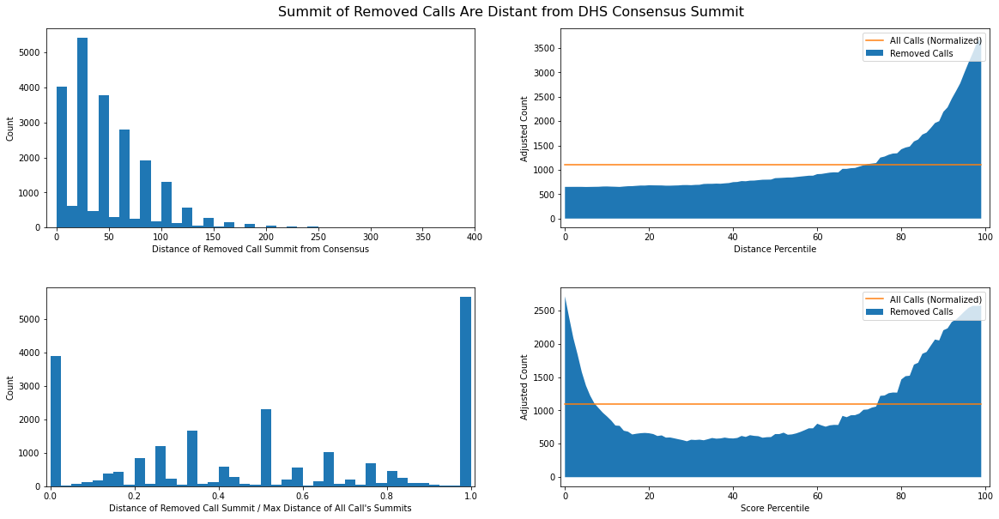

In [22]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16,8))
fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes[0, 0].hist(removed_peak_distance_from_consensus_all[removed_peak_distance_from_consensus_all<=400], bins=40)
axes[0, 0].set_xlim([-10, 400])
axes[0, 0].set_xlabel('Distance of Removed Call Summit from Consensus')
axes[0, 0].set_ylabel('Count')
# axes[0].set_yscale('log')

axes[1, 0].hist(removed_peak_distance_from_consensus_all/max_distance_from_consensus_all, bins=40)
axes[1, 0].set_xlim([-.01, 1.01])
axes[1, 0].set_xlabel('Distance of Removed Call Summit / Max Distance of All Call\'s Summits')
axes[1, 0].set_ylabel('Count')
# axes[1].set_yscale('log')



axes[0, 1].set_xlim([-1, 101])
axes[0, 1].fill_between(np.arange(len(removed_call_distance_range_percentile)), removed_call_distance_range_percentile)
axes[0, 1].plot(np.arange(len(all_call_distance_range_percentile)), 
                all_call_distance_range_percentile/np.sum(all_call_distance_range_percentile)*np.sum(removed_call_distance_range_percentile), 
                color='#ff7f0e')
axes[0, 1].set_xlabel('Distance Percentile')
# axes[2].set_ylabel('All Call Count')
# ax2_twin.set_ylabel('Removed Call Count', rotation=270)
axes[0, 1].set_ylabel('Adjusted Count')
axes[0, 1].legend(['All Calls (Normalized)', 'Removed Calls'])


axes[1, 1].set_xlim([-1, 101])
axes[1, 1].fill_between(np.arange(len(removed_call_score_range_percentile)), removed_call_score_range_percentile)
axes[1, 1].plot(np.arange(len(all_call_score_range_percentile)), 
                all_call_score_range_percentile/np.sum(all_call_score_range_percentile)*np.sum(removed_call_score_range_percentile), 
                color='#ff7f0e')
axes[1, 1].set_xlabel('Score Percentile')

axes[1, 1].set_ylabel('Adjusted Count')
axes[1, 1].legend(['All Calls (Normalized)', 'Removed Calls'])


title = 'Summit of Removed Calls Are Distant from DHS Consensus Summit'
plt.suptitle(title, fontsize=16, x=0.5, y=1.02)
today = date.today()
# plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
print(title)

In [142]:
#all calls
all_score_distance_contingency_50_50 = np.zeros((2, 2), dtype=int)
distance_thresh=50
score_thresh=50
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
#rows - distance
#columns - score
for call in all_call_cross_percentile_track:
    if call[2] > distance_thresh:
        row_ind=0
    else:
        row_ind=1
    if call[3] > score_thresh:
        col_ind=0
    else:
        col_ind=1
    all_score_distance_contingency_50_50[row_ind, col_ind]+=1
print(fisher_exact(all_score_distance_contingency_50_50))
all_score_distance_contingency_50_50

(0.7972453046123206, 0.0)


array([[236047, 276511],
       [276903, 258603]])

In [189]:
score_distance_contingency_50_50 = np.zeros((2, 2), dtype=int)
distance_thresh=50
score_thresh=50
a_list = [] #high score, high distance
b_list = [] #high score, low distance
c_list = [] #low score, high distance
d_list = [] #low score, low distance
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
#rows - distance
#columns - score
for call in removed_call_cross_percentile_track:
    if call[2] > distance_thresh:
        row_ind=0
    else:
        row_ind=1
    if call[3] > score_thresh:
        col_ind=0
    else:
        col_ind=1
    score_distance_contingency_50_50[row_ind, col_ind]+=1
    
    if ((row_ind==0) & (col_ind==0)):
        a_list.append(call[4])
    elif ((row_ind==1) & (col_ind==0)):
        b_list.append(call[4])
    elif ((row_ind==0) & (col_ind==1)):
        c_list.append(call[4])
    elif ((row_ind==1) & (col_ind==1)):
        d_list.append(call[4])
    
print(fisher_exact(score_distance_contingency_50_50))
score_distance_contingency_50_50

(0.6554702275271141, 2.931515547026325e-48)


array([[7275, 8320],
       [3986, 2988]])

In [190]:
#finding examples unique to 1 list
a_set = set(a_list)
b_set = set(b_list)
c_set = set(c_list)
d_set = set(d_list)

a_only = list(a_set - b_set - c_set - d_set)
b_only = list(b_set - c_set - d_set - a_set)
c_only = list(c_set - d_set - a_set - b_set)
d_only = list(d_set - a_set - b_set - c_set)

9313
Calls Removed in DHS 6.543169


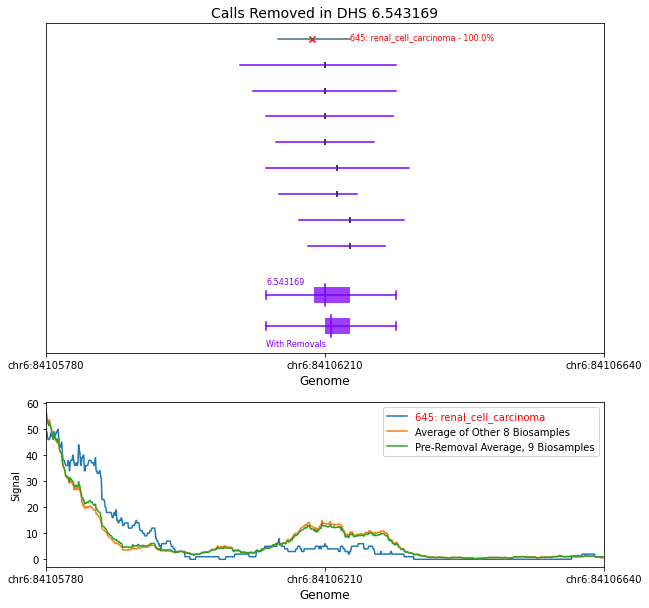

17030
Calls Removed in DHS 14.689953


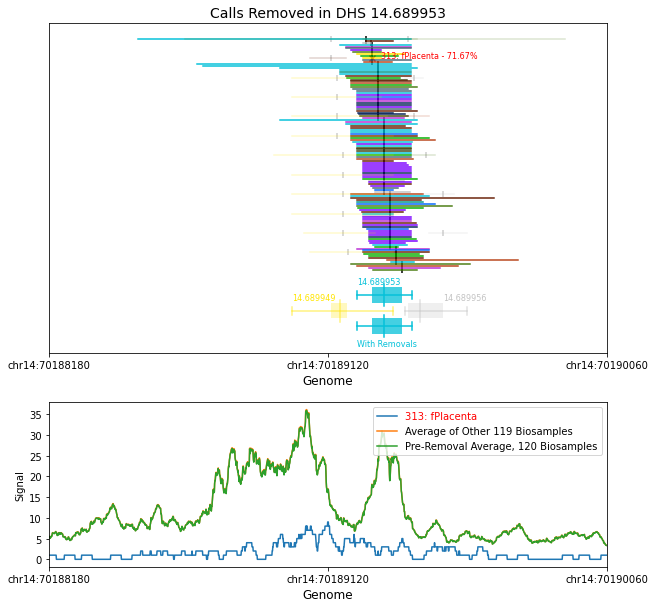

15211
Calls Removed in DHS 13.4514668


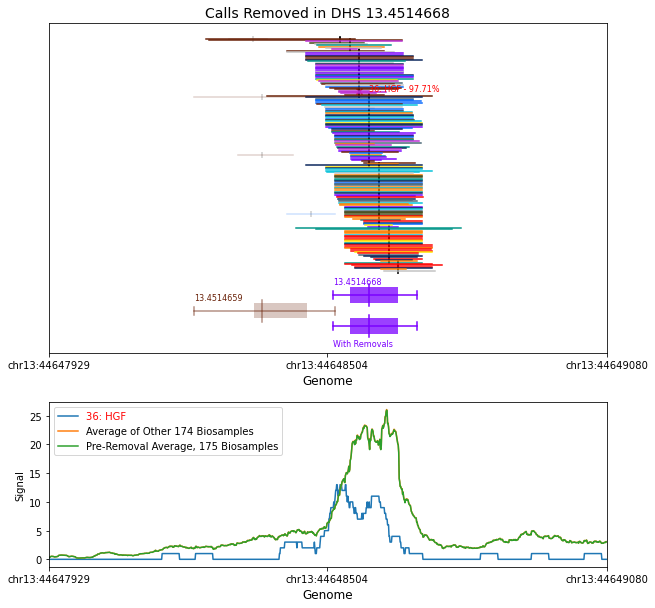

15189
Calls Removed in DHS 13.3446839


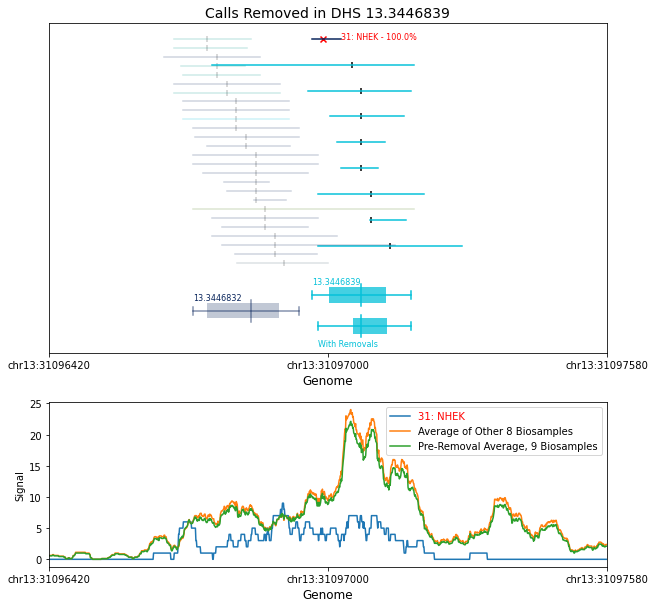

51
Calls Removed in DHS 5.885772


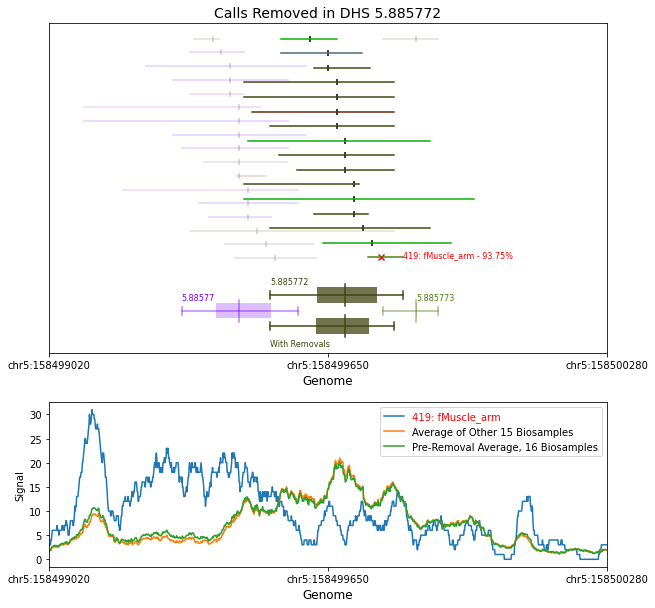

20018
Calls Removed in DHS 8.261876


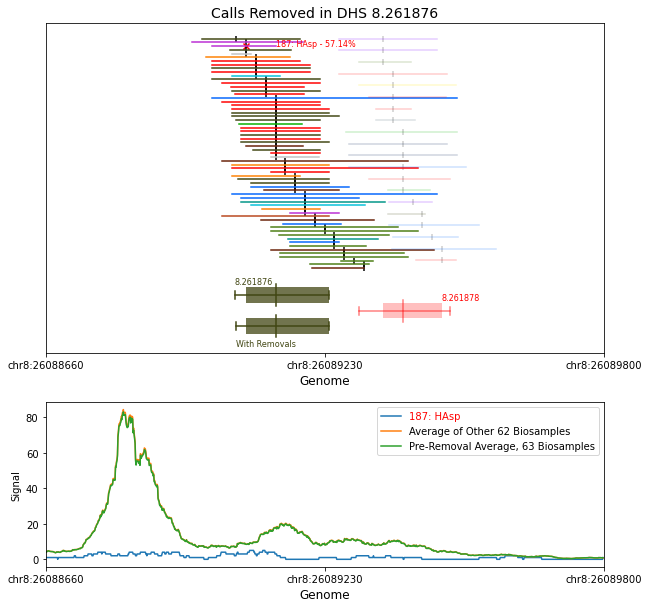

4620
Calls Removed in DHS 12.8052904


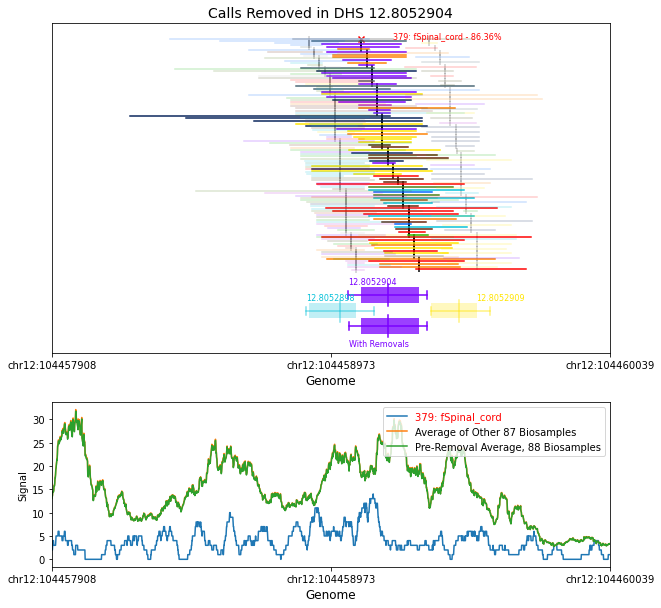

12338
Calls Removed in DHS 4.182017


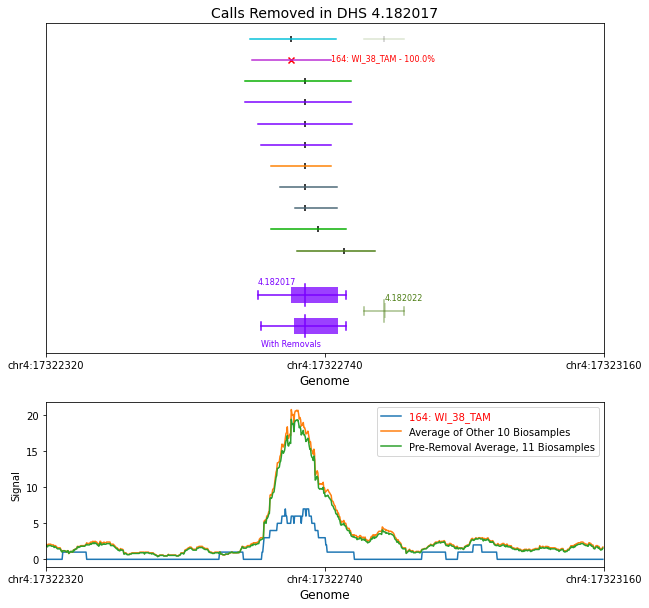

12949
Calls Removed in DHS 20.16462


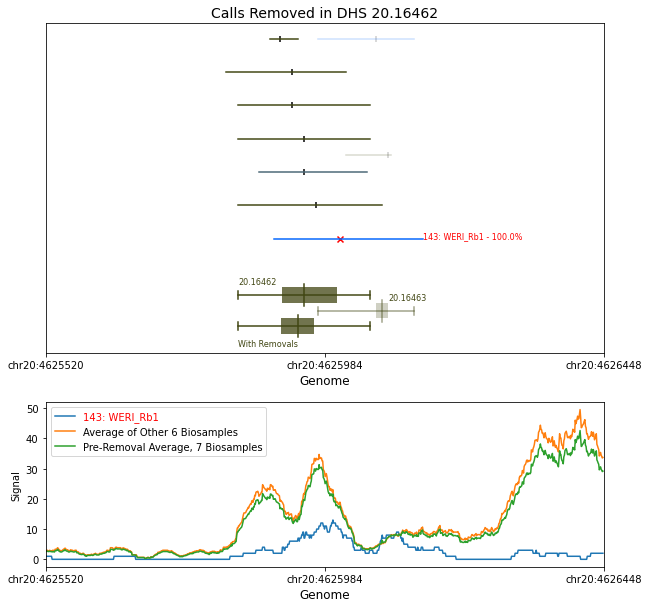

8294
Calls Removed in DHS 3.357874


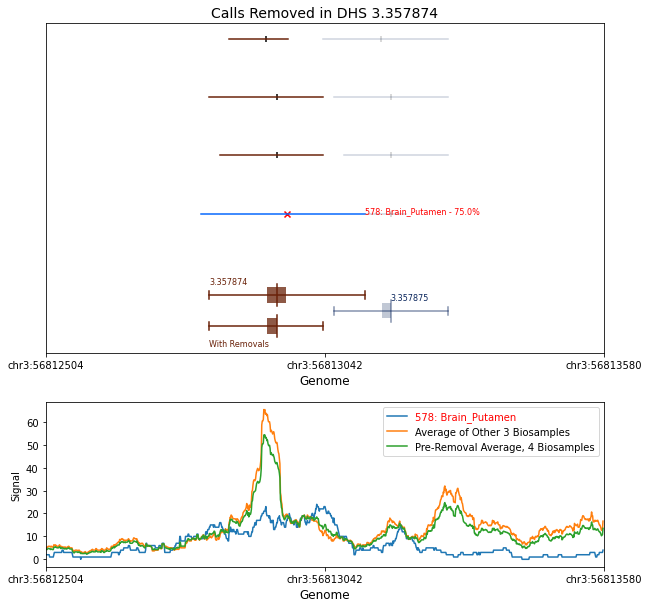

In [196]:
#high score, high distance - 5/11/22
for i in range(10):
    ind = random.randrange(len(a_only))
    print(a_only[ind])
    plotting_removed_calls(a_only[ind], signal_type='bam', pre_removal_ave=True)

Calls Removed in DHS 6.543169


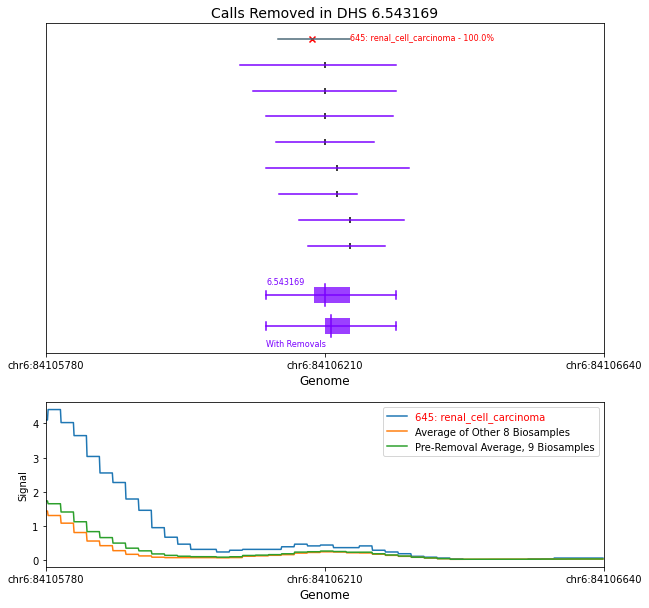

Calls Removed in DHS 14.689953


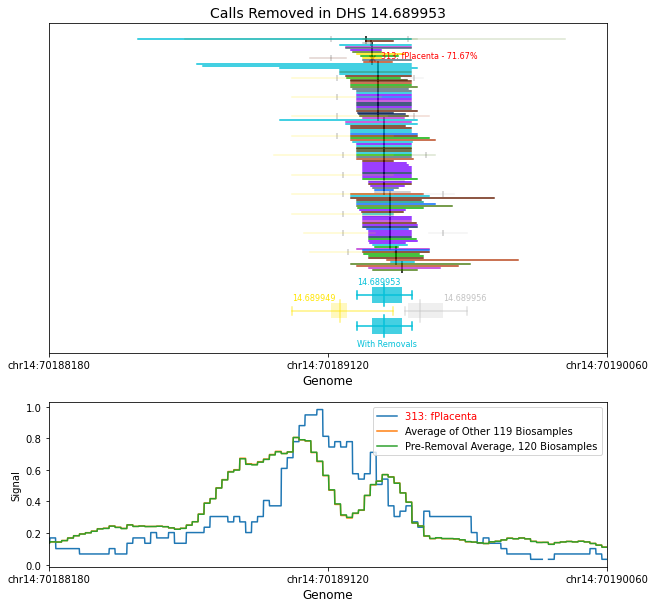

Calls Removed in DHS 13.4514668


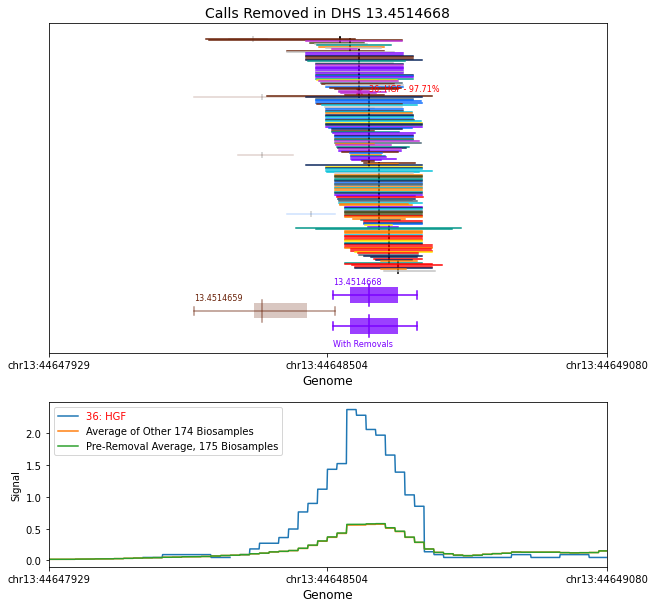

Calls Removed in DHS 13.3446839


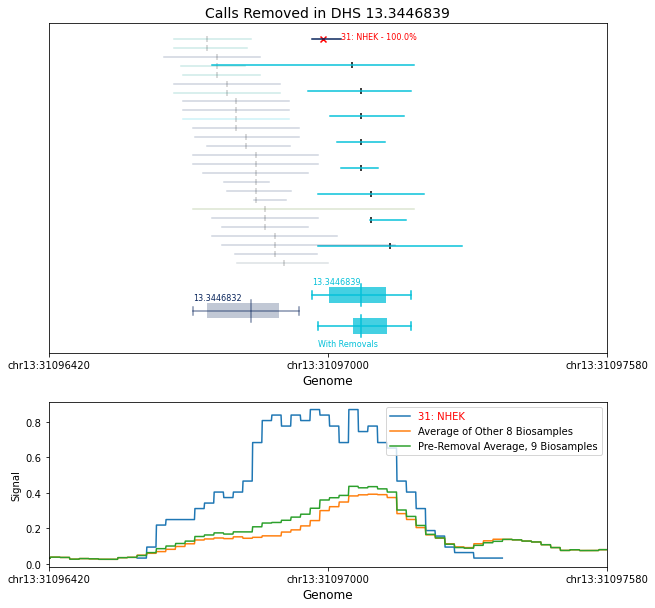

Calls Removed in DHS 5.885772


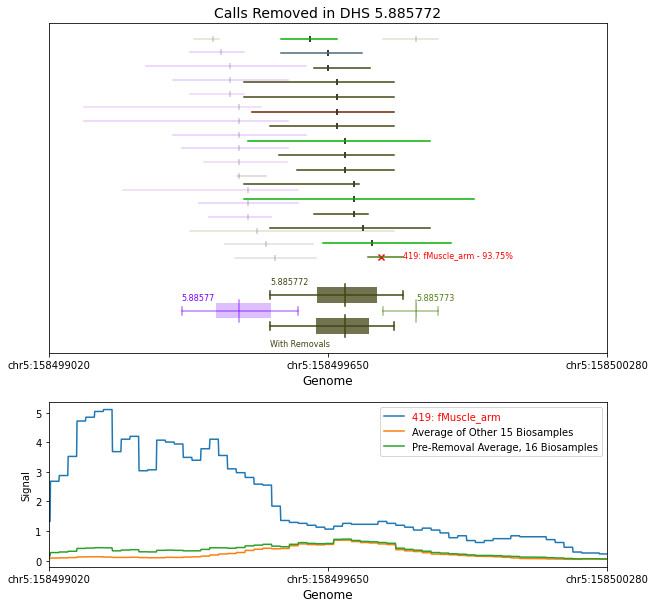

Calls Removed in DHS 8.261876


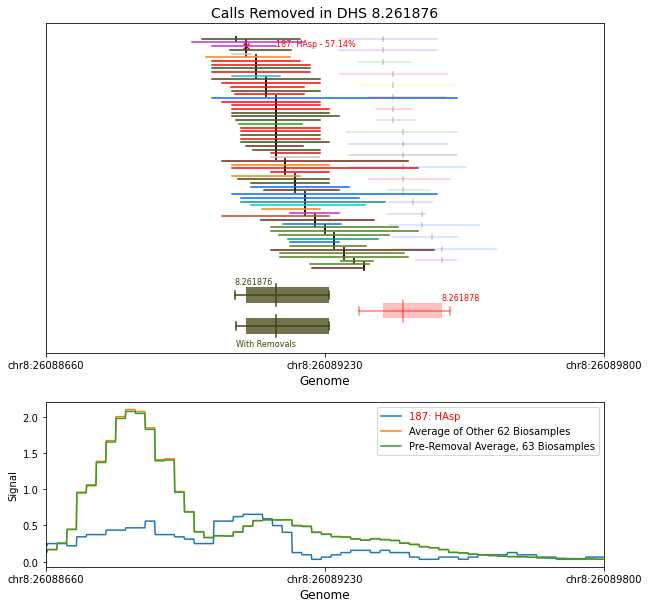

Calls Removed in DHS 12.8052904


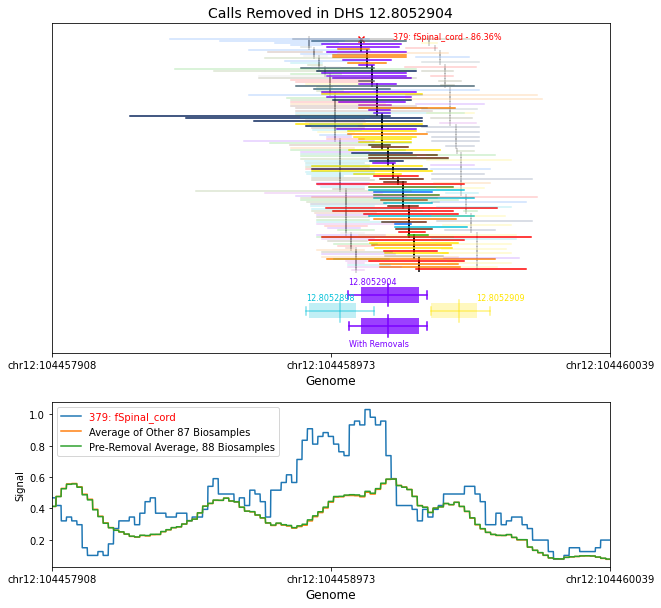

Calls Removed in DHS 4.182017


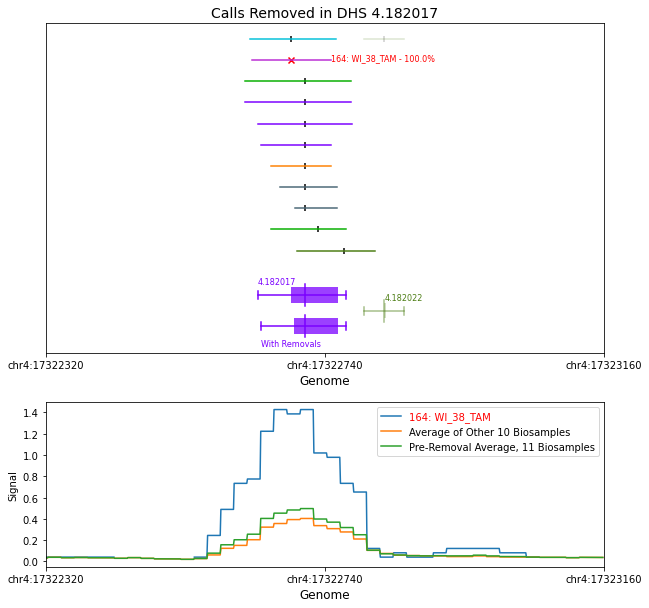

Calls Removed in DHS 20.16462


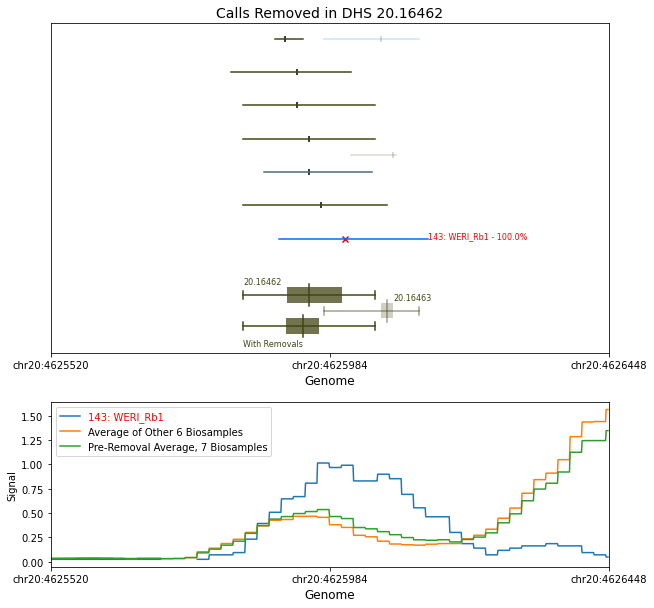

Calls Removed in DHS 3.357874


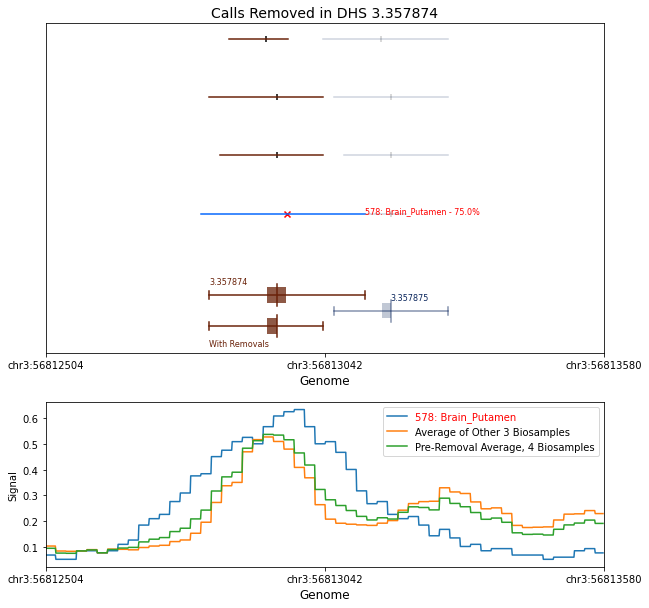

In [199]:
#high score, high distance - 5/11/22, same as above
for i in [9313, 17030, 15211, 15189, 51, 20018, 4620, 12338, 12949, 8294]:
    plotting_removed_calls(i, signal_type='bw', pre_removal_ave=True)

20339
Calls Removed in DHS 7.602532


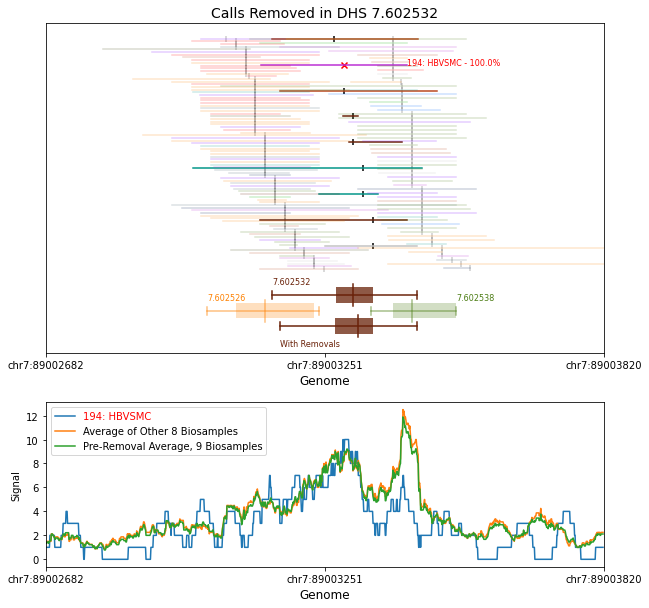

15215
Calls Removed in DHS 2.202536


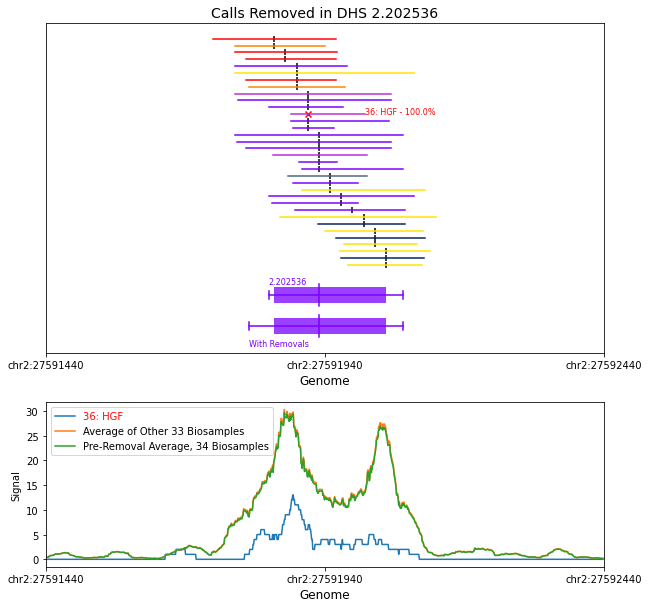

14420
Calls Removed in DHS 22.586095


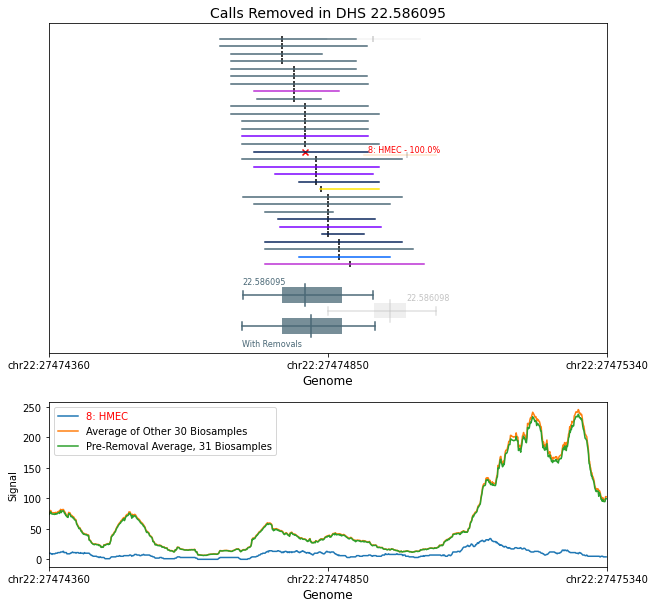

4858
Calls Removed in DHS 2.1991669


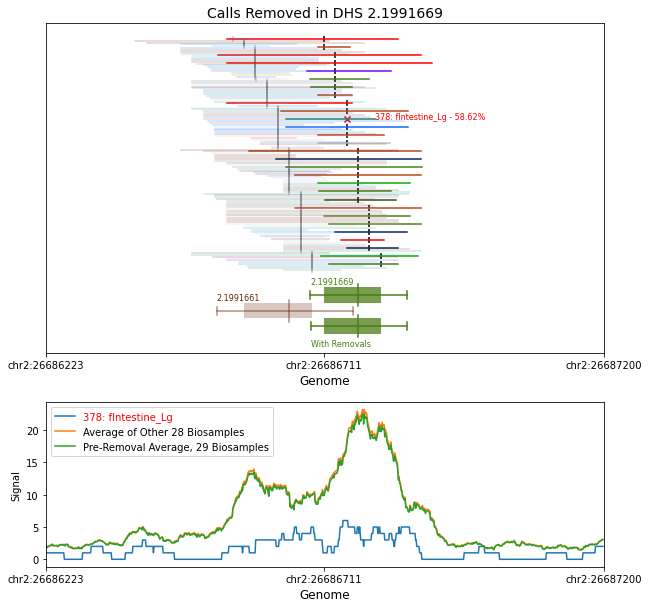

17597
Calls Removed in DHS 18.79293


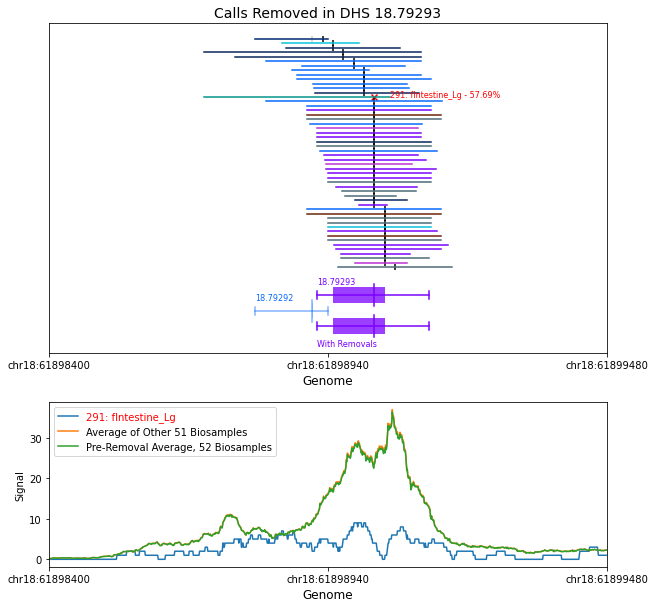

19374
Calls Removed in DHS 2.32145


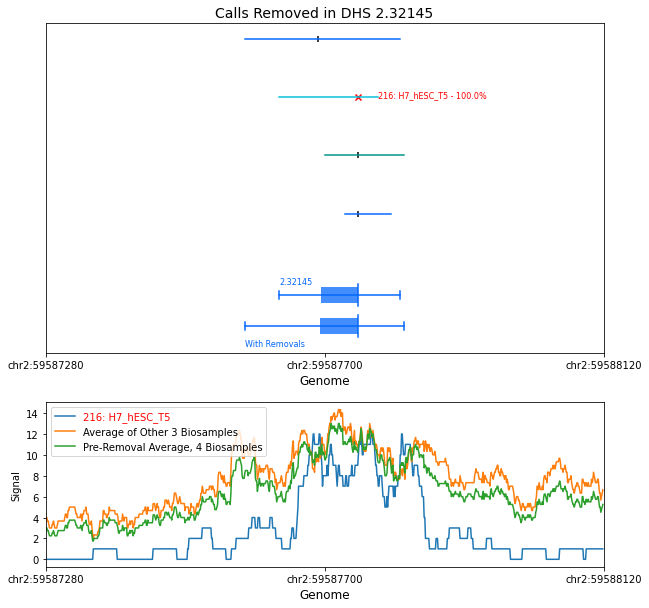

2449
Calls Removed in DHS 15.394667


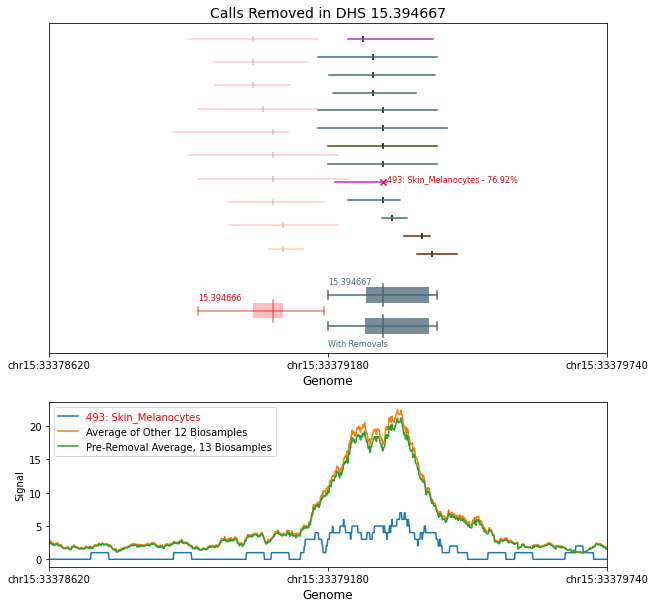

9766
Calls Removed in DHS 3.718675


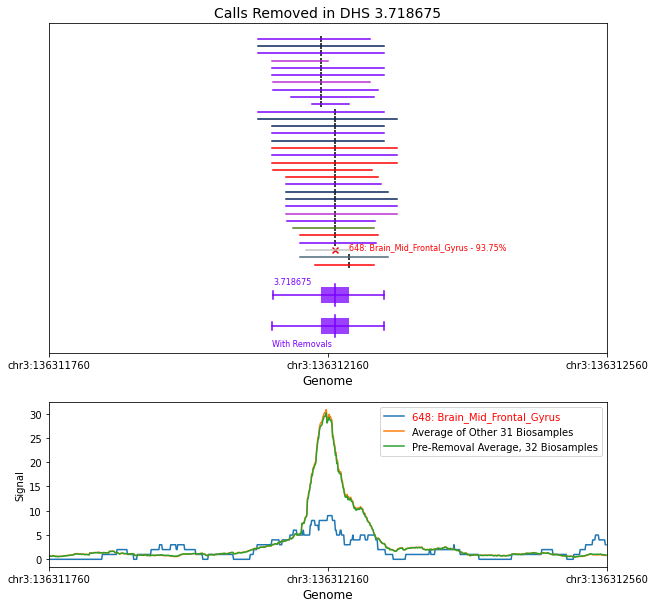

17726
Calls Removed in DHS 20.982064


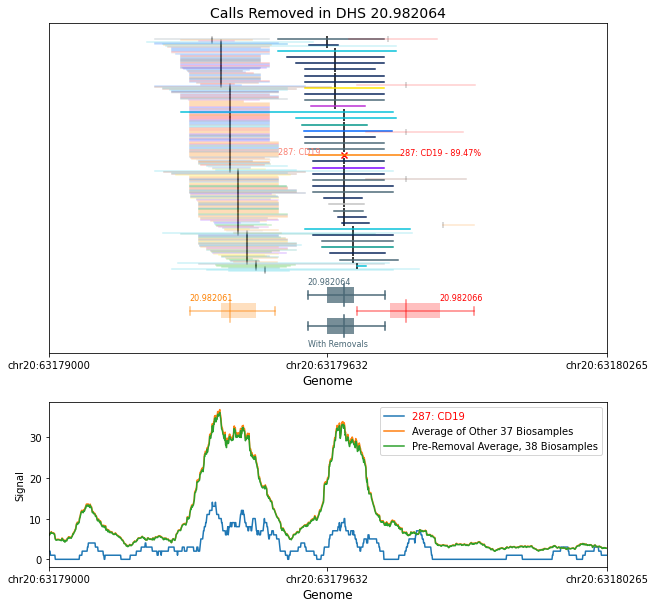

18688
Calls Removed in DHS 17.919018


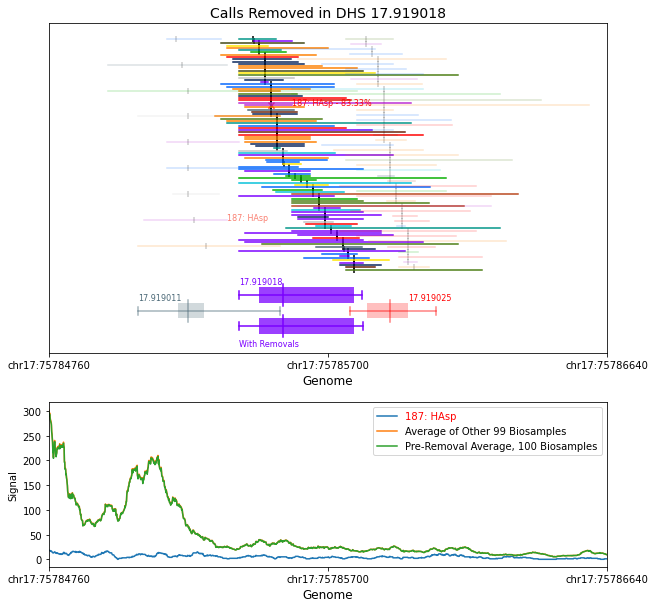

In [195]:
#high score, low distance - 5/11/22
for i in range(10):
    ind = random.randrange(len(b_only))
    print(b_only[ind])
    plotting_removed_calls(b_only[ind], signal_type='bam', pre_removal_ave=True)

Calls Removed in DHS 7.602532


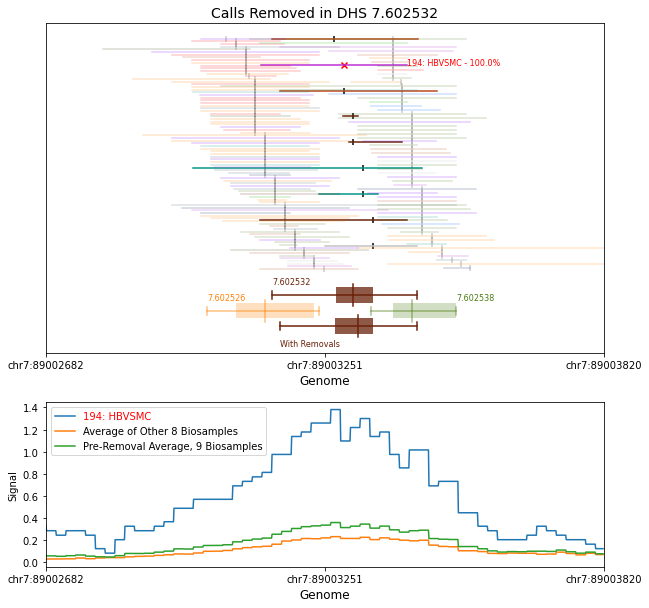

Calls Removed in DHS 2.202536


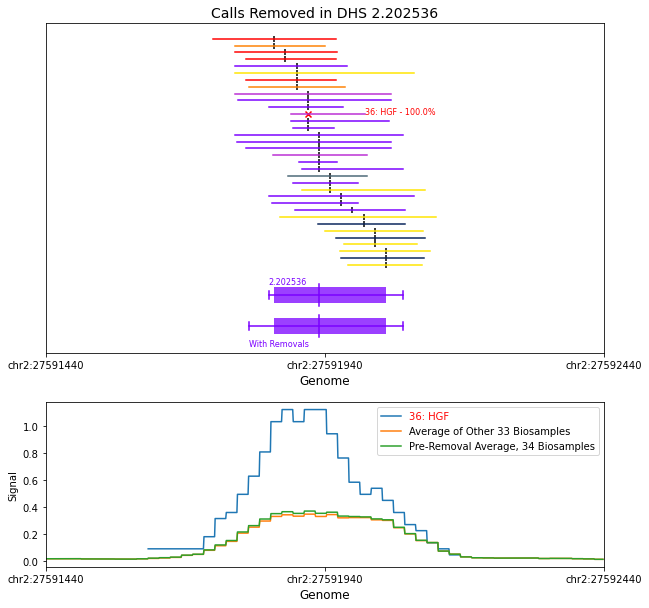

Calls Removed in DHS 22.586095


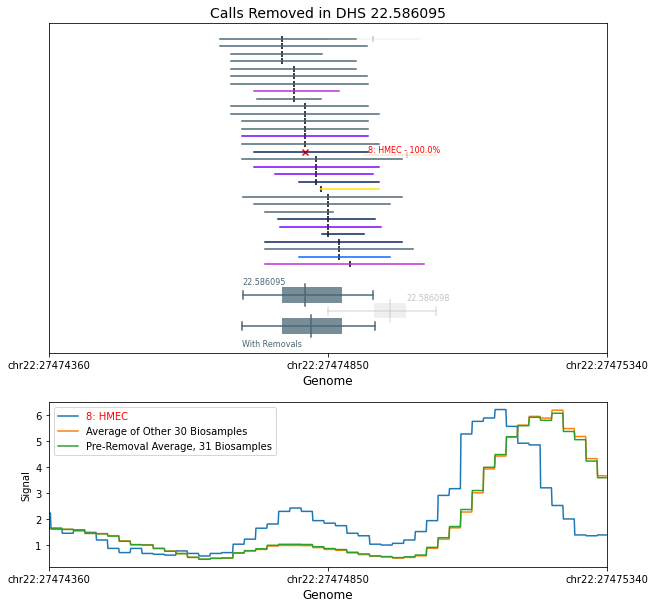

Calls Removed in DHS 2.1991669


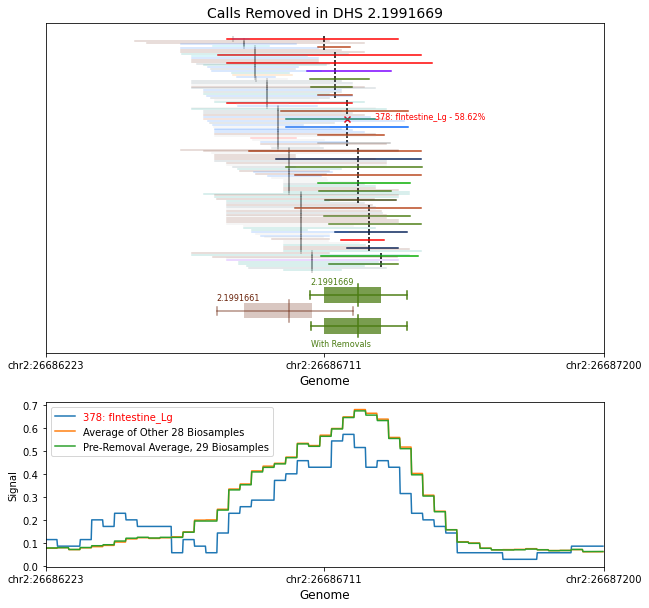

Calls Removed in DHS 18.79293


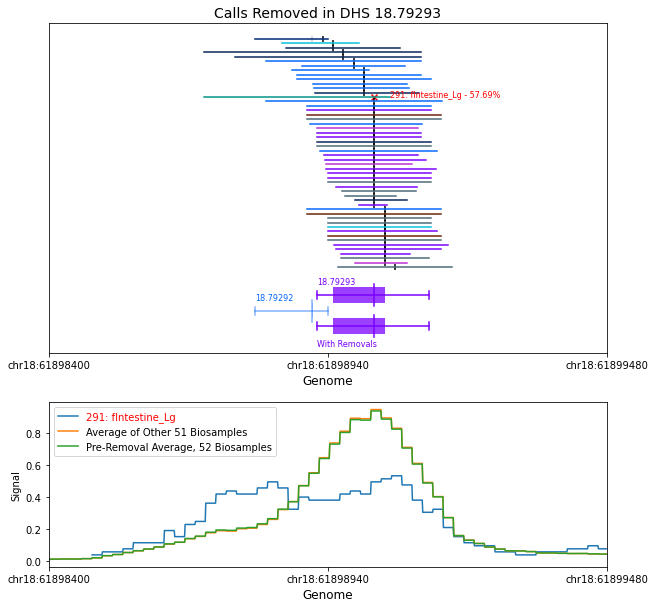

Calls Removed in DHS 2.32145


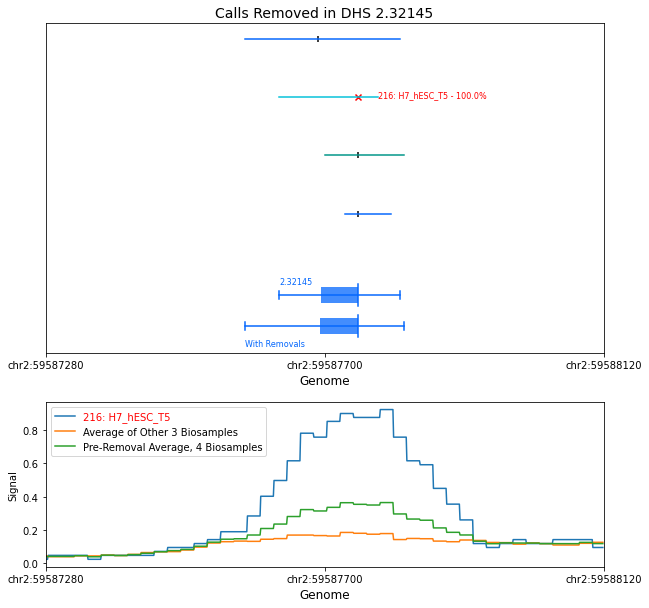

Calls Removed in DHS 15.394667


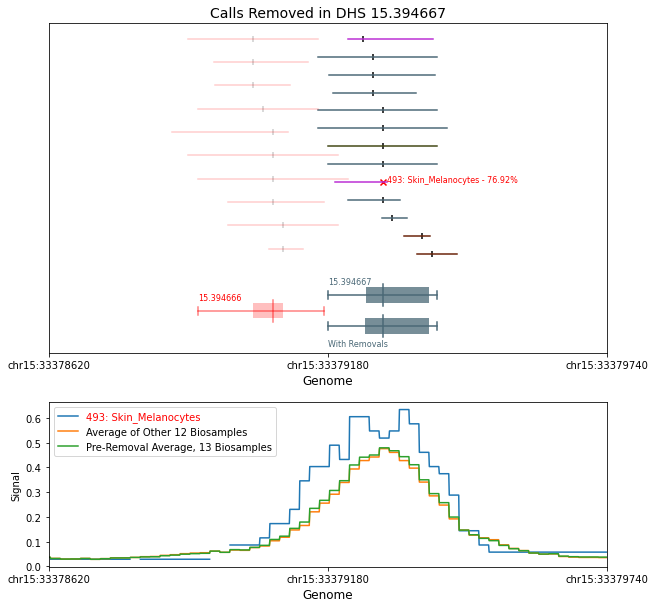

Calls Removed in DHS 3.718675


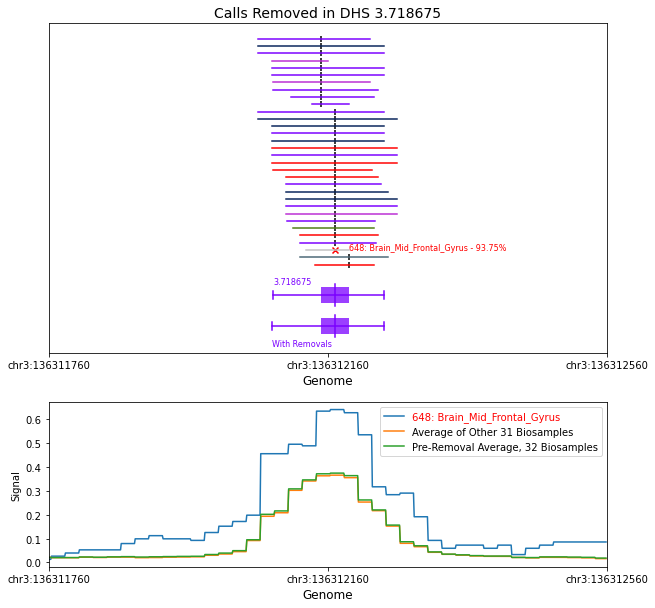

Calls Removed in DHS 20.982064


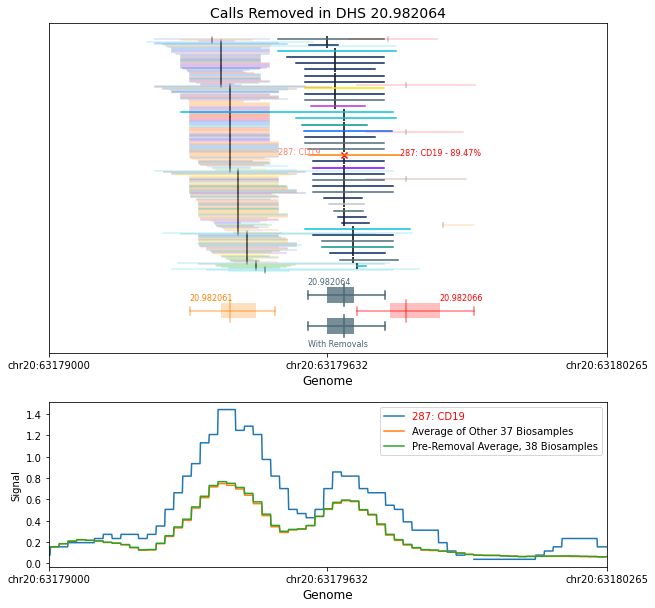

Calls Removed in DHS 17.919018


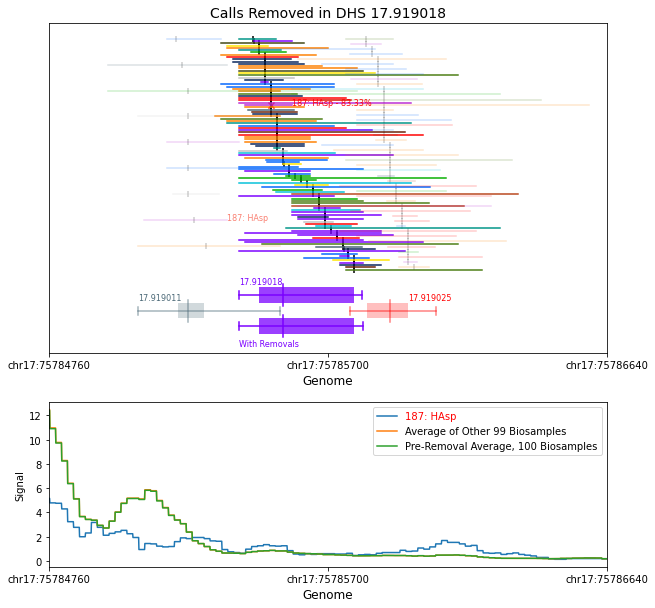

In [197]:
#high score, low distance - 5/11/22, same as above
for i in [20339, 15215, 14420, 4858, 17597, 19374, 2449, 9766, 17726, 18688]:
    plotting_removed_calls(i, signal_type='bw', pre_removal_ave=True)

Calls Removed in DHS 5.952871


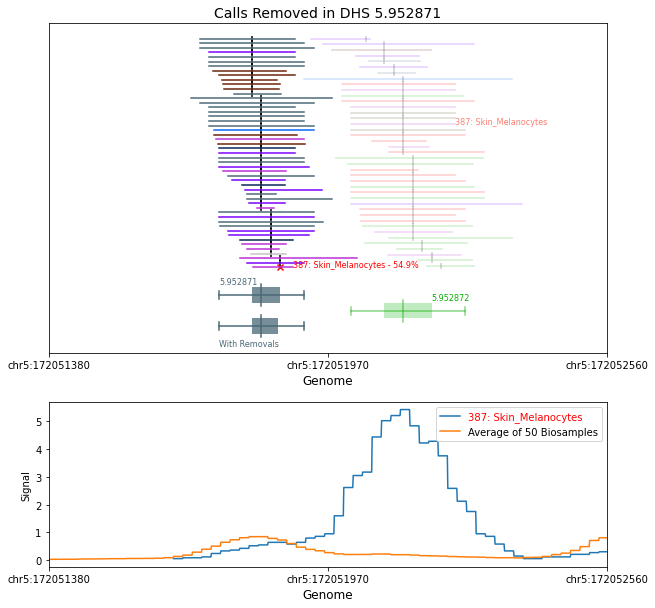

Calls Removed in DHS 3.634808


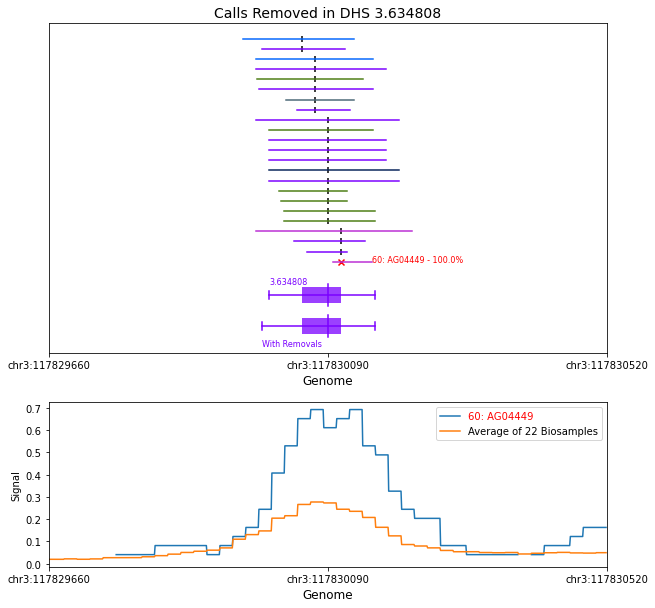

Calls Removed in DHS 7.271579


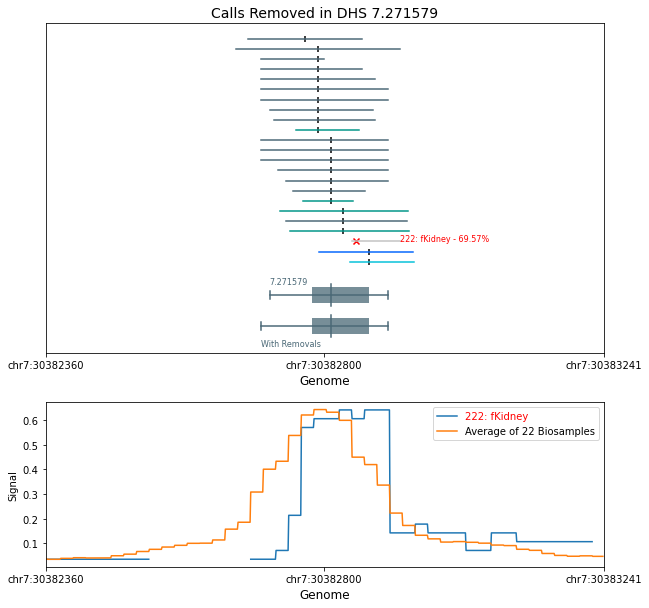

In [78]:
#high score, high distance - 5/6/22
for i in range(3):
    ind = random.randrange(len(a_only))
    plotting_removed_calls(a_only[ind])

Calls Removed in DHS 5.873396


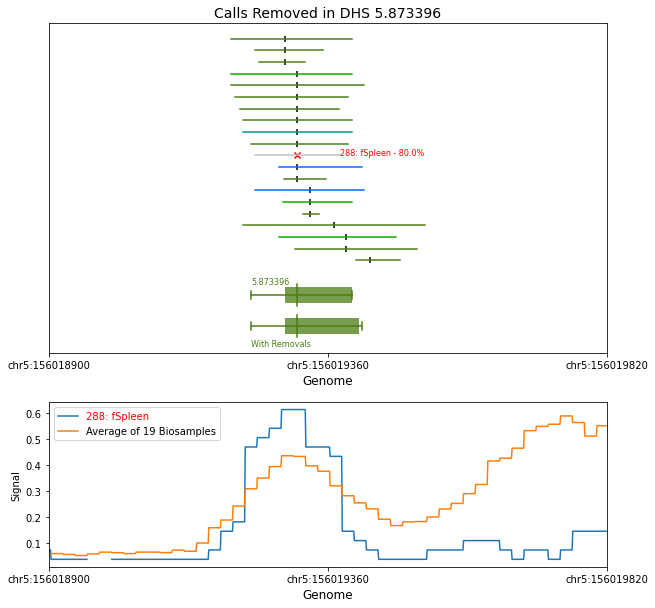

Calls Removed in DHS 18.42362


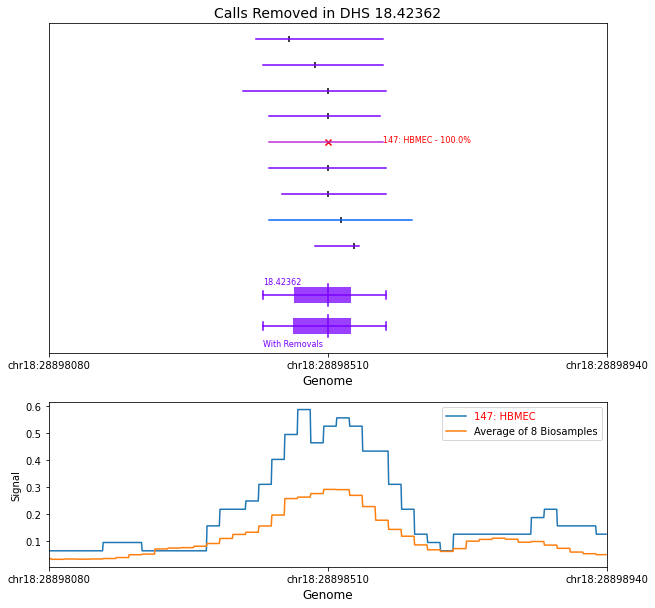

Calls Removed in DHS 11.559099


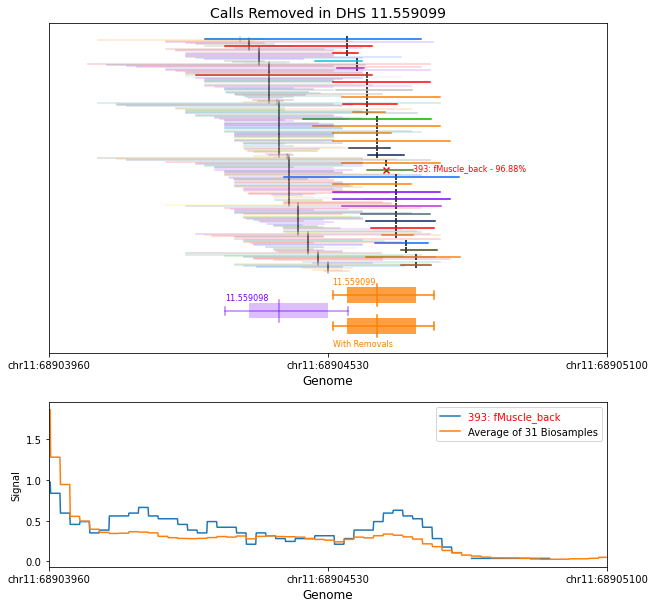

In [79]:
#high score, low distance - 5/6/22
for i in range(3):
    ind = random.randrange(len(b_only))
    plotting_removed_calls(b_only[ind])

Calls Removed in DHS 17.896786


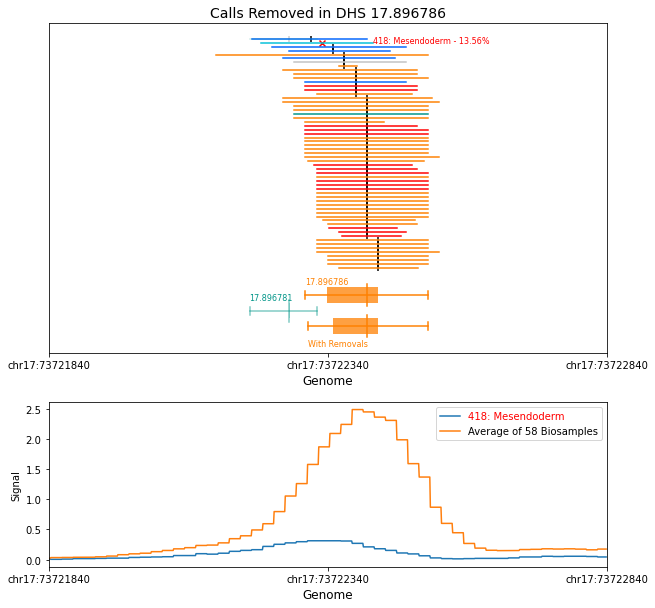

Calls Removed in DHS 9.32592


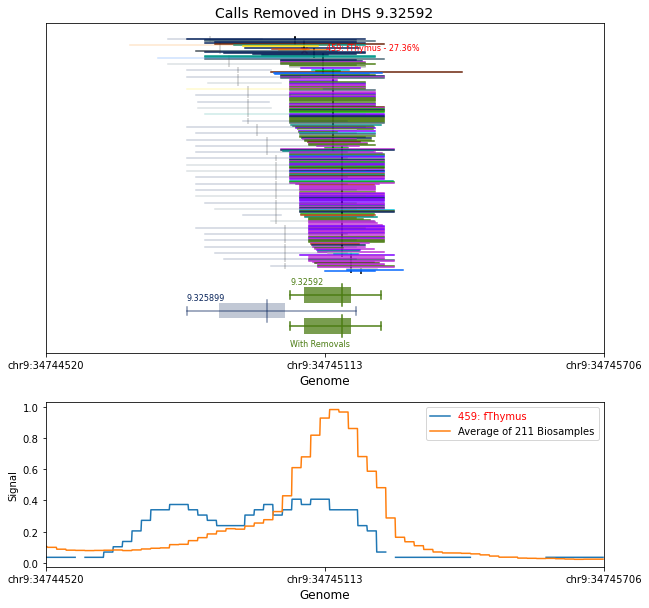

Calls Removed in DHS 16.648087


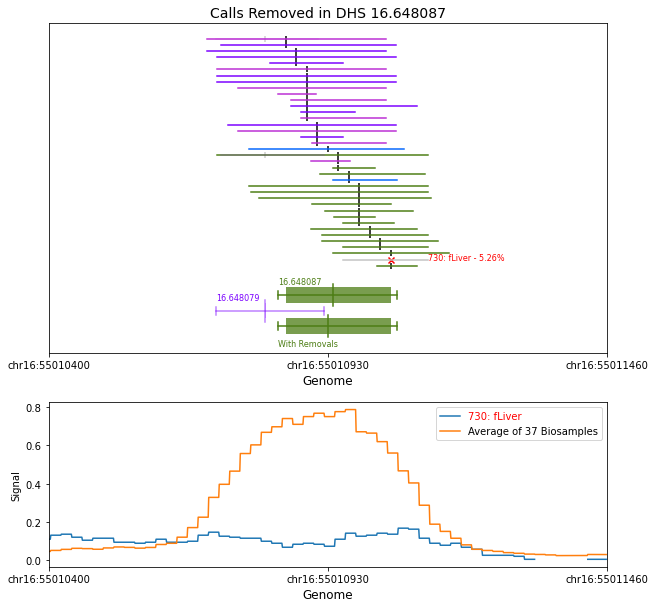

In [80]:
#low score, high distance - 5/6/22
for i in range(3):
    ind = random.randrange(len(c_only))
    plotting_removed_calls(c_only[ind])

Calls Removed in DHS 3.905678


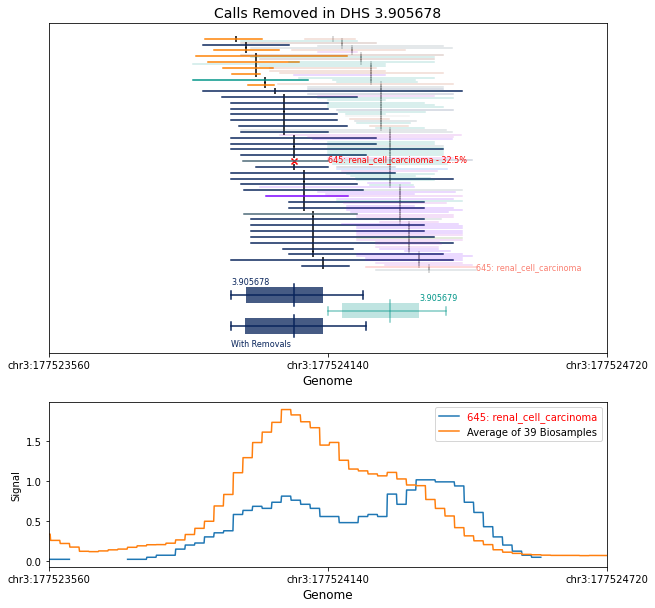

Calls Removed in DHS 11.208646


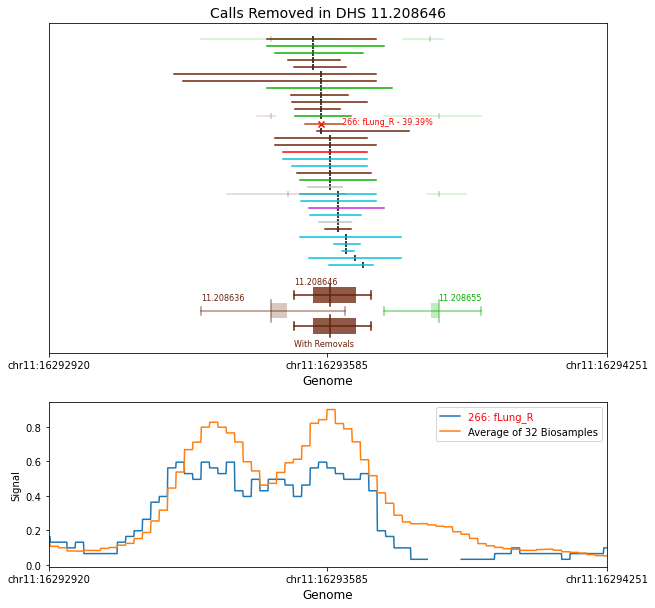

Calls Removed in DHS 10.7808643


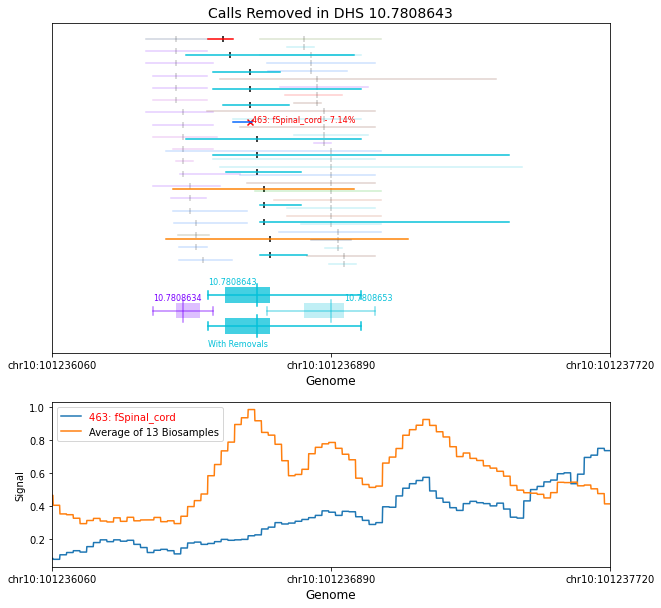

In [81]:
#low score, low distance - 5/6/22
for i in range(3):
    ind = random.randrange(len(d_only))
    plotting_removed_calls(d_only[ind])

In [24]:
score_distance_contingency_75_75 = np.zeros((2, 2), dtype=int)
distance_thresh=75
score_thresh=75
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
#rows - distance
#columns - score
for call in removed_call_cross_percentile_track:
    if call[2] > distance_thresh:
        row_ind=0
    else:
        row_ind=1
    if call[3] > score_thresh:
        col_ind=0
    else:
        col_ind=1
    score_distance_contingency_75_75[row_ind, col_ind]+=1
print(fisher_exact(score_distance_contingency_75_75))
score_distance_contingency_75_75

(0.6483041930611444, 5.086734578774958e-50)


array([[2738, 7810],
       [4219, 7802]])

In [25]:
score_distance_contingency_75_25 = np.zeros((2, 2), dtype=int)
distance_thresh=25
score_thresh=75
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
#rows - distance
#columns - score
for call in removed_call_cross_percentile_track:
    if call[2] > distance_thresh:
        row_ind=0
    else:
        row_ind=1
    if call[3] > score_thresh:
        col_ind=0
    else:
        col_ind=1
    score_distance_contingency_75_25[row_ind, col_ind]+=1
print(fisher_exact(score_distance_contingency_75_25))
score_distance_contingency_75_25

(0.8035359292189039, 6.711542035390012e-08)


array([[ 5830, 13513],
       [ 1127,  2099]])

In [21]:
#for WM talk on 5/23/22
score_distance_contingency_10_75 = np.zeros((2, 2), dtype=int)
distance_thresh=90
score_thresh=10
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
#rows - distance
#columns - score
for call in removed_call_cross_percentile_track:
    if call[2] > distance_thresh:
        row_ind=0
    else:
        row_ind=1
    if call[3] > score_thresh:
        col_ind=1
    else:
        col_ind=0
    score_distance_contingency_10_75[row_ind, col_ind]+=1
print(fisher_exact(score_distance_contingency_10_75))
score_distance_contingency_10_75

(2.1044272347521487, 3.94128959418744e-102)


array([[ 1930,  4094],
       [ 3028, 13517]])

In [303]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [316]:
#score compared to positive or not
score_neighborpos_contingency_75 = np.zeros((2, 2), dtype=int)
score_thresh=75
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
for call in removed_call_cross_percentile_track:
    biosample_ind = call[0]
    DHS_ind = call[1]
    if call[3]>score_thresh:
        col_ind=0
    else:
        col_ind=1
    if ((cycle0_dhs_arr[biosample_ind, DHS_ind+1]) | (cycle0_dhs_arr[biosample_ind, DHS_ind-1])):
        row_ind=0
    else:
        row_ind=1
    score_neighborpos_contingency_75[row_ind, col_ind]+=1
print(fisher_exact(score_neighborpos_contingency_75))
score_neighborpos_contingency_75

(0.6995916040360224, 1.2007466209593493e-28)


array([[ 1735,  5027],
       [ 5222, 10585]])

In [170]:
unique_removed_DHS_inds = np.unique(removed_DHS_inds)

In [171]:
#finding most isolated removed call DHSs
removed_DHSs_and_mindistances = []
for DHS in unique_removed_DHS_inds:
    dhs_df = DHS_metadata.loc[DHS-1:DHS+1]
    min_distance = np.min([(int(dhs_df.iloc[1]['start']) - int(dhs_df.iloc[0]['end'])), 
                           (int(dhs_df.iloc[2]['start']) - int(dhs_df.iloc[1]['end']))])
    removed_DHSs_and_mindistances.append([DHS, min_distance])
removed_DHSs_and_mindistances = np.array(removed_DHSs_and_mindistances)

In [203]:
isolated_removed_DHS_inds = set(removed_DHSs_and_mindistances[:, 0][removed_DHSs_and_mindistances[:, 1]>500])

In [218]:
iso_score_distance_contingency_50_50 = np.zeros((2, 2), dtype=int)
distance_thresh=5
score_thresh=95
#[biosample ind, DHS_ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
#rows - distance
#columns - score
for call in removed_call_cross_percentile_track:
    if call[1] in isolated_removed_DHS_inds:
        if call[2] > distance_thresh:
            row_ind=0
        else:
            row_ind=1
        if call[3] > score_thresh:
            col_ind=0
        else:
            col_ind=1
        iso_score_distance_contingency_50_50[row_ind, col_ind]+=1
print(fisher_exact(iso_score_distance_contingency_50_50))
iso_score_distance_contingency_50_50

(inf, 1.0)


array([[ 105, 1211],
       [   0,    2]])

In [17]:
# biosample_pvals = []
# biosample_ratios = []
# for conting in contingency:
#     if np.min(conting) < 25:
#         pval = mcnemar(conting, exact=True).pvalue
#     else:
#         pval = mcnemar(conting, exact=False, correction=True).pvalue
#     biosample_pvals.append(pval)
#     ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
#     biosample_ratios.append(ratio)
# biosample_pvals = np.array(biosample_pvals)
# biosample_ratios = np.array(biosample_ratios)

/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: invalid value encountered in long_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: invalid value encountered in double_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))
/tmp/ipykernel_96657/2529614997.py:9: RuntimeWarning: divide by zero encountered in long_scalars
  ratio = (np.sum(conting[0, :]) / np.sum(conting[1, :])) / (np.sum(conting[:, 0]) / np.sum(conting[:, 1]))


In [21]:
#calculating start and end positions
def calc_start_end(chunk_info):
    chunk_starts = chunk_info[:, 1].astype(int)
    chunk_ends = chunk_info[:, 2].astype(int) + 1
    min_start = np.min(chunk_starts)
    max_end = np.max(chunk_ends)
    fwhm_pyramid = np.zeros(max_end-min_start, dtype=int)
    for i in range(len(chunk_info)):
        fwhm_pyramid[(chunk_starts[i] - min_start):(chunk_ends[i] - min_start)] += 1
    max_val = np.max(fwhm_pyramid)
    half_max = (max_val/2).astype(float)
    w_pyramid = np.abs(fwhm_pyramid - half_max)
    center_maxposition = np.where(fwhm_pyramid==max_val)[0][int(len(np.where(fwhm_pyramid==max_val)[0])/2)]

    #finding start
    left_w_pyramid = w_pyramid[:center_maxposition]
    left_w_pyramid_min = np.min(left_w_pyramid)
    start = np.where(w_pyramid==left_w_pyramid_min)[0][0] + min_start

    #finding end
    right_w_pyramid = w_pyramid[center_maxposition:]
    right_w_pyramid_min = np.min(right_w_pyramid)
    end = np.where(w_pyramid==right_w_pyramid_min)[0][-1] + min_start

    return start, end

In [22]:
#for each unique DHS with a removed call, find consensus peak and range of peaks before and after flipping
#also finding max distance of removed call in DHS
original_DHS_peak_all = []
new_DHS_peak_all = []

original_DHS_peak_range_all = []
new_DHS_peak_range_all = []

max_removed_distance_all = []
corresponding_DHS_identifiers_for_each_unique_chunks = []

original_unlimited_core_width_all = []
new_unlimited_core_width_all = []

original_limited_core_width_all = []
new_limited_core_width_all = []

original_DHS_width_all = []
new_DHS_width_all = []

ordered_inds_removed_call_DHSs = []

DHS_contingency = np.zeros((2, 2), dtype=int)

for chunk_info in unique_removed_DHS_calls:
    chunk = chunk_info[0][-1]
    ordered_inds_removed_call_DHSs.append(identifier2ind[chunk2identifier[chunk]])
    #start and end of core region (unlimited)
    core_95 = np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
    original_core_start = core_95[0]
    original_core_end = core_95[1]
    original_unlimited_core_width = original_core_end - original_core_start
    original_unlimited_core_width_all.append(original_unlimited_core_width)
    #original DHS start and end
    original_DHS_start, original_DHS_end = calc_start_end(chunk_info)
    original_DHS_width = original_DHS_end - original_DHS_start
    original_DHS_width_all.append(original_DHS_width)
    #limiting core
    if original_core_start < original_DHS_start:
        original_core_start = original_DHS_start
    if original_core_end > original_DHS_end:
        original_core_end = original_DHS_end
    original_limited_core_width = original_core_end - original_core_start
    original_limited_core_width_all.append(original_limited_core_width)
    #DHS identifier
    corresponding_DHS_identifiers_for_each_unique_chunks.append(chunk2identifier[chunk])
    #removed calls
    removed_lns = removed_ln_from_each_chunk[chunk]
    #original peak location
    original_peak = np.median(chunk_info[:, 6].astype(int))
    original_DHS_peak_all.append(original_peak)
    #original range of call peaks
    original_range = np.max(chunk_info[:, 6].astype(int)) - np.min(chunk_info[:, 6].astype(int))
    original_DHS_peak_range_all.append(original_range)
    
    #removing calls
    max_distance = 0
    for ln in removed_lns:
        max_distance = np.max([max_distance, 
                               np.abs(chunk_info[chunk_info[:, 3]==ln][0][6].astype(int) - original_peak)])
        chunk_info = chunk_info[chunk_info[:, 3]!=ln]
    max_removed_distance_all.append(max_distance)
    
    #new core region
    core_95 = np.percentile(chunk_info[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
    new_core_start = core_95[0]
    new_core_end = core_95[1]
    new_unlimited_core_width = new_core_end - new_core_start
    new_unlimited_core_width_all.append(new_unlimited_core_width)
    #new DHS start and end
    new_DHS_start, new_DHS_end = calc_start_end(chunk_info)
    new_DHS_width = new_DHS_end - new_DHS_start
    new_DHS_width_all.append(new_DHS_width)
    #limiting core
    if new_core_start < new_DHS_start:
        new_core_start = new_DHS_start
    if new_core_end > new_DHS_end:
        new_core_end = new_DHS_end
    new_limited_core_width = new_core_end - new_core_start
    new_limited_core_width_all.append(new_limited_core_width)
    #new peak location
    new_peak = np.median(chunk_info[:, 6].astype(int))
    new_DHS_peak_all.append(new_peak)
    #new range of call peaks
    new_range = np.max(chunk_info[:, 6].astype(int)) - np.min(chunk_info[:, 6].astype(int))
    new_DHS_peak_range_all.append(new_range)
    
    if new_limited_core_width < original_limited_core_width:
        col_ind = 0
    else:
        col_ind = 1
    if new_DHS_width < original_DHS_width:
        row_ind = 0
    else:
        row_ind = 1
    
    DHS_contingency[row_ind, col_ind]+=1
    

ordered_inds_removed_call_DHSs = np.array(ordered_inds_removed_call_DHSs)
original_DHS_peak_all = np.array(original_DHS_peak_all)
new_DHS_peak_all = np.array(new_DHS_peak_all)
original_DHS_peak_range_all = np.array(original_DHS_peak_range_all)
new_DHS_peak_range_all = np.array(new_DHS_peak_range_all)
max_removed_distance_all = np.array(max_removed_distance_all)
corresponding_DHS_identifiers_for_each_unique_chunks = np.array(corresponding_DHS_identifiers_for_each_unique_chunks)
original_unlimited_core_width_all = np.array(original_unlimited_core_width_all)
new_unlimited_core_width_all = np.array(new_unlimited_core_width_all)
original_limited_core_width_all = np.array(original_limited_core_width_all)
new_limited_core_width_all = np.array(new_limited_core_width_all)
original_DHS_width_all = np.array(original_DHS_width_all)
new_DHS_width_all = np.array(new_DHS_width_all)

In [23]:
DHS_contingency, np.sum(DHS_contingency)

(array([[ 1685,  1247],
        [ 4672, 12870]]),
 20474)

In [120]:
odds_ratio, pval = fisher_exact(DHS_contingency, alternative='two-sided')
print(odds_ratio, pval)

3.7222810773253068 8.218314343898318e-227


/tmp/ipykernel_23933/2259103591.py:12: RuntimeWarning: invalid value encountered in true_divide
  axes[1].hist((new_DHS_peak_range_all-original_DHS_peak_range_all)/original_DHS_peak_range_all*100, bins=32)
/tmp/ipykernel_23933/2259103591.py:18: RuntimeWarning: invalid value encountered in true_divide
  axes[2].hist((new_unlimited_core_width_all-original_unlimited_core_width_all)/original_unlimited_core_width_all*100, bins=32)


DHS Composition Changes as Individual Calls are Removed


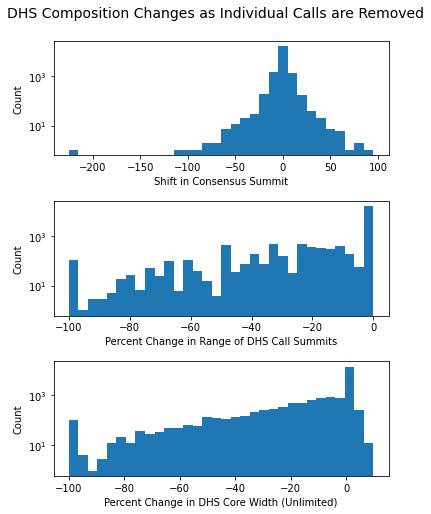

In [83]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(6,8))
# fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.4)
fig.patch.set_facecolor('white')

axes[0].hist(new_DHS_peak_all-original_DHS_peak_all, bins=32, align='left')
# axes[0].set_xlim([0, 400])
axes[0].set_xlabel('Shift in Consensus Summit')
axes[0].set_ylabel('Count')
axes[0].set_yscale('log')

axes[1].hist((new_DHS_peak_range_all-original_DHS_peak_range_all)/original_DHS_peak_range_all*100, bins=32)
# axes[1].set_xlim([0, 1])
axes[1].set_xlabel('Percent Change in Range of DHS Call Summits')
axes[1].set_ylabel('Count')
axes[1].set_yscale('log')

axes[2].hist((new_unlimited_core_width_all-original_unlimited_core_width_all)/original_unlimited_core_width_all*100, bins=32)
axes[2].set_xlabel('Percent Change in DHS Core Width (Unlimited)')
axes[2].set_ylabel('Count')
axes[2].set_yscale('log')

title = 'DHS Composition Changes as Individual Calls are Removed'
plt.suptitle(title, fontsize=14, x=0.5, y=0.94)
today = date.today()
# plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
print(title)

In [130]:
#full DHS width greater than (or equal to) 20 bp increase
(new_DHS_width_all-original_DHS_width_all)[(new_DHS_width_all-original_DHS_width_all)>=20].shape

(1490,)

In [131]:
#full DHS width greater than (or equal to) 20 bp decrease
(new_DHS_width_all-original_DHS_width_all)[(new_DHS_width_all-original_DHS_width_all)<=-20].shape

(832,)

In [139]:
#core DHS width greater than (or equal to) 20 bp increase
(new_limited_core_width_all-original_limited_core_width_all)[(new_limited_core_width_all-original_limited_core_width_all)>=20].shape

(40,)

In [140]:
#core DHS width greater than (or equal to) 20 bp decrease
(new_limited_core_width_all-original_limited_core_width_all)[(new_limited_core_width_all-original_limited_core_width_all)<=-20].shape

(2004,)

In [43]:
len((new_DHS_width_all-original_DHS_width_all)[(((new_DHS_width_all-original_DHS_width_all)<10) & 
                                                ((new_DHS_width_all-original_DHS_width_all)>-10))])/len(new_DHS_width_all)*100

80.8293445345316

In [45]:
len((new_DHS_width_all-original_DHS_width_all)[((new_DHS_width_all-original_DHS_width_all)>=10)])/len(new_DHS_width_all)*100

12.142229168701768

In [42]:
np.median((new_DHS_width_all-original_DHS_width_all)[(new_DHS_width_all-original_DHS_width_all)<=-10])

-20.0

In [48]:
len((new_limited_core_width_all-original_limited_core_width_all)[(((new_limited_core_width_all-original_limited_core_width_all)<10) & 
                                                                  ((new_limited_core_width_all-original_limited_core_width_all)>-10))])/len(new_limited_core_width_all)*100

78.40675979290808

In [47]:
len((new_limited_core_width_all-original_limited_core_width_all)[(new_limited_core_width_all-original_limited_core_width_all)<=-10])/len(new_limited_core_width_all)*100

21.187848002344438

In [39]:
np.median((new_limited_core_width_all-original_limited_core_width_all)[(new_limited_core_width_all - 
                                                                        original_limited_core_width_all)>=10])

18.0

In [26]:
wilcoxon(original_DHS_width_all, new_DHS_width_all)

WilcoxonResult(statistic=10531740.0, pvalue=1.980914996434122e-78)

In [27]:
wilcoxon(original_limited_core_width_all, new_limited_core_width_all)

WilcoxonResult(statistic=16958110.0, pvalue=0.0)

/tmp/ipykernel_61132/851845960.py:34: RuntimeWarning: invalid value encountered in true_divide
  ax3.hist((new_limited_core_width_all-original_limited_core_width_all)/original_limited_core_width_all*100, bins=32)


DHS Structure Changes as Individual Calls are Removed


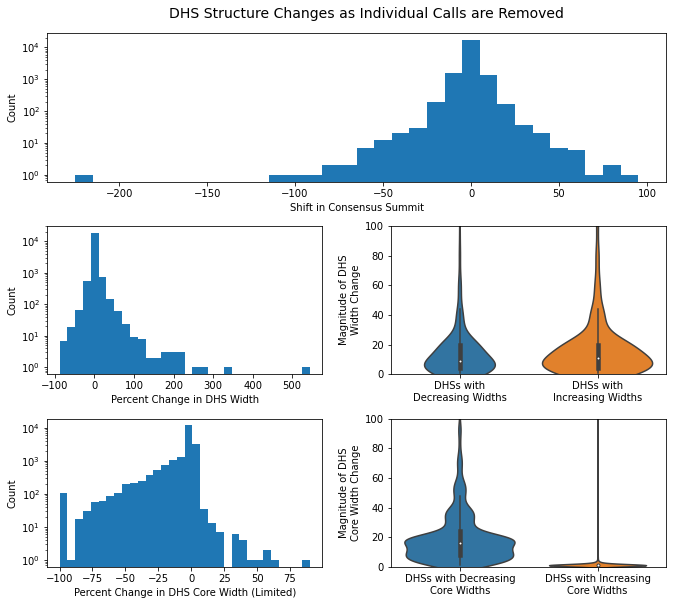

In [24]:
fig = plt.figure(figsize=(14,8))
fig.patch.set_facecolor('white')
ax0 = plt.subplot2grid(shape=(3, 3), loc=(0, 0), colspan=2)
ax1 = plt.subplot2grid(shape=(3, 3), loc=(1, 0), colspan=1)
ax2 = plt.subplot2grid(shape=(3, 3), loc=(1, 1), colspan=1)
ax3 = plt.subplot2grid(shape=(3, 3), loc=(2, 0), colspan=1)
ax4 = plt.subplot2grid(shape=(3, 3), loc=(2, 1), colspan=1)
fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.25, hspace=0.3)


ax0.hist(new_DHS_peak_all-original_DHS_peak_all, bins=32, align='left')
# ax0.set_xlim([0, 400])
ax0.set_xlabel('Shift in Consensus Summit')
ax0.set_ylabel('Count')
ax0.set_yscale('log')

ax1.hist((new_DHS_width_all-original_DHS_width_all)/original_DHS_width_all*100, bins=32)
# ax1.set_xlim([0, 1])
ax1.set_xlabel('Percent Change in DHS Width')
ax1.set_ylabel('Count')
ax1.set_yscale('log')


positive_dhs_changes = (new_DHS_width_all-original_DHS_width_all)[(new_DHS_width_all-original_DHS_width_all)>0]
negative_dhs_changes = (new_DHS_width_all-original_DHS_width_all)[(new_DHS_width_all-original_DHS_width_all)<0]
dhs_changes_y = np.abs(np.append(negative_dhs_changes, positive_dhs_changes))
dhs_changes_x = np.append(np.zeros(len(negative_dhs_changes)), np.ones(len(positive_dhs_changes)))
sns.violinplot(x=dhs_changes_x, y=dhs_changes_y, ax=ax2, scale='count', gridsize=15000, linewidth=1.5)
ax2.set_ylim([0, 100])
ax2.set_xticklabels(['DHSs with\nDecreasing Widths', 'DHSs with\nIncreasing Widths'])
ax2.set_ylabel('Magnitude of DHS\nWidth Change')

ax3.hist((new_limited_core_width_all-original_limited_core_width_all)/original_limited_core_width_all*100, bins=32)
ax3.set_xlabel('Percent Change in DHS Core Width (Limited)')
ax3.set_ylabel('Count')
ax3.set_yscale('log')

positive_core_changes = (new_limited_core_width_all-original_limited_core_width_all)[(new_limited_core_width_all-original_limited_core_width_all)>0]
negative_core_changes = (new_limited_core_width_all-original_limited_core_width_all)[(new_limited_core_width_all-original_limited_core_width_all)<0]
core_changes_y = np.abs(np.append(negative_core_changes, positive_core_changes))
core_changes_x = np.append(np.zeros(len(negative_core_changes)), np.ones(len(positive_core_changes)))
sns.violinplot(x=core_changes_x, y=core_changes_y, ax=ax4, scale='count', gridsize=15000, linewidth=1.5)
ax4.set_ylim([0, 100])
ax4.set_xticklabels(['DHSs with Decreasing\nCore Widths', 'DHSs with Increasing\nCore Widths'])
ax4.set_ylabel('Magnitude of DHS\nCore Width Change')

title = 'DHS Structure Changes as Individual Calls are Removed'
plt.suptitle(title, fontsize=14, x=0.35, y=1.02)
today = date.today()
# plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
print(title)

In [328]:
removed_call_nums_each_biosample_top100maxdistance[removed_call_nums_each_biosample_top100maxdistance>3]

array([8, 6, 5, 4])

In [327]:
biosample_df.loc[np.arange(733)[removed_call_nums_each_biosample_top100maxdistance>3]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
187,188,HAsp,NaN,ENCSR000ENB,ENCLB454ZZZ,ENCBS995OME,AG4073,LN3185,DS14794,DS14790,...,minElute,120.0,41.8,16800000.0,Buffer A,2010-05-06,32231827,0.4291,41041,40787
569,570,SJSA1,NaN,ENCSR620WAR,ENCLB925FNH,ENCBS327EZG,AG3978,LN20838A,DS24241A,DS24235A,...,Sucrose,120.0,50,8400000.0,PBS+A,2013-07-09,40853966,0.3684,53016,52024
715,716,DE,Primitive / embryonic,ENCSR166KPV,ENCLB393NTX,ENCBS088TSK,AG6944,LN43606A,DS55923A,DS39603C,...,NaN,NaN,1.1,540000.0,NaN,2017-01-05,457497776,0.5445,312848,307202
719,720,fBone_arm_left,NaN,ENCSR976XOY,ENCLB060BWD,ENCBS104ACH,AG7434,LN44780B,DS39408B,NaN,...,NaN,NaN,0.53,200000.0,A+Sucrose,NaN,198205332,0.4059,113852,110550


In [108]:
removed_call_nums_each_biosample_top100maxdistance = np.zeros(733, dtype=int)
for i in np.argsort(max_removed_distance_all)[-100:]:
    chunk = unique_removed_DHS_calls[i][0][-1]
    removed_lns = removed_ln_from_each_chunk[chunk]
    for ln in removed_lns:
        biosample_ind = np.where(all_ln_stripped==ln)[0][0]
        removed_call_nums_each_biosample_top100maxdistance[biosample_ind]+=1

Text(0.5, 1.0, 'Calls Removed from Each Biosample\nTop 100 Max Distance Cases')

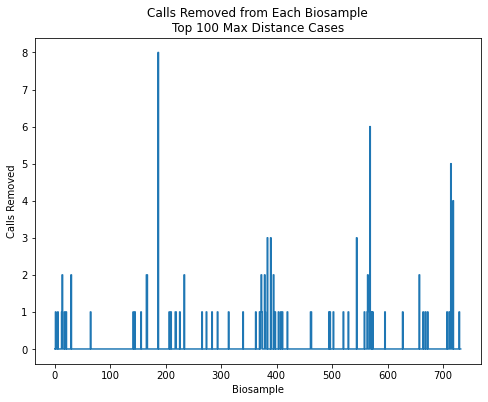

In [325]:
fig, axes = plt.subplots(figsize=(8,6))
fig.patch.set_facecolor('white')

axes.step(np.arange(733), removed_call_nums_each_biosample_top100maxdistance)
axes.set_xlabel('Biosample')
axes.set_ylabel('Calls Removed')
axes.set_title('Calls Removed from Each Biosample\nTop 100 Max Distance Cases')

Text(0.5, 1.0, 'Calls Removed from Each Biosample and DCC SPOT Scores\nTop 100 Max Distance Cases')

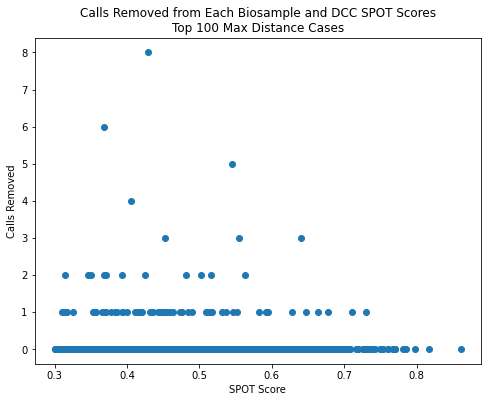

In [326]:
spot_scores = np.array(biosample_df['DCC SPOT score'])
fig, axes = plt.subplots(figsize=(8,6))
fig.patch.set_facecolor('white')

axes.scatter(spot_scores, removed_call_nums_each_biosample_top100maxdistance)

axes.set_xlabel('SPOT Score')
axes.set_ylabel('Calls Removed')
axes.set_title('Calls Removed from Each Biosample and DCC SPOT Scores\nTop 100 Max Distance Cases')

In [23]:
def get_bam_signal(bam_file, chrm, start, end):
    #initialize with array of zeros from start to end
    bam_signal = np.zeros(end-start, dtype=int)
    #collect reads from bam
    bp_reads = bam_file.pileup(chrm, start, end, multiple_iterators=False, truncate=True)
    #reads at each bp position
    for bp_read in bp_reads:
        position = bp_read.reference_pos
        #set number of reads at each position
        bam_signal[position-start] = bp_read.nsegments
    return bam_signal

In [24]:
def plotting_removed_calls(i, 
                           unique_removed_DHS_calls=unique_removed_DHS_calls, 
                           removed_ln_from_each_chunk=removed_ln_from_each_chunk, 
                           buffer=300, 
                           norm=False, 
                           pre_removal_ave=False,
                           signal_type='bam',
                           bam_norm=True,
                           pre_removal_view=False):
    dhs_calls = unique_removed_DHS_calls[i]
    chunk = dhs_calls[0][-1]
    chrm = dhs_calls[0][0]
    removed_lns = removed_ln_from_each_chunk[chunk]
    lns = dhs_calls[:, 3]
    scores = dhs_calls[:, 4].astype(float)
    mean_score = np.mean(scores)
    peaks = dhs_calls[:, 6].astype(int)
    starts = dhs_calls[:, 1].astype(int)
    # dhs_start = np.min(starts)
    ends = dhs_calls[:, 2].astype(int)
    # dhs_end = np.max(ends)
    # consensus_peak = np.median(peaks)
    # core_95 = np.percentile(peaks, [2.5, 97.5])


    #identifier/DHS of interest
    identifier = chunk2identifier[chunk]
    DHS_df = DHS_metadata[DHS_metadata['identifier']==identifier]
    DHS_ind = DHS_df.index[0]
    
    core_start = np.max([np.array(DHS_df['core_start']).astype(int)[0], 
                         np.array(DHS_df['start']).astype(int)[0]])
    core_end = np.min([np.array(DHS_df['core_end']).astype(int)[0], 
                       np.array(DHS_df['end']).astype(int)[0]])
    core_start_end = np.array([core_start, 
                               core_end])

    DHS_start_end = np.array([np.array(DHS_df['start']).astype(int)[0], 
                              np.array(DHS_df['end']).astype(int)[0]])

    DHS_peak = np.array(DHS_df['summit']).astype(int)[0]

    DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind]
    
    #new DHS structure
    for ln in removed_lns:
        dhs_calls = dhs_calls[dhs_calls[:, 3]!=ln] # removing calls
    new_core_start, new_core_end = np.percentile(dhs_calls[:, 6].astype(int), [2.5, 97.5]).astype(int) #removed ceil function to better match metadata
    new_DHS_start, new_DHS_end = calc_start_end(dhs_calls)
    if new_core_start < new_DHS_start:
        new_core_start = new_DHS_start
    if new_core_end > new_DHS_end:
        new_core_end = new_DHS_end
    new_DHS_peak = np.median(dhs_calls[:, 6].astype(int))
    DHS_top_comp_new = mixture_all_cycles_top_comp[1, DHS_ind]
    

    #DHS to right
    right_DHS_df = DHS_metadata.loc[[DHS_ind+1]]
    right_identifier = np.array(right_DHS_df['identifier'])[0]
    
    right_core_start = np.max([np.array(right_DHS_df['core_start']).astype(int)[0], 
                               np.array(right_DHS_df['start']).astype(int)[0]])
    right_core_end = np.min([np.array(right_DHS_df['core_end']).astype(int)[0], 
                             np.array(right_DHS_df['end']).astype(int)[0]])
    
    right_core_start_end = np.array([right_core_start, 
                                     right_core_end])
    right_DHS_start_end = np.array([np.array(right_DHS_df['start']).astype(int)[0], 
                                    np.array(right_DHS_df['end']).astype(int)[0]])
    right_DHS_peak = np.array(right_DHS_df['summit']).astype(int)[0]
    right_DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind+1]

    #DHS to left
    left_DHS_df = DHS_metadata.loc[[DHS_ind-1]]
    left_identifier = np.array(left_DHS_df['identifier'])[0]
    
    left_core_start = np.max([np.array(left_DHS_df['core_start']).astype(int)[0], 
                              np.array(left_DHS_df['start']).astype(int)[0]])
    left_core_end = np.min([np.array(left_DHS_df['core_end']).astype(int)[0], 
                            np.array(left_DHS_df['end']).astype(int)[0]])
    
    left_core_start_end = np.array([left_core_start, 
                                    left_core_end])
    left_DHS_start_end = np.array([np.array(left_DHS_df['start']).astype(int)[0], 
                                   np.array(left_DHS_df['end']).astype(int)[0]])
    left_DHS_peak = np.array(left_DHS_df['summit']).astype(int)[0]
    left_DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind-1]


    dhs_height = 0.05
    dhs_bot = 0.05

    #plotting
    fig, axes = plt.subplots(nrows=2, figsize=(10,10), gridspec_kw={'height_ratios': np.array([2, 1])})
    fig.patch.set_facecolor('white')

    right = False
#     right=True
    if ((right_DHS_start_end[0] < np.max(ends)) | right):
        right = True
        c = color[right_DHS_top_comp_original]
        adjustment = 0
        if right_core_start_end[1] - right_core_start_end[0] == 0:
            adjustment = 2
        right_dhs_rect = patches.Rectangle((right_core_start_end[0], dhs_bot),
                                            right_core_start_end[1] - right_core_start_end[0] + adjustment, 
                                            dhs_height,
                                            facecolor=c,
                                            alpha=0.25)
        axes[0].add_patch(right_dhs_rect)
        axes[0].text(right_core_start_end[1], dhs_bot + dhs_height + 0.01, right_identifier, fontsize=8, c=c)


        #plotting range of DHS
        axes[0].plot(np.arange(right_DHS_start_end[0], right_DHS_start_end[1] + 1), 
                     np.ones(right_DHS_start_end[1] - right_DHS_start_end[0] + 1)*(dhs_height / 2 + dhs_bot),
                     c=c,
                     alpha=0.5)
        axes[0].plot([right_DHS_start_end[0], right_DHS_start_end[0]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([right_DHS_start_end[1], right_DHS_start_end[1]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([right_DHS_peak, right_DHS_peak], 
                     [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                     c=c,
                     alpha=0.5)

    left = False
#     left=True
    if ((left_DHS_start_end[1] > np.min(starts)) | left):
        left = True
        c = color[left_DHS_top_comp_original]
        adjustment = 0
        if left_core_start_end[1] - left_core_start_end[0] == 0:
            adjustment = 2
        left_dhs_rect = patches.Rectangle((left_core_start_end[0], dhs_bot),
                                           left_core_start_end[1] - left_core_start_end[0] + adjustment, 
                                           dhs_height,
                                           facecolor=c,
                                           alpha=0.25)
        axes[0].add_patch(left_dhs_rect)
        axes[0].text(left_DHS_start_end[0], dhs_bot + dhs_height + 0.01, left_identifier, fontsize=8, c=c)

        #plotting range of DHS
        axes[0].plot(np.arange(left_DHS_start_end[0], left_DHS_start_end[1] + 1), 
                     np.ones(left_DHS_start_end[1] - left_DHS_start_end[0] + 1)*(dhs_height / 2 + dhs_bot),
                     c=c,
                     alpha=0.5)
        axes[0].plot([left_DHS_start_end[0], left_DHS_start_end[0]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([left_DHS_start_end[1], left_DHS_start_end[1]], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c,
                     alpha=0.5)
        axes[0].plot([left_DHS_peak, left_DHS_peak], 
                     [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                     c=c,
                     alpha=0.5)

    #DHS structure
    c = color[DHS_top_comp_original]

    adjustment = 0
    if core_start_end[1] - core_start_end[0] == 0:
        adjustment = 2
    
    dhs_bot = 0.1

    dhs_rect = patches.Rectangle((core_start_end[0], dhs_bot),
                                  core_start_end[1] - core_start_end[0] + adjustment, 
                                  dhs_height,
                                  facecolor=c,
                                  alpha=0.75)
    axes[0].add_patch(dhs_rect)
    axes[0].text(DHS_start_end[0], dhs_bot + dhs_height + 0.01, identifier, fontsize=8, c=c)


    #plotting range of DHS
    axes[0].plot(np.arange(DHS_start_end[0], DHS_start_end[1] + 1), 
                 np.ones(DHS_start_end[1] - DHS_start_end[0] + 1)*(dhs_height / 2 + dhs_bot),
                 c=c)
    axes[0].plot([DHS_start_end[0], DHS_start_end[0]], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c)
    axes[0].plot([DHS_start_end[1], DHS_start_end[1]], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c)
    axes[0].plot([DHS_peak, DHS_peak], 
                 [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                 c=c)
    
    if not pre_removal_view:
        #new DHS structure
        c = color[DHS_top_comp_new]

        adjustment = 0
        if new_core_end - new_core_start == 0:
            adjustment = 2

        dhs_bot = 0.0

        new_dhs_rect = patches.Rectangle((new_core_start, dhs_bot),
                                          new_core_end - new_core_start + adjustment, 
                                          dhs_height,
                                          facecolor=c,
                                          alpha=0.75)
        axes[0].add_patch(new_dhs_rect)
        axes[0].text(new_DHS_start, dhs_bot - 0.04, 'With Removals', fontsize=8, c=c)


        #plotting range of DHS
        axes[0].plot(np.arange(new_DHS_start, new_DHS_end + 1), 
                     np.ones(new_DHS_end - new_DHS_start + 1)*(dhs_height / 2 + dhs_bot),
                     c=c)
        axes[0].plot([new_DHS_start, new_DHS_start], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c)
        axes[0].plot([new_DHS_end, new_DHS_end], 
                     [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                     c=c)
        axes[0].plot([new_DHS_peak, new_DHS_peak], 
                     [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                     c=c)


    plt_start = np.min(starts)-buffer
    plt_end = np.max(ends)+buffer

    if right:
        plt_end = np.max([plt_end, right_DHS_start_end[1]+buffer])

    if left:
        plt_start = np.min([plt_start, left_DHS_start_end[0]-buffer])

        

    #plotting calls
    num_calls = len(peaks)
    used_biosamples_for_signal = []
    used_biosamples_for_average_signal = []
    average_signal_other_calls = np.array([])
    pre_removal_signal_ave = np.array([])
    signal_at_peaks = []
    signal_count = 0
    possible_styles = ['-', '--', '-.', ':']
    #to keep track of which signal plot is first
#     ordered_removed_lns = []
    for ln, peak, start, end, ind, score in zip(lns, peaks, starts, ends, range(len(peaks)), scores):
        
        null_signal = False
        
        if ((ln in removed_lns) and (not pre_removal_view)):
            c = 'r'
            m = 'x'
        else:
            c = 'k'
            m = '|'
        biosample_ind = np.where(all_ln_stripped==ln)[0][0]
        agnum = biosample_df.loc[biosample_ind]['Altius Aggregation ID'][2:]
        
        total_num_reads = int(biosample_df2[biosample_df2['LN']==int(ln[2:])]['reads_total'])
        
        if signal_type == 'bw':
            filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + ln + '.75_20.normalized.GRCh38_no_alts.bw'
            bw_file = pyBigWig.open(filename)
        elif signal_type == 'bam':
            filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + ln + '.GRCh38_no_alts.uniques.sorted.bam'
            if os.path.islink(filename): #if the file is a symlink to a cram file, assuming link is to cram file
                filename = os.readlink(filename) #link to cram
                if filename[0] != '/':
                    filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + filename
                bam_file = pysam.AlignmentFile(filename, 'rc')
            elif os.path.isfile(filename): #if the bam file exists
                bam_file = pysam.AlignmentFile(filename, 'rb')
            else: #if the bam file does not exist, assuming at least the cram file exists
                #there is only 1 case (biosample 584) where bam does not exist and cram does not exist either
                null_signal = True
#                 filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + ln + '.GRCh38_no_alts.sorted.cram'
#                 if os.path.islink(filename):
#                     filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + os.readlink(filename)
#                     bam_file = pysam.AlignmentFile(filename, 'rc')
#                 else:
#                     bam_file = pysam.AlignmentFile(filename, 'rc')

        comp_color = color[basis_all_cycles_top_comp[0, biosample_ind]]
        height = (0.95 - ((0.95 - 0.2) / num_calls * ind))
        axes[0].plot(np.arange(start, end + 1), 
                     np.ones(end - start + 1) * height,
                     c=comp_color)
        axes[0].scatter(peak, height, c=c, marker=m)
        
        if ((ln in removed_lns) and (not pre_removal_view)):
            biosample_name = biosample_df.loc[biosample_ind]['Biosample name']
            x = end
            score_percentile = percentileofscore(scores, score)
            axes[0].text(x, height, str(biosample_ind) + ': ' + biosample_name + ' - ' + str(np.round(score_percentile, 2)) + '%', fontsize=8, c=c)
            if (((str(biosample_ind) + ': ' + biosample_name) not in used_biosamples_for_signal) & (not null_signal)):
                #to keep track of which signal plot is first
#                 ordered_removed_lns.append(ln)
                #plotting signal for biosamples
                
                if signal_type == 'bw':
                    #load bw file for biosample of interest
                    signal_to_plot = bw_file.values(chrm, 
                                                    plt_start, 
                                                    plt_end, 
                                                    numpy=True)
                    bw_file.close()
                elif signal_type == 'bam':
                    #load bam file for biosample of interest
#                     print((filename, chrm, plt_start, plt_end))
                    signal_to_plot = get_bam_signal(bam_file, chrm, plt_start, plt_end)
                    bam_file.close()
                    
                    if bam_norm: #normalizing bam signal to match bw signal
                        signal_to_plot = signal_to_plot / total_num_reads * 1000000
                
                #adding signal_to_plot to pre_removal_signal_ave before normalization
                if ((pre_removal_ave) & (len(pre_removal_signal_ave)==0)):
                    pre_removal_signal_ave = np.append(pre_removal_signal_ave, signal_to_plot)
                elif pre_removal_ave:
                    pre_removal_signal_ave = np.vstack((pre_removal_signal_ave, signal_to_plot))

                #normalize
                if norm:
                    signal_to_plot = ((signal_to_plot / np.nansum(signal_to_plot)) - 
                                     np.nanmin(signal_to_plot / np.nansum(signal_to_plot)))
                
                line_style = possible_styles[signal_count]
                signal_count+=1
                
                    
                axes[1].plot(np.arange(plt_start, plt_end), 
                             signal_to_plot, 
                             c='r', 
                             linestyle=line_style,
                             alpha=1-(0.25*signal_count))
                used_biosamples_for_signal.append(str(biosample_ind) + ': ' + biosample_name)
#                 removed_peak_signals.append(read_in_question[peak-plt_start])
#                 signal_at_peaks.append(read_in_question[peak-plt_start])
        else:
#             if ind % 2 == 0:
#                 x = end
#             else:
#                 x = end
#             if score > mean_score:
#                 axes[0].text(x, height, str(np.round(score, 3)), fontsize=7, c=c) #maybe include biggest scores?
#             biosample_ind = np.where(all_ln_stripped==ln)[0][0]
#             comp_color = color[basis_all_cycles_top_comp[0, biosample_ind]]
            if ((biosample_ind not in used_biosamples_for_average_signal) & (not null_signal)):
                used_biosamples_for_average_signal.append(biosample_ind)
                
                if signal_type == 'bw':
                    #collect bw signal
                    call_read = bw_file.values(chrm, 
                                               plt_start, 
                                               plt_end, 
                                               numpy=True)
                    bw_file.close()
                    
                elif signal_type == 'bam':
                    #collect bam signal
#                     print((filename, chrm, plt_start, plt_end))
                    call_read = get_bam_signal(bam_file, chrm, plt_start, plt_end)
                    bam_file.close()
        
                    if bam_norm: #normalizing bam signal to match bw signal
                        call_read = call_read / total_num_reads * 1000000
                    
                
                #post removal average
                if len(average_signal_other_calls) == 0:
                    average_signal_other_calls = np.append(average_signal_other_calls, call_read)
                else:
                    average_signal_other_calls = np.vstack((average_signal_other_calls, call_read))
                    
                #pre removal average
                if ((pre_removal_ave) & (len(pre_removal_signal_ave)==0)):
                    pre_removal_signal_ave = np.append(pre_removal_signal_ave, call_read)
                elif pre_removal_ave:
                    pre_removal_signal_ave = np.vstack((pre_removal_signal_ave, call_read))
        
#         #signal at summit positions
#         summit_signal_val = bw_file.values(chrm, 
#                                            peak, 
#                                            peak+1, 
#                                            numpy=True)
#         if ln in removed_lns:
#             removed_peak_signals.append(summit_signal_val)
#         signal_at_peaks.append(summit_signal_val)
        
    if not pre_removal_view:    
        #post removal average    
        average_signal_to_plot = np.nanmean(average_signal_other_calls, axis=0)
        #normalize average signal
        if norm:
            average_signal_to_plot = ((average_signal_to_plot / np.nansum(average_signal_to_plot)) - 
                                      np.nanmin(average_signal_to_plot / np.nansum(average_signal_to_plot)))

        axes[1].plot(np.arange(plt_start, plt_end), 
                     average_signal_to_plot, 
                     c='k',
                     alpha=0.85)
    
    
    #pre removal average
    if pre_removal_ave:
        pre_removal_ave_to_plot = np.nanmean(pre_removal_signal_ave, axis=0)
        if norm:
            pre_removal_ave_to_plot = ((pre_removal_ave_to_plot / np.nansum(pre_removal_ave_to_plot)) - 
                                       np.nanmin(pre_removal_ave_to_plot / np.nansum(pre_removal_ave_to_plot)))
            
        axes[1].plot(np.arange(plt_start, plt_end), 
                     pre_removal_ave_to_plot,
                     c='k',
                     alpha=0.5)
    
#     removed_peak_signals = np.array(removed_peak_signals)
#     signal_at_peaks = np.array(signal_at_peaks)
    
#     #to keep track of score percentiles for each ln
#     removed_peak_score_percentiles = {}
#     for ln in ordered_removed_lns:
#         removed_peak_score_percentiles[ln] = np.array([]) #initialize ln specific score percentile array
#         removed_ln_scores = removed_call_scores[ln] #removed ln call scores
#         for removed_ln_score in removed_ln_scores:
#             percentile = percentileofscore(scores, removed_ln_score) #percentile of 1 score
#             removed_peak_score_percentiles[ln] = np.append(removed_peak_score_percentiles[ln], percentile)
#     print(removed_peak_score_percentiles)
    


    #nearby chunks
    chunks_to_plot = []
    if left:
        chunks_to_plot.append(-1)
    if right:
        chunks_to_plot.append(1)
    for shift in chunks_to_plot:
    #     if np.abs(shift)>1:

    #     nearby_colors = ['#0000FF', '#7393B3', '#89CFF0', '#088F8F']
        dhs = DHS_ind + shift
#         comp = DHS_metadata.loc[dhs]['component']
#         comp_color = color[np.where(np.array(comps_for_heatmap)==comp)[0][0]]
        nearby_identifier = DHS_metadata.loc[dhs]['identifier']
        nearby_chunk = identifier2chunk[nearby_identifier]
        nearby_core_chunk = nearby_chunk.split('_')[0]
        nearby_chunk_info = []
        core_bed = open("/net/seq/data/projects/ENCODE3_publications/erynes/ENCODEpaper2017/SubsetOf733/masterLists/workdir/peaks_all/"+nearby_core_chunk+".bed", "r")
        for line in core_bed:
            line = line.strip().split('\t')
            if line[-1]==nearby_chunk:
                nearby_chunk_info.append(line)
        nearby_chunk_info = np.array(nearby_chunk_info)
        num_calls = len(nearby_chunk_info)
        
        for read, ind in zip(nearby_chunk_info, range(len(nearby_chunk_info))):
            height = (0.95 - ((0.95 - 0.2) / num_calls * ind))
#             c = color[np.where(np.array(comps_for_heatmap)==comp)[0][0]]
            biosample_ind = np.where(all_ln_stripped==read[3])[0][0]
            comp_color = color[basis_all_cycles_top_comp[0, biosample_ind]]
            
            if read[3] in removed_lns:
                c='#FA8072'
                biosample_name = biosample_df.loc[biosample_ind]['Biosample name']
                axes[0].text(read[2].astype(int), height, str(biosample_ind) + ': ' + biosample_name, fontsize=8, c=c)
            axes[0].plot(np.arange(read[1].astype(int), read[2].astype(int) + 1), 
                         np.ones(read[2].astype(int) - read[1].astype(int) + 1) * height,
                         c=comp_color,
                         alpha=0.2)
            axes[0].scatter(read[6].astype(int), height, c='k', marker='|', alpha=0.2)

    
    
    #range line 
    # axes.plot(np.a)

    axes[0].set_xlabel('Genome', fontsize=12)
    axes[0].set_xlim([plt_start, plt_end])
    axes[0].set_ylim([-0.06, 1])
    axes[0].set_yticks([])
    axes[0].set_xticks([plt_start, int((plt_end+plt_start)/2), plt_end])
    axes[0].set_xticklabels([chrm + ':' + str(plt_start), chrm + ':' + str(int((plt_end+plt_start)/2)), chrm + ':' + str(plt_end)])

    axes[1].set_xlabel('Genome', fontsize=12)
    axes[1].set_xlim([plt_start, plt_end])
    if norm:
        axes[1].set_yticks([])
        axes[1].set_ylabel('AU')
        if pre_removal_view:
            title = 'DHS %s\nNormalized Signal' %(identifier)
        else:
            title = 'Calls Removed in DHS %s\nNormalized Signal' %(identifier)
    else:
        axes[1].yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
        axes[1].set_ylabel('Signal')
        if pre_removal_view:
            title = 'DHS %s' %(identifier)
        else:
            title = 'Calls Removed in DHS %s' %(identifier)
    
    axes[1].set_xticks([plt_start, int((plt_end+plt_start)/2), plt_end])
    axes[1].set_xticklabels([chrm + ':' + str(plt_start), chrm + ':' + str(int((plt_end+plt_start)/2)), chrm + ':' + str(plt_end)])
    
    if not pre_removal_view:
        legend_labels = np.append(used_biosamples_for_signal, ['Average of Other %s Biosamples' %(len(used_biosamples_for_average_signal))])
        legend_color = np.append(np.array(['r']*len(used_biosamples_for_signal)), ['k'])
    else:
        legend_labels = np.array([])
        legend_color = np.array([])
    if ((pre_removal_ave) and (not pre_removal_view)):
        legend_labels = np.append(legend_labels, ['Pre-Removal Average, %s Biosamples' %(len(pre_removal_signal_ave))])
        legend_color = np.append(legend_color, ['k'])
    elif pre_removal_ave:
        legend_labels = np.append(legend_labels, ['Average Signal, %s Biosamples' %(len(pre_removal_signal_ave))])
        legend_color = np.append(legend_color, ['k'])
    
    
    axes[1].legend(legend_labels, 
                   labelcolor=legend_color)
    
    axes[0].set_title(title, fontsize=14)
    today = date.today()
    if signal_type=='bam':
        plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis/'+title.replace(' ', '_') + '_bam_CT' + today.strftime("%Y%m%d") + '.png')
    elif signal_type=='bw':
        plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis/'+title.replace(' ', '_') + '_bw_CT' + today.strftime("%Y%m%d") + '.png')
    print(title)
    plt.show()

Calls Removed in DHS 1.231066


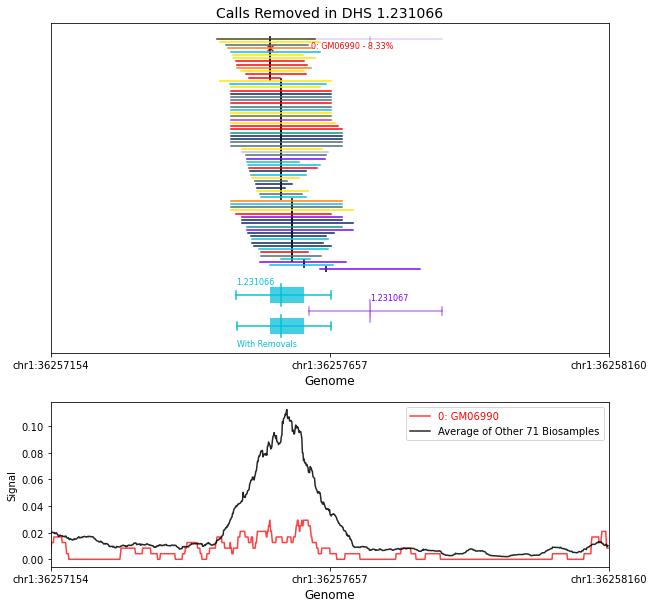

In [64]:
plotting_removed_calls(0, pre_removal_ave=False, norm=False, signal_type='bam', bam_norm=True)

Calls Removed in DHS 1.231066


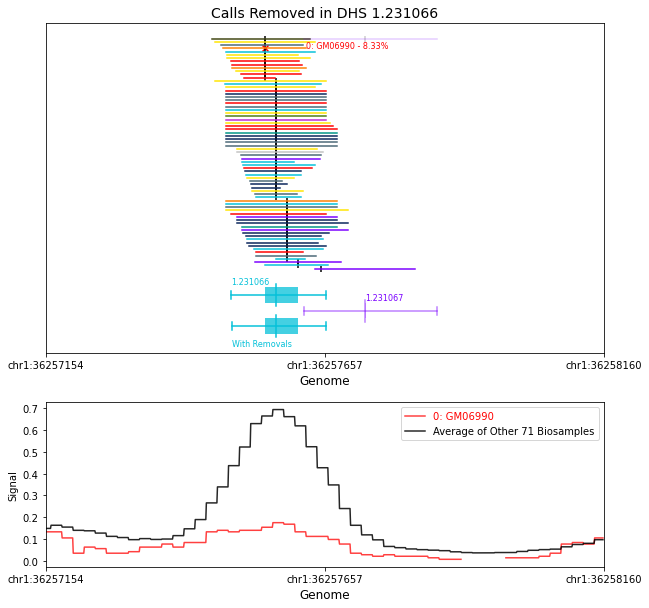

In [63]:
plotting_removed_calls(0, pre_removal_ave=False, norm=False, signal_type='bw')

In [178]:
#biosamples in "Calls removed in DHS 14.481879" plot (397 is removed)
biosample_df.loc[[397, 44, 418, 715, 671, 451]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
397,398,fTestes,NaN,ENCSR278FHC,ENCLB728VGZ,ENCBS796DWQ,AG8933,LN4413,DS18942,NaN,...,minElute,60.0,19.6,5760000.0,A+Sucrose,2011-05-04,27478973,0.4289,43570,43307
44,45,hESCT0,Primitive / embryonic,ENCSR000EMZ,ENCLB449ZZZ,ENCBS293AAA,AG4188,LN2365,DS11909,DS13133,...,minElute,80.0,14,NaN,NaN,2009-08-19,240791918,0.6453,315568,314868
418,419,Mesendoderm,Primitive / embryonic,ENCSR714DIF,ENCLB903DZR,ENCBS084NIJ,AG8911,LN4515,DS19310,DS18732,...,minElute,60.0,25.5,5970000.0,Buffer A,2011-06-07,270380677,0.5299,280673,279999
715,716,DE,Primitive / embryonic,ENCSR166KPV,ENCLB393NTX,ENCBS088TSK,AG6944,LN43606A,DS55923A,DS39603C,...,NaN,NaN,1.1,540000.0,NaN,2017-01-05,457497776,0.5445,312848,307202
671,672,H9_DN3_early,Primitive / embryonic,ENCSR754LIN,ENCLB139ECN,ENCBS140HIH,AG3993,LN30027A,DS34872A,NaN,...,NaN,NaN,NaN,530000.0,PBS+A,2015-02-04,251853460,0.3489,121699,121229
451,452,fTestes,NaN,ENCSR729DRB,ENCLB169OXT,ENCBS626EOQ,AG8879,LN4749,DS20170,NaN,...,minElute,60.0,8.9,3330000.0,A+Sucrose,2011-08-12,38702549,0.4293,65272,64967


In [244]:
#biosamples in "Calls removed in DHS 6.283067" plot (28 is removed)
biosample_df.loc[[616, 612, 613, 28]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
616,617,CD34_T6,Myeloid / erythroid,ENCSR564JUY,ENCLB947LFF,ENCBS986SUJ,AG3833,LN26288A,DS25730A,DS25729A,...,NaN,120.0,50,7500000.0,PBS+A,2014-01-15,407694757,0.5602,204374,203758
612,613,CD34_T4,Myeloid / erythroid,ENCSR148VUP,ENCLB809AHE,ENCBS721DUI,AG3831,LN26240A,DS25687A,DS24074A,...,NaN,80.0,50,7700000.0,PBS+A,2014-02-13,361402768,0.6173,245256,244793
613,614,CD34_T8,Myeloid / erythroid,ENCSR845CFB,ENCLB658VAX,ENCBS418LVC,AG3835,LN26258A,DS25769A,"DS25762A,DS24094A",...,NaN,80.0,30,7400000.0,PBS+A,2014-01-17,282261693,0.5385,167123,166835
28,29,hTH17,NaN,ENCSR000EQF,ENCLB597ZZZ,ENCBS364AAA,AG4198,LN2044,DS11039,NaN,...,microcon,80.0,8.5,NaN,NaN,2009-04-14,208484267,0.3505,73941,73856


In [103]:
np.argsort(max_removed_distance_all)

array([ 9729, 11328,  2280, ..., 14214,  4701,  8085])

In [245]:
np.where(np.sort(max_removed_distance_all)>500)

(array([20470, 20471, 20472, 20473]),)

Calls Removed in DHS 7.224439
Normalized Signal


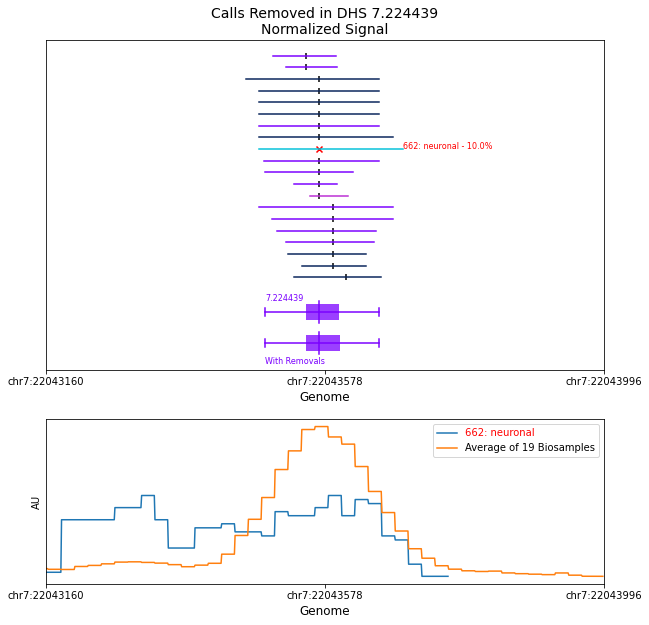

Calls Removed in DHS 14.481879
Normalized Signal


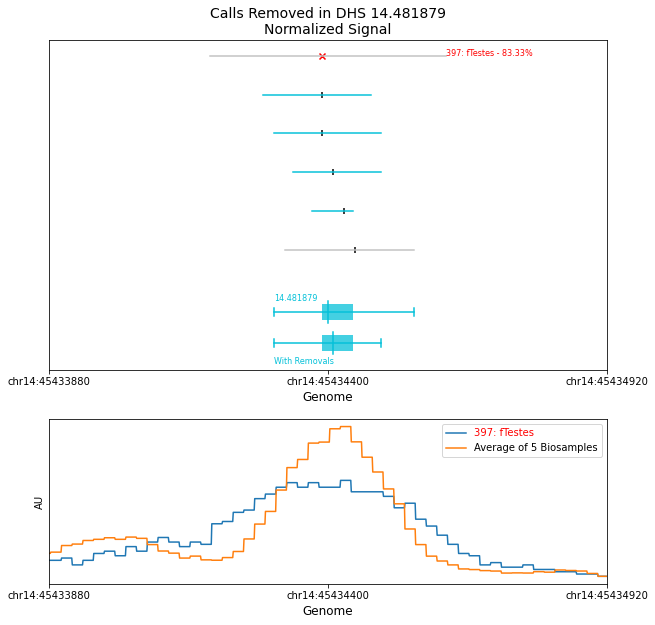

Calls Removed in DHS 10.1758623
Normalized Signal


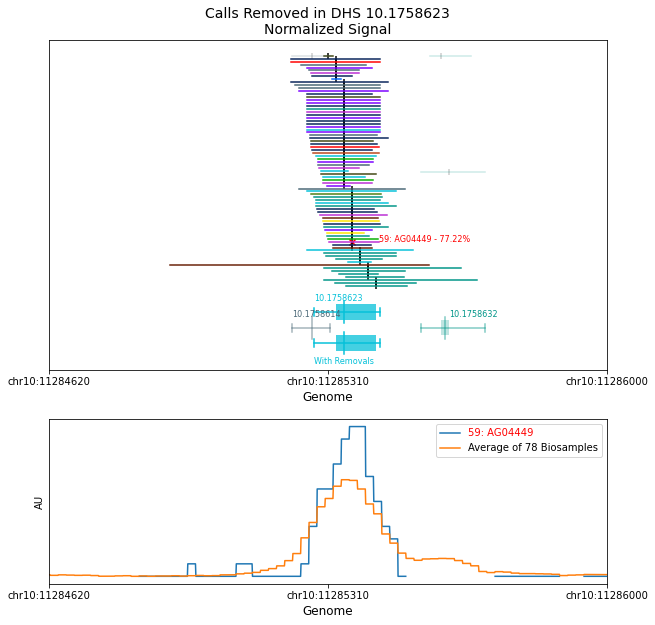

Calls Removed in DHS 6.283067
Normalized Signal


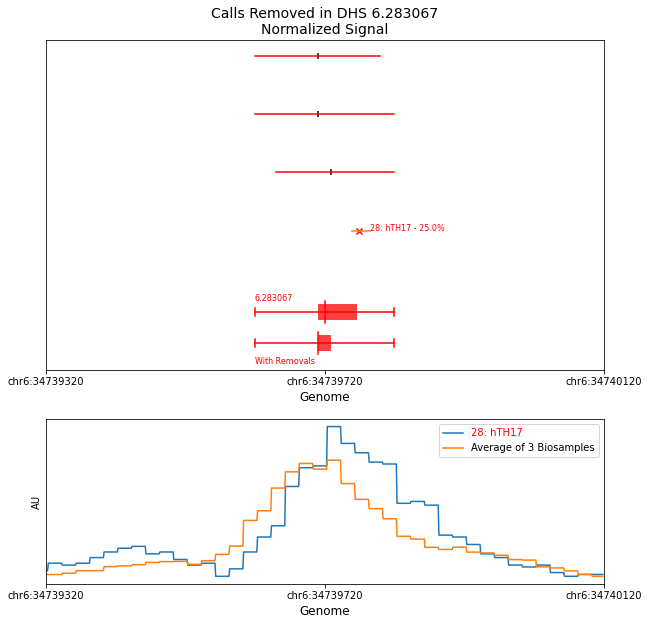

Calls Removed in DHS 9.107865
Normalized Signal


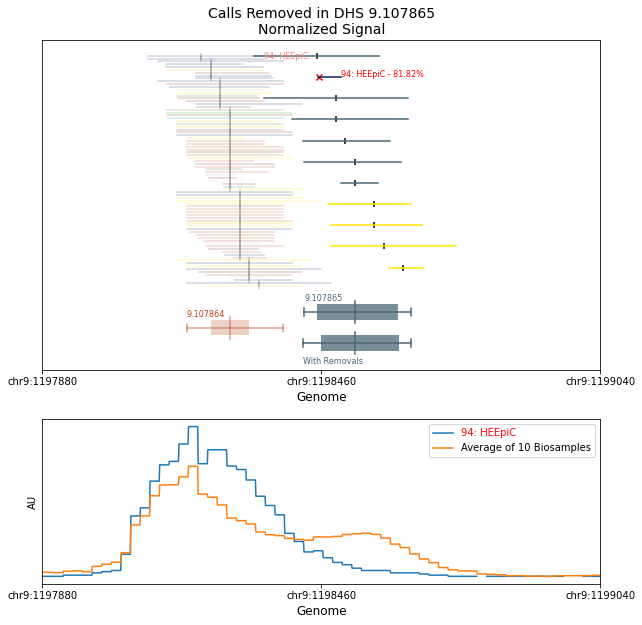

Calls Removed in DHS 16.892876
Normalized Signal


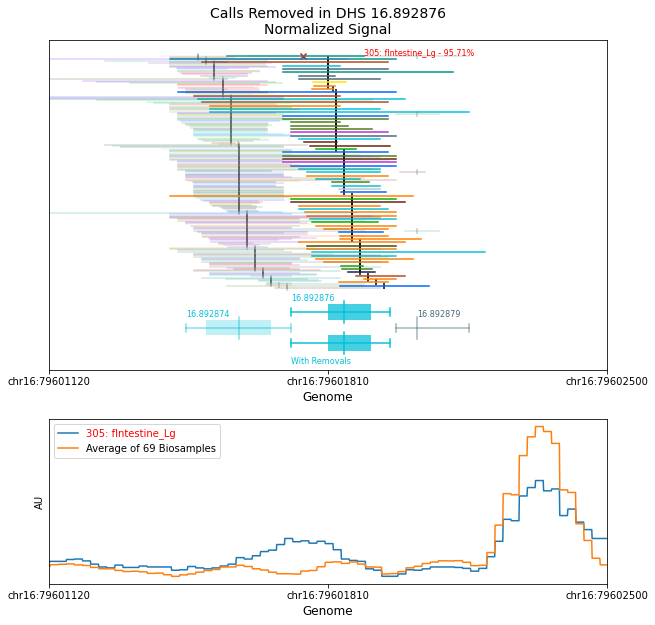

Calls Removed in DHS 2.1059722
Normalized Signal


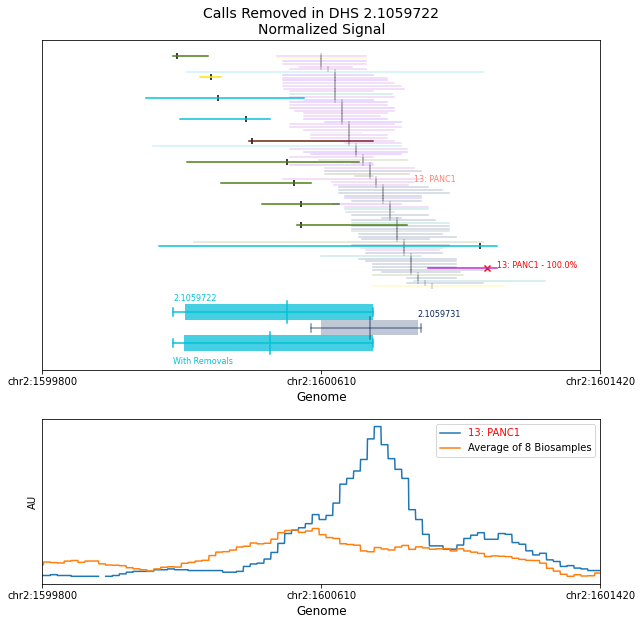

Calls Removed in DHS 6.9631691
Normalized Signal


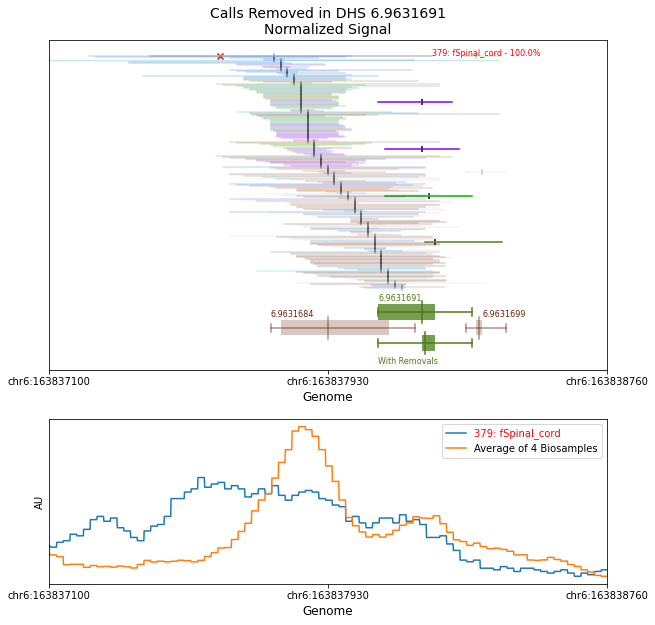

Calls Removed in DHS 12.4918726
Normalized Signal


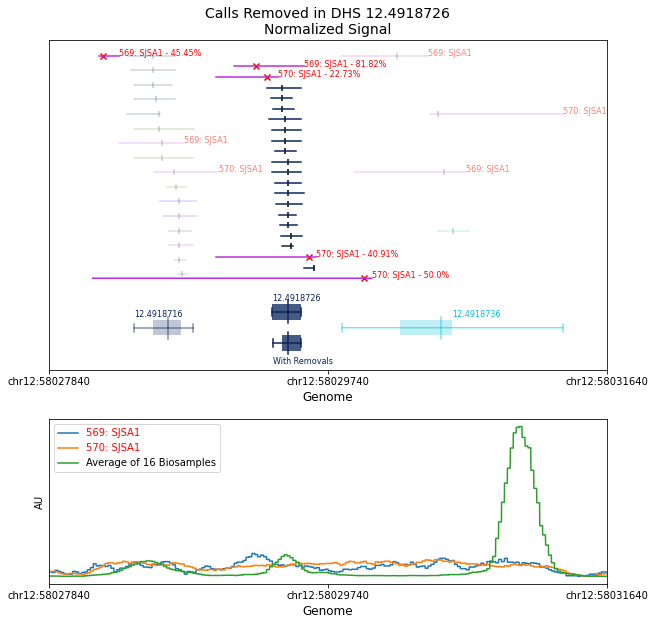

In [62]:
#Normalized
for i in np.argsort(max_removed_distance_all)[[0, 3500, 4044, 12747, 15849, 17860, 20471, 20472, 20473]]:
    plotting_removed_calls(i, norm=True)

Calls Removed in DHS 7.224439


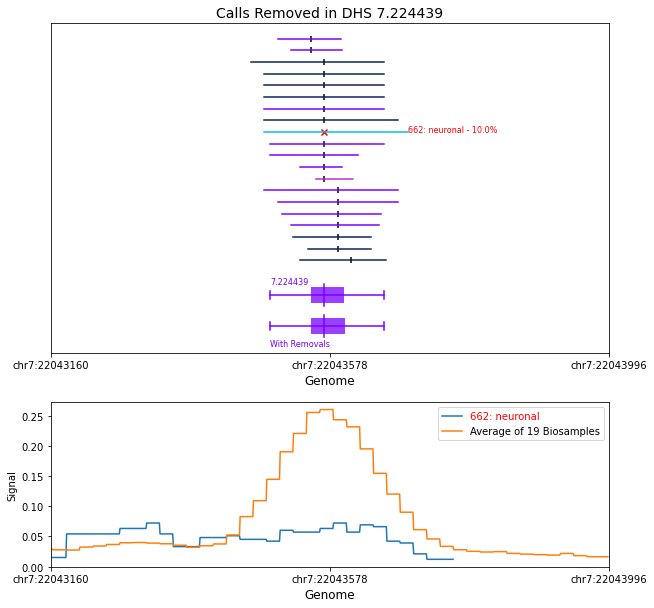

Calls Removed in DHS 14.481879


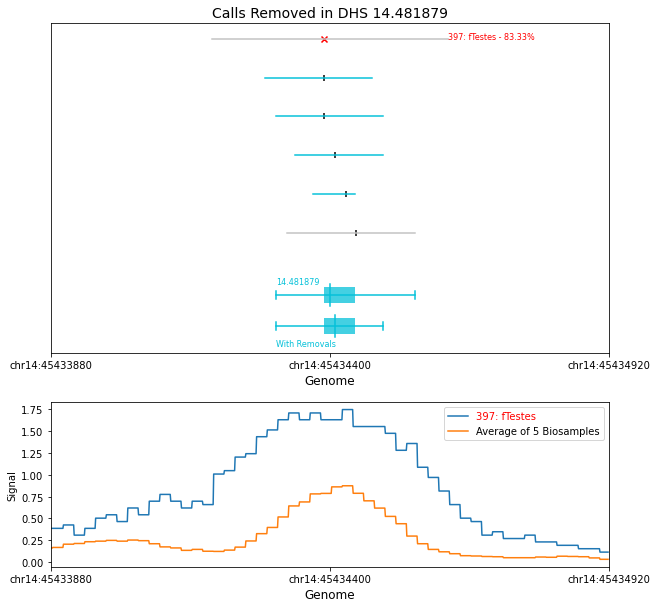

Calls Removed in DHS 10.1758623


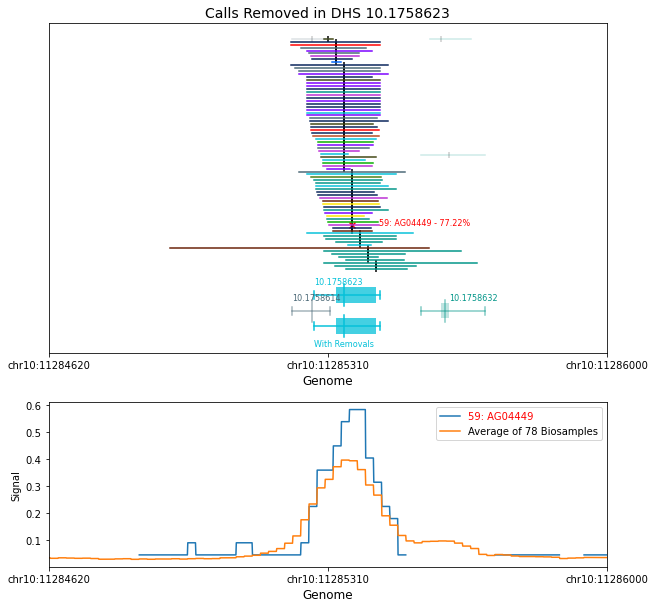

Calls Removed in DHS 6.283067


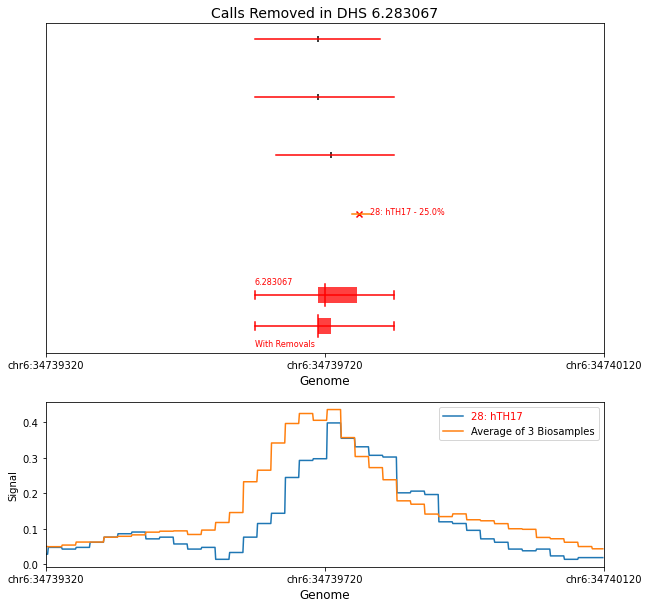

Calls Removed in DHS 9.107865


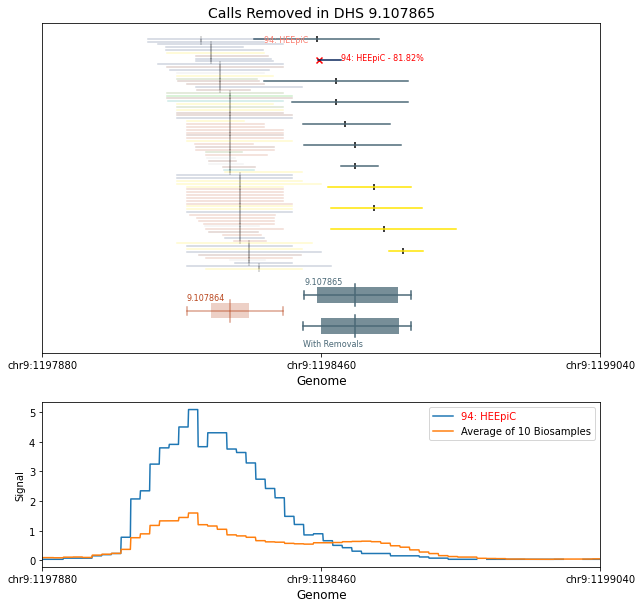

Calls Removed in DHS 16.892876


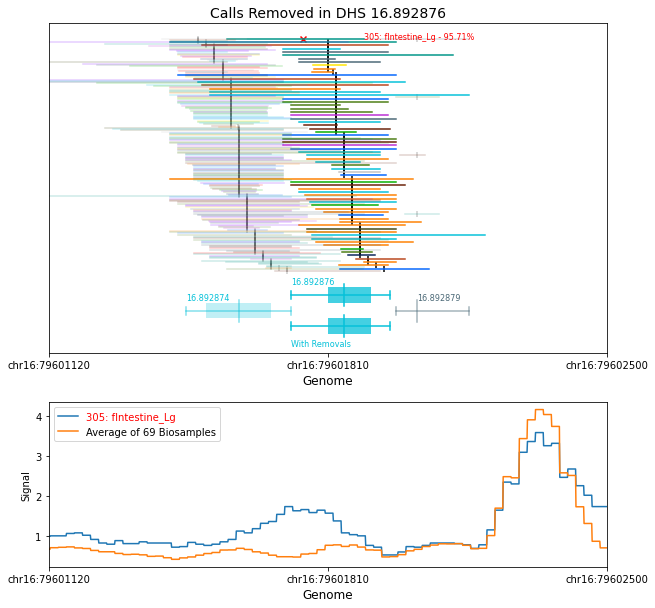

Calls Removed in DHS 2.1059722


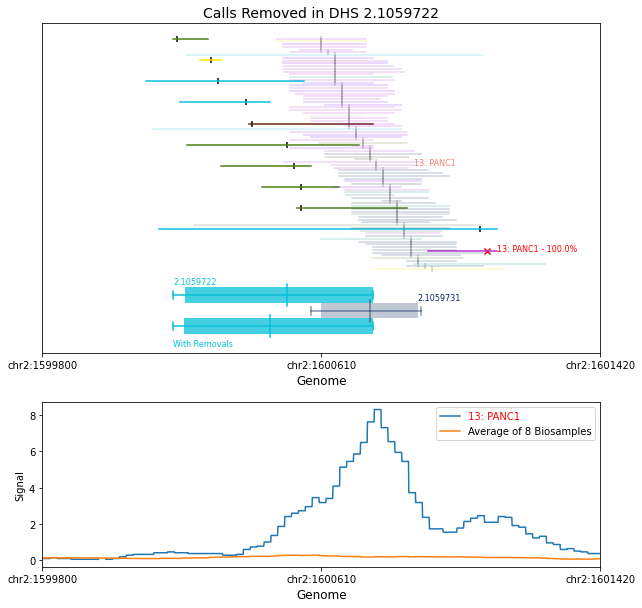

Calls Removed in DHS 6.9631691


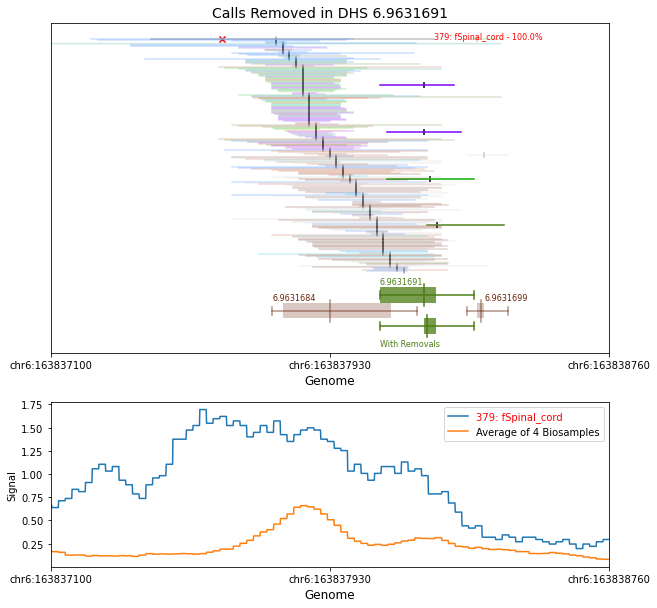

Calls Removed in DHS 12.4918726


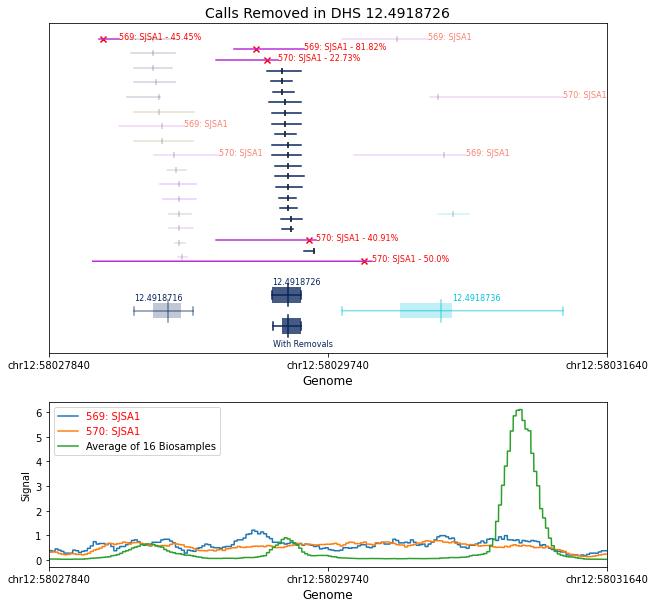

In [63]:
for i in np.argsort(max_removed_distance_all)[[0, 3500, 4044, 12747, 15849, 17860, 20471, 20472, 20473]]:
    plotting_removed_calls(i)

In [65]:
#finding most isolated DHSs
ordered_removed_call_DHS_mindistances = []
for DHS in ordered_inds_removed_call_DHSs:
    dhs_df = DHS_metadata.loc[DHS-1:DHS+1]
    min_distance = np.min([(int(dhs_df.iloc[1]['start']) - int(dhs_df.iloc[0]['end'])), 
                           (int(dhs_df.iloc[2]['start']) - int(dhs_df.iloc[1]['end']))])
    ordered_removed_call_DHS_mindistances.append(min_distance)
ordered_removed_call_DHS_mindistances = np.array(ordered_removed_call_DHS_mindistances)

DHS 4.304978


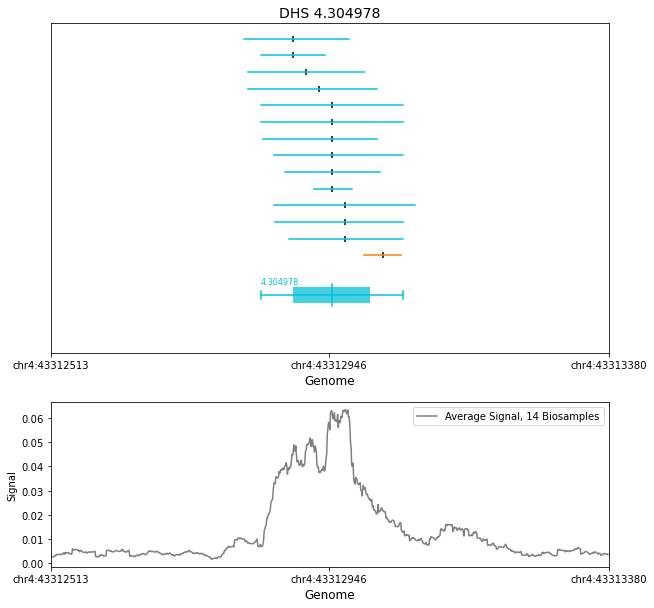

DHS 20.64143


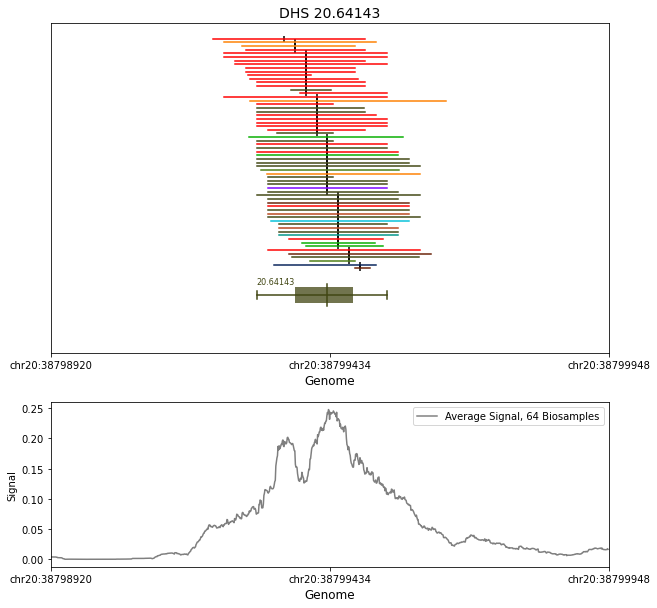

DHS 1.671844


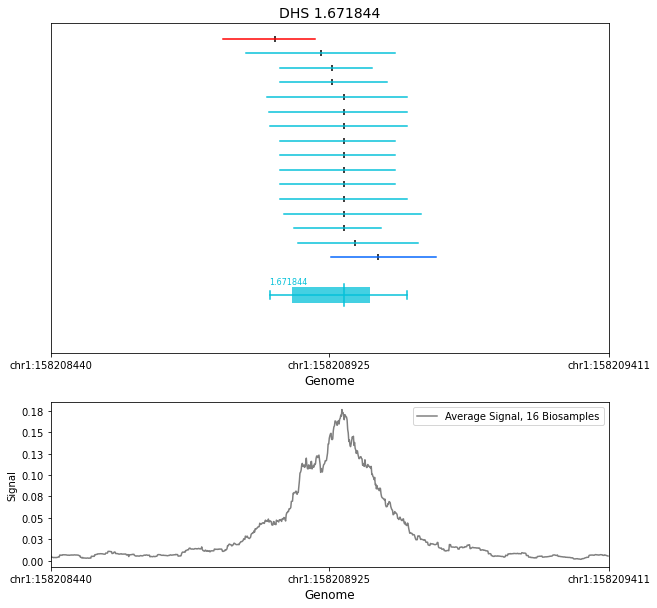

In [106]:
#most isolated DHSs with removed call - before removal
for i in np.argsort(-ordered_removed_call_DHS_mindistances)[[20, 24, 26]]:
    plotting_removed_calls(i, signal_type='bam', bam_norm=True, pre_removal_view=True, pre_removal_ave=True)

Calls Removed in DHS 5.45032


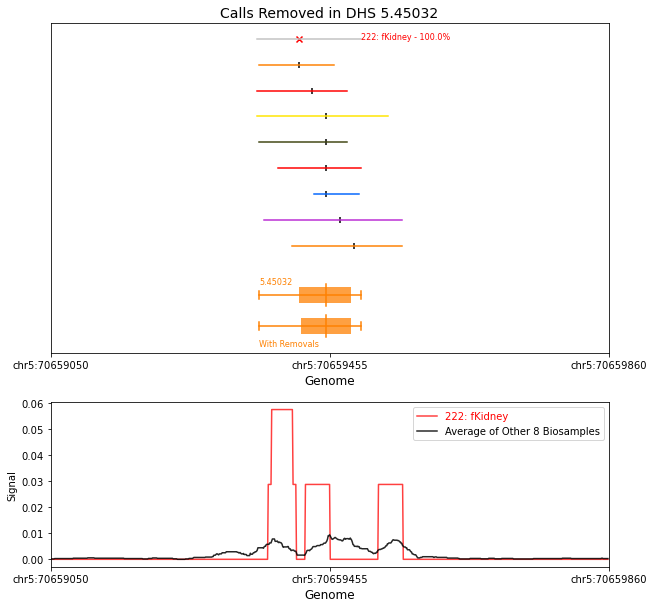

Calls Removed in DHS 9.39489


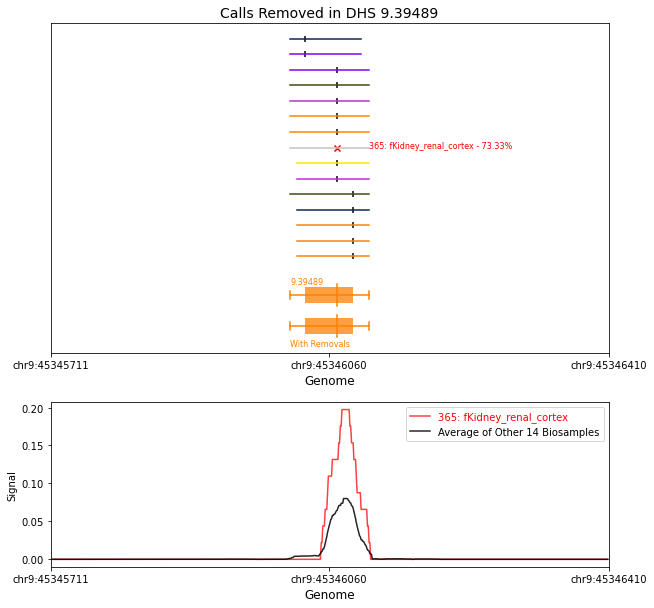

Calls Removed in DHS 6.94627


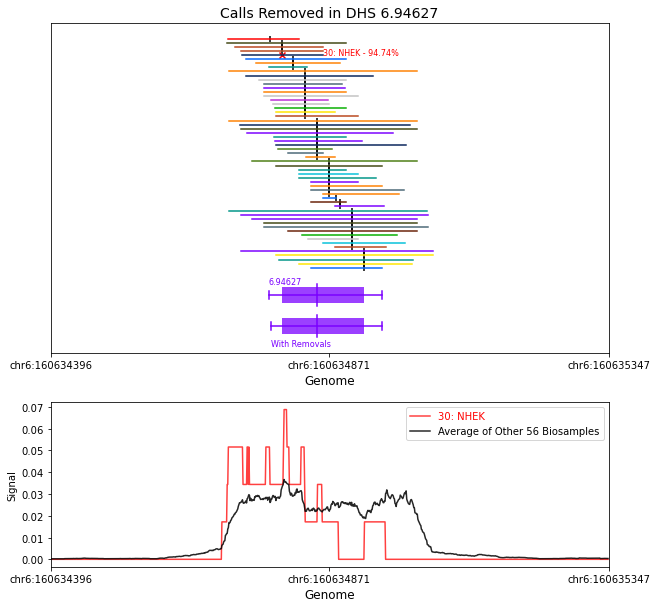

Calls Removed in DHS 7.45237


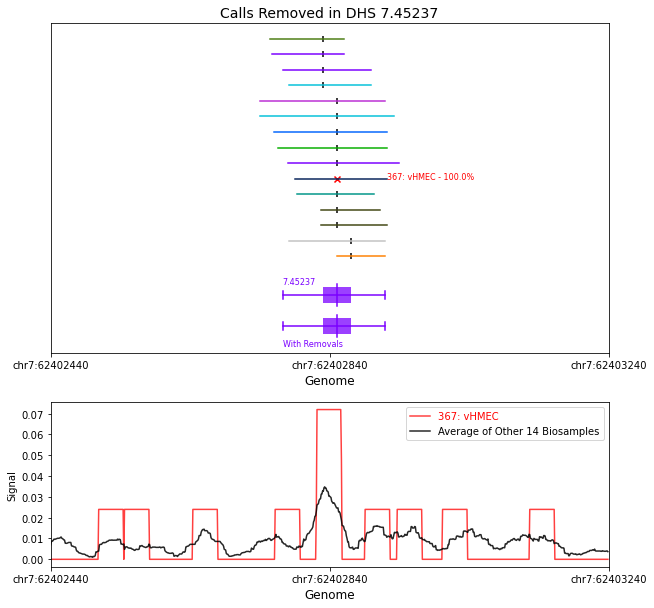

Calls Removed in DHS 1.62057


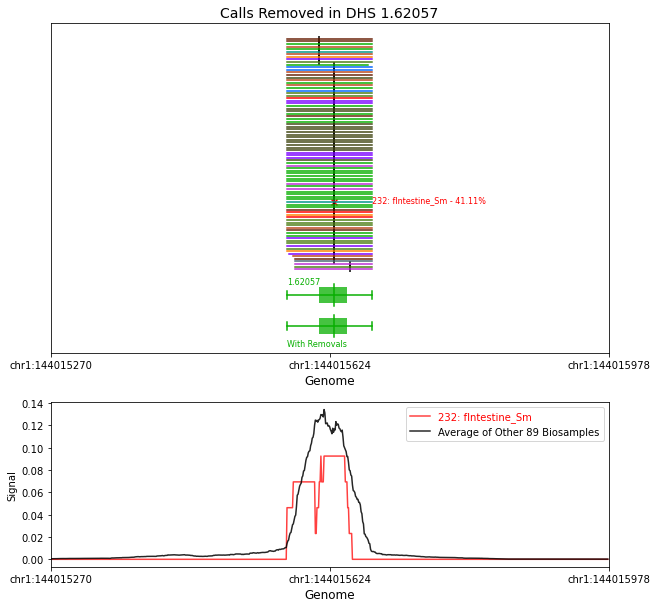

Calls Removed in DHS X.52158


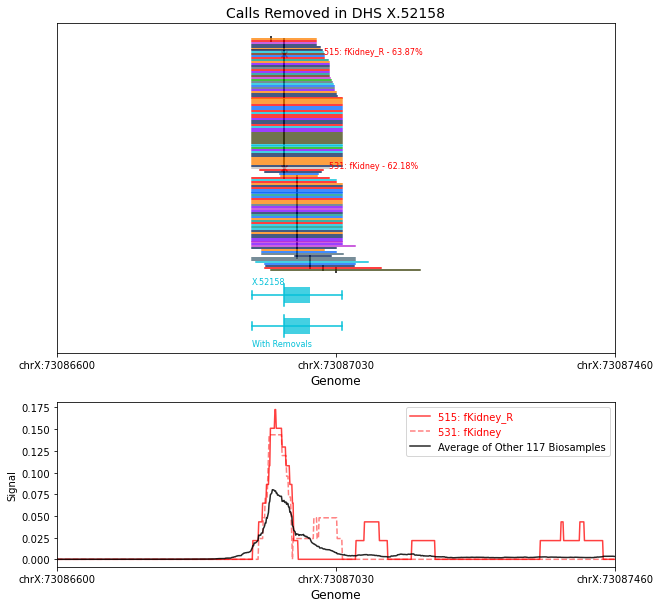

Calls Removed in DHS 9.363486


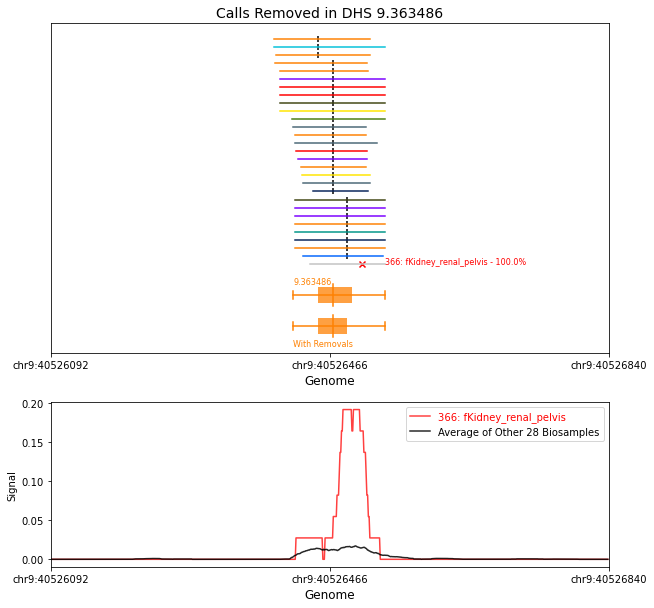

Calls Removed in DHS 13.23482


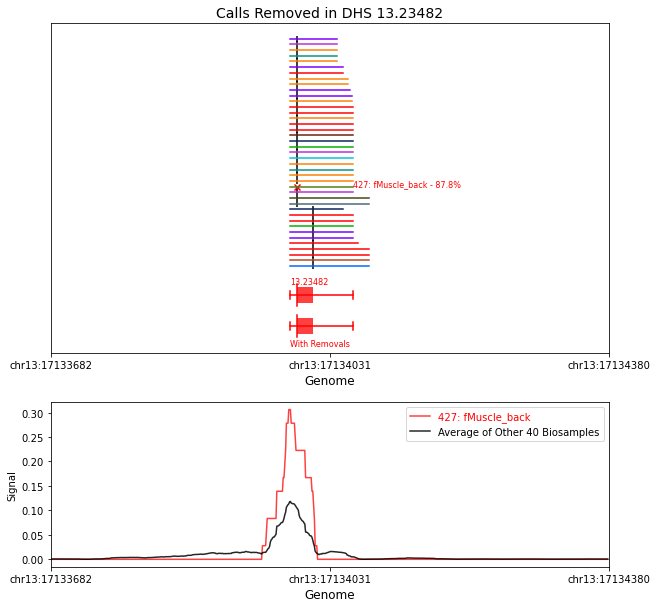

Calls Removed in DHS 12.68287


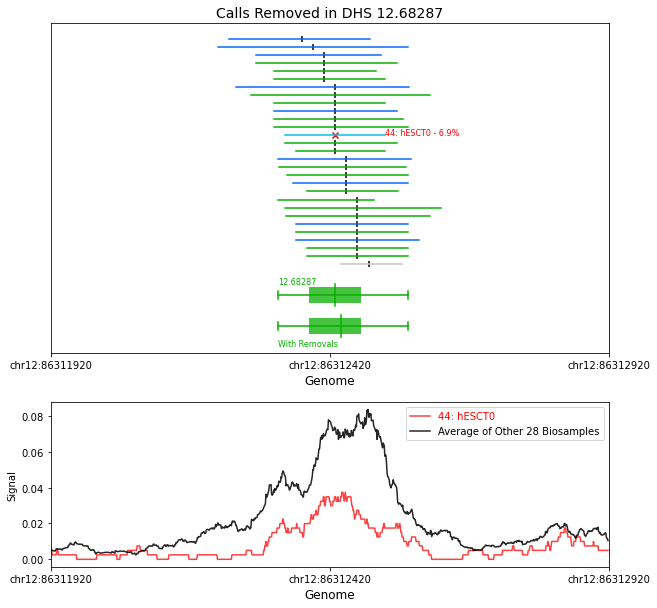

Calls Removed in DHS 9.25552


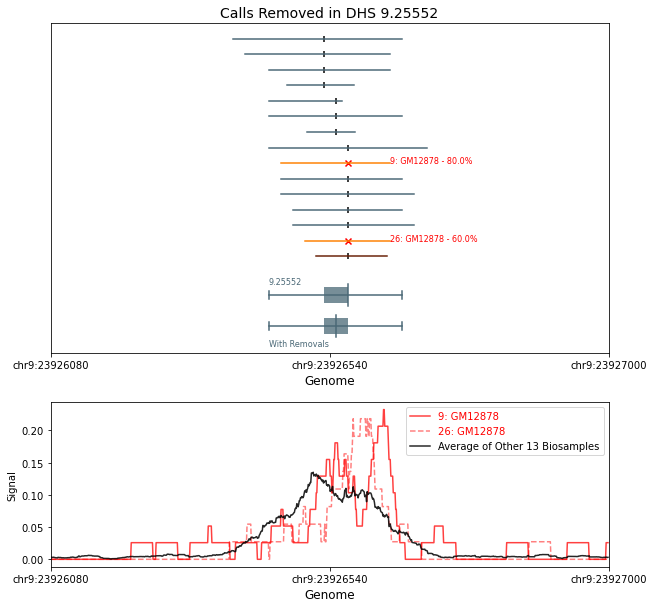

Calls Removed in DHS 20.1019


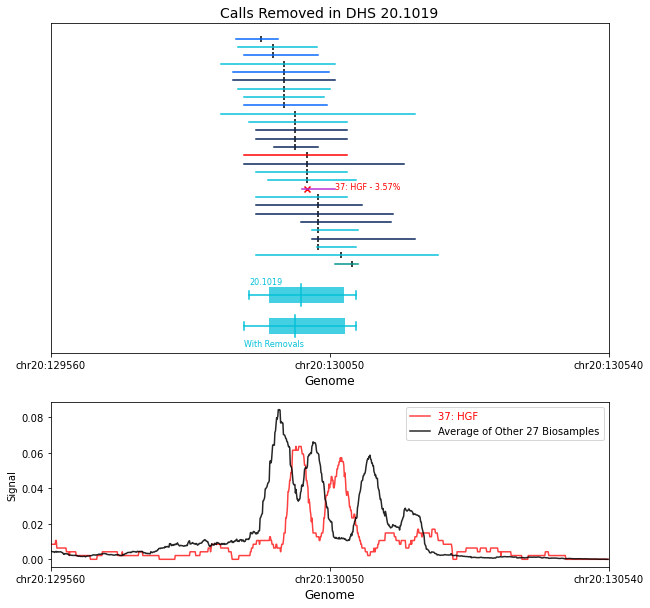

Calls Removed in DHS X.23807


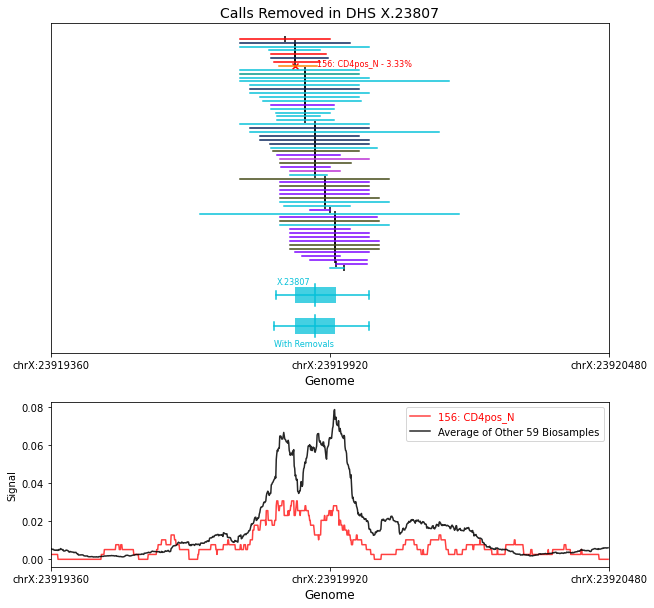

Calls Removed in DHS 4.94837


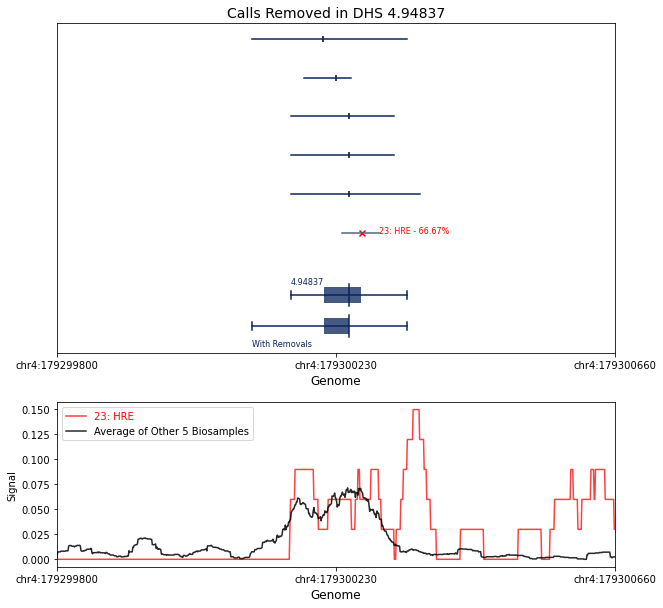

Calls Removed in DHS 7.68893


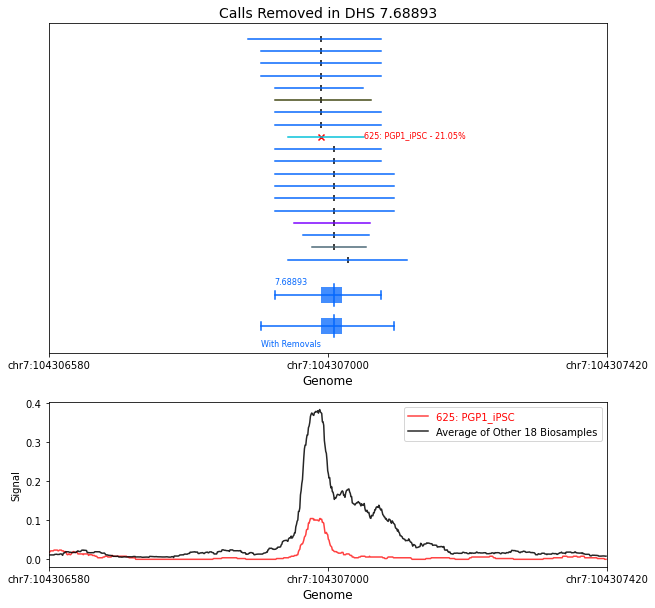

Calls Removed in DHS 4.456762


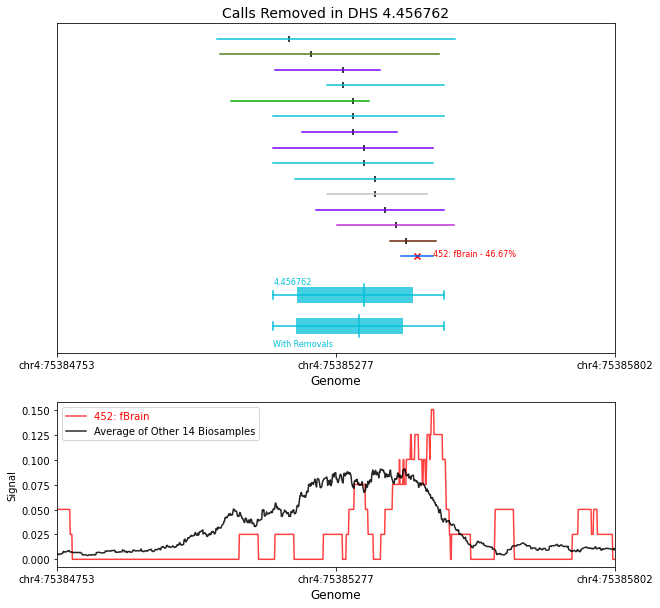

Calls Removed in DHS 1.62507


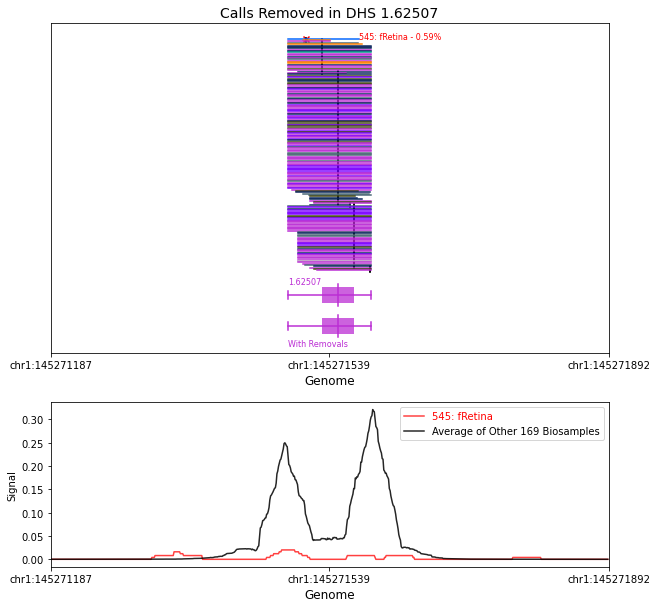

Calls Removed in DHS 7.91227


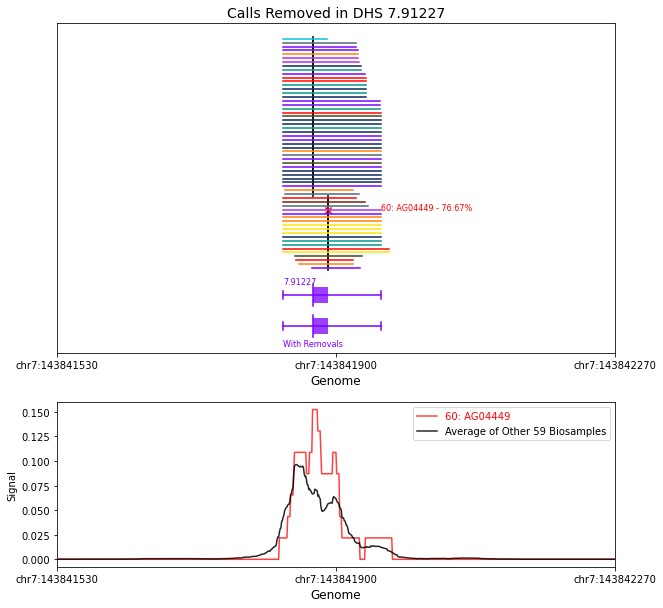

Calls Removed in DHS 21.69235


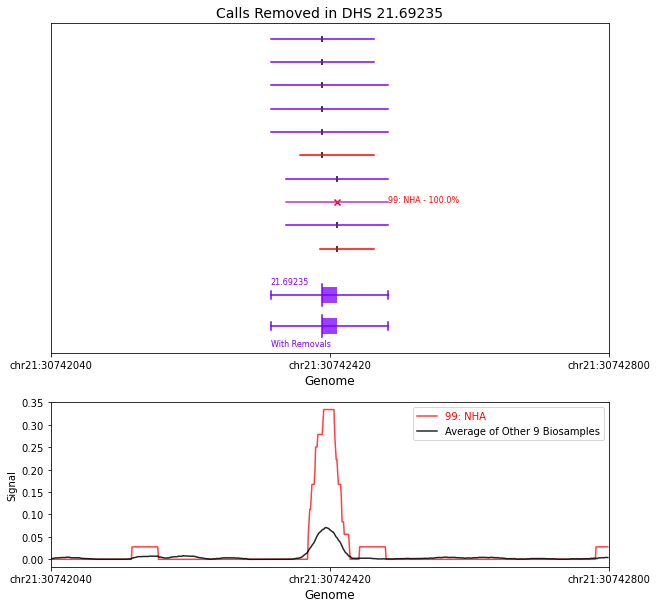

Calls Removed in DHS 9.379263


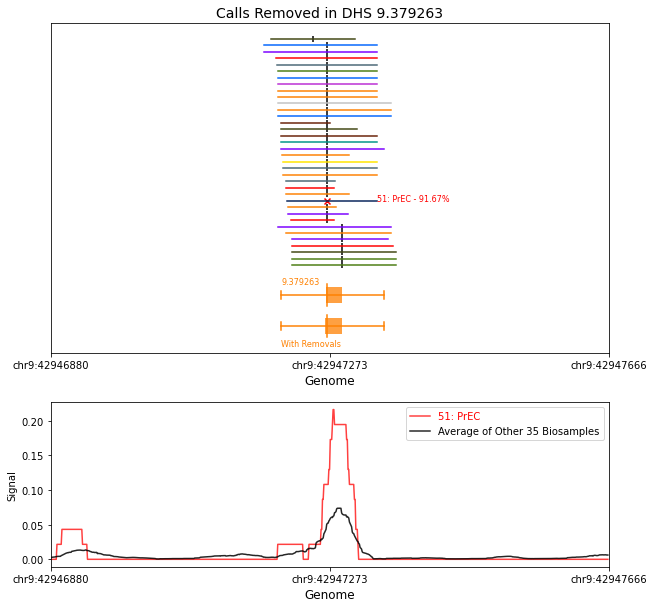

Calls Removed in DHS 12.675498


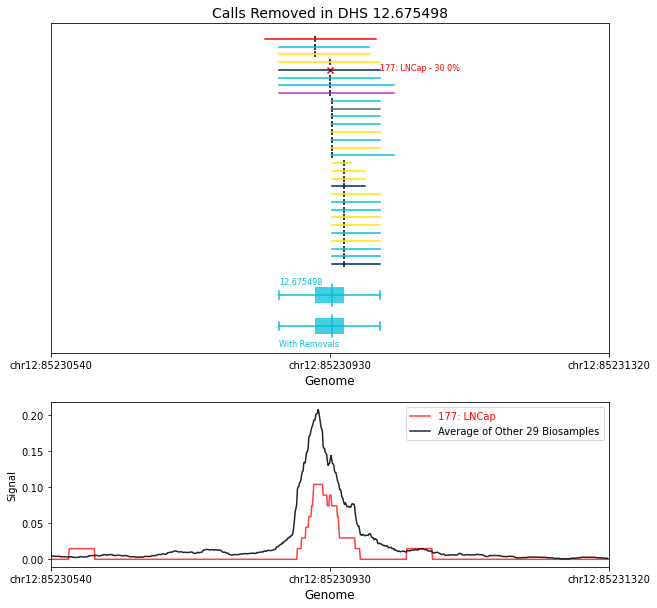

Calls Removed in DHS 4.304978


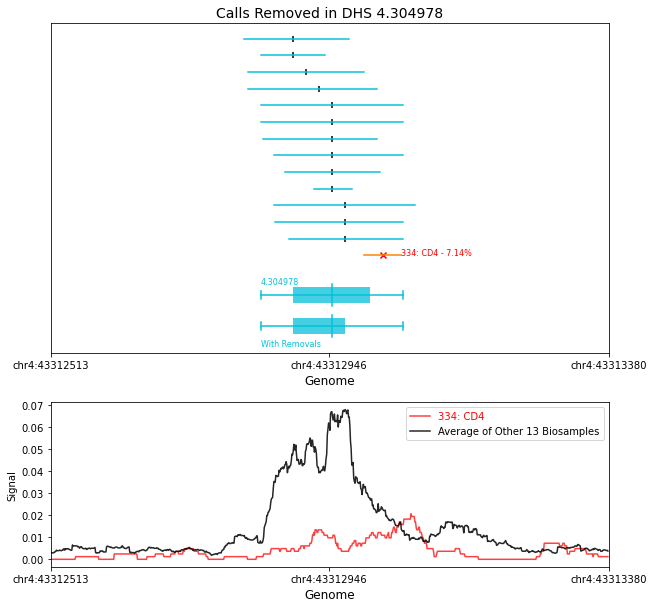

Calls Removed in DHS 9.581266


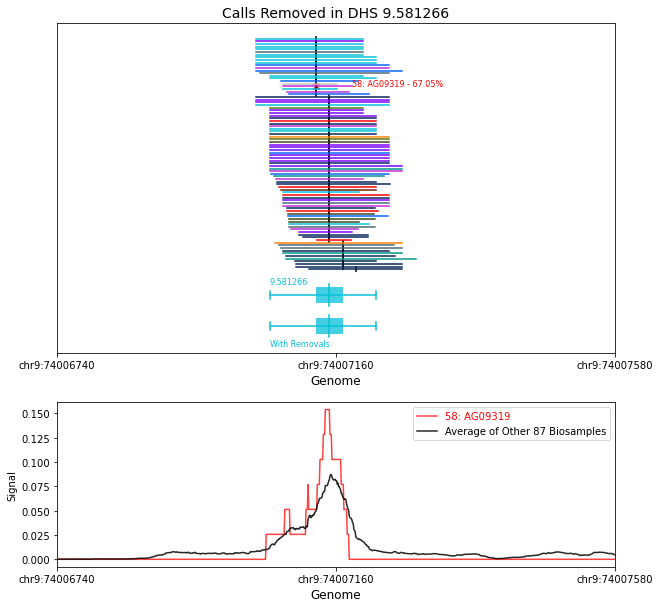

Calls Removed in DHS 4.159826


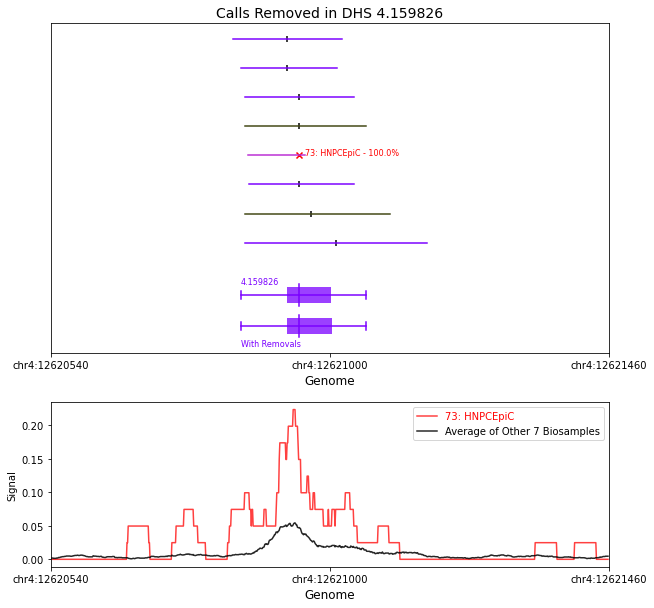

Calls Removed in DHS 2.807071


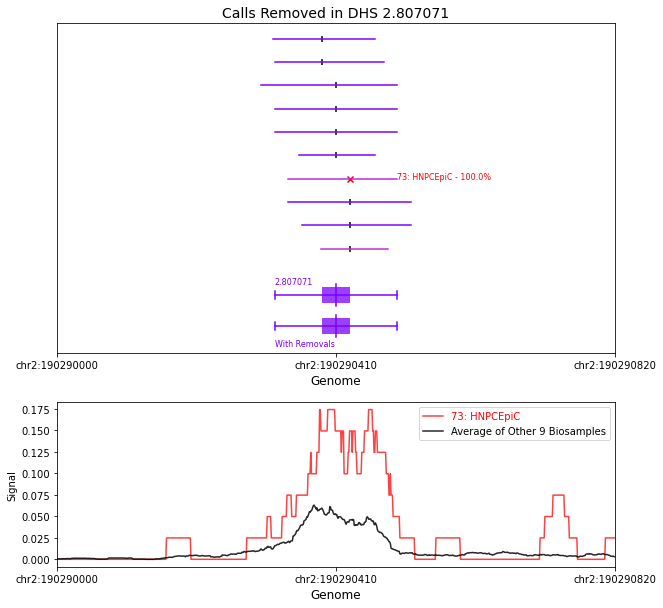

Calls Removed in DHS 20.64143


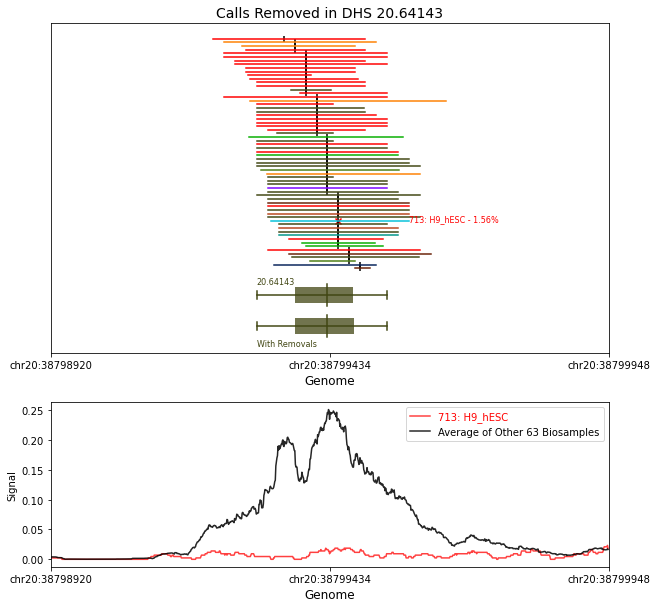

Calls Removed in DHS 2.5053


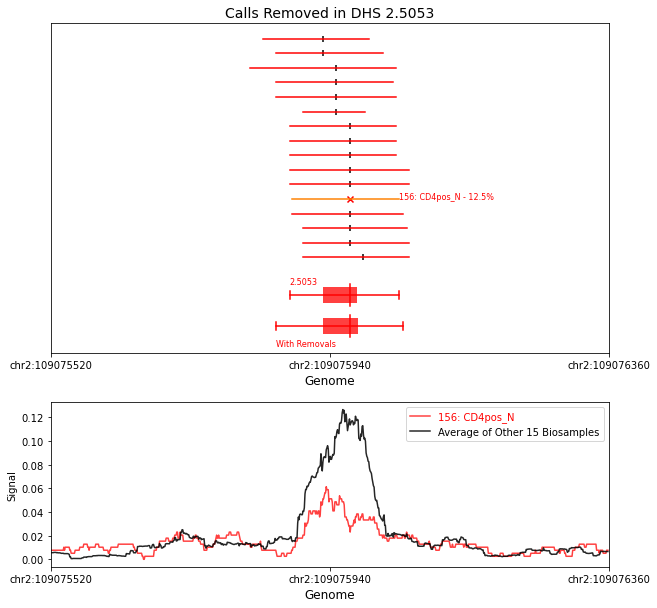

Calls Removed in DHS 1.671844


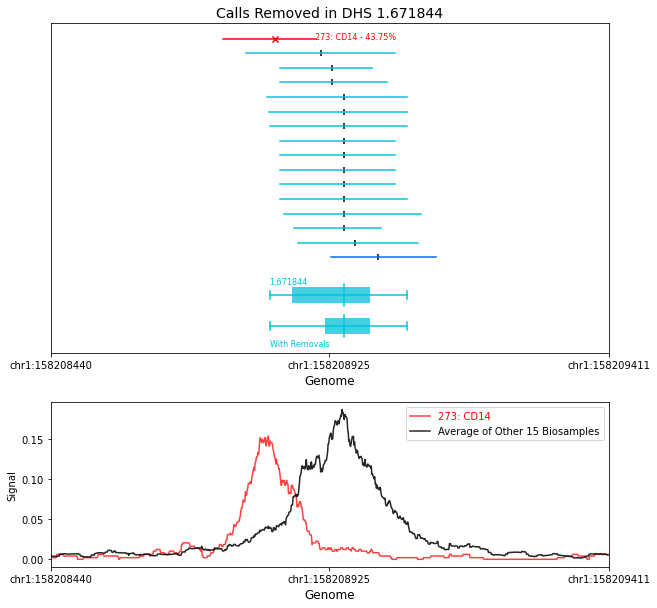

Calls Removed in DHS 3.11505


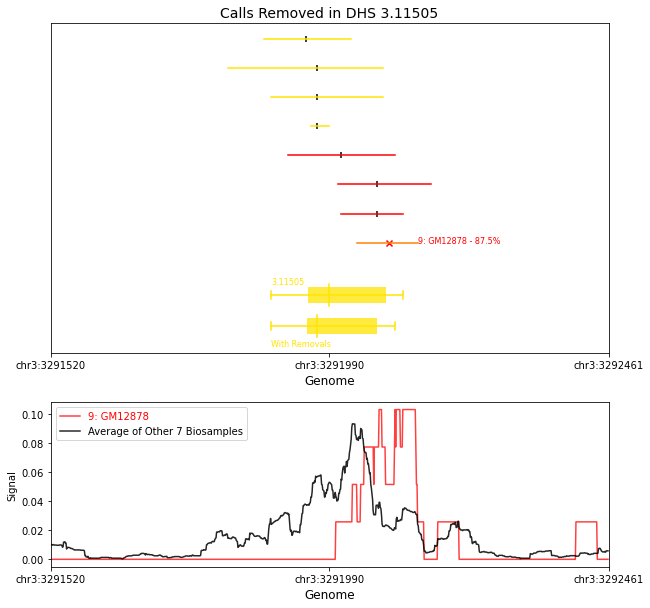

Calls Removed in DHS 8.758671


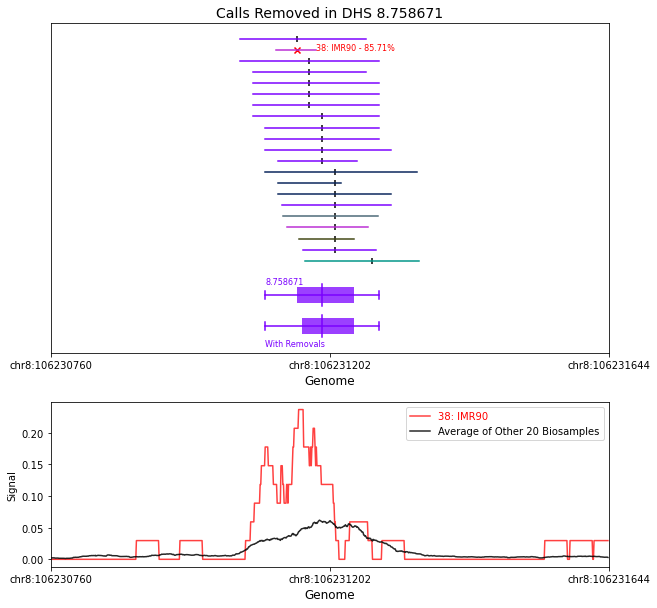

Calls Removed in DHS 4.16449


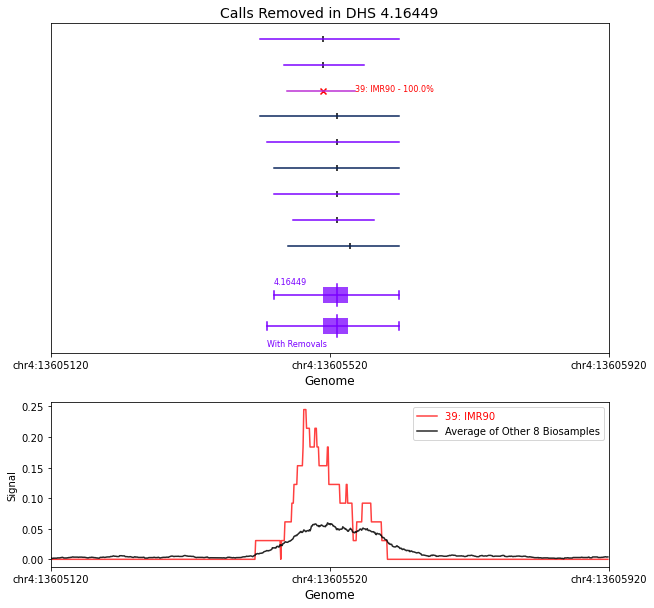

In [67]:
#most isolated DHSs with removed call (bam)
for i in np.argsort(-ordered_removed_call_DHS_mindistances)[:30]:
    plotting_removed_calls(i, signal_type='bam', bam_norm=True)

Calls Removed in DHS 5.45032


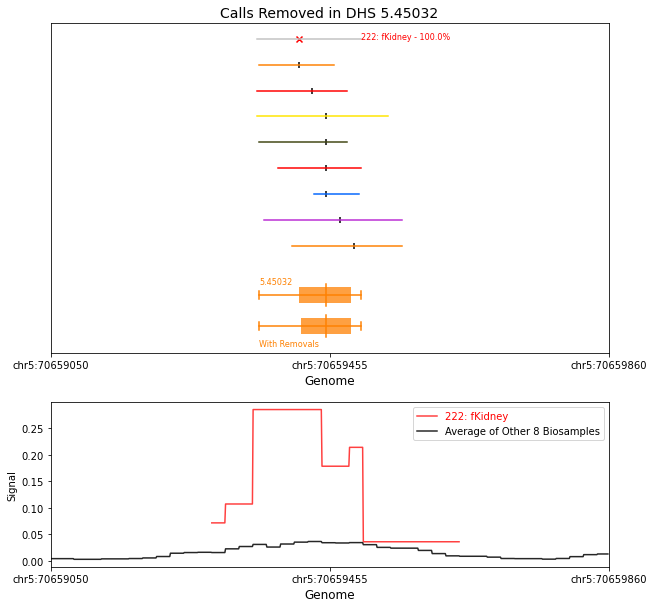

/tmp/ipykernel_99902/1183633504.py:399: RuntimeWarning: Mean of empty slice
  average_signal_to_plot = np.nanmean(average_signal_other_calls, axis=0)


Calls Removed in DHS 9.39489


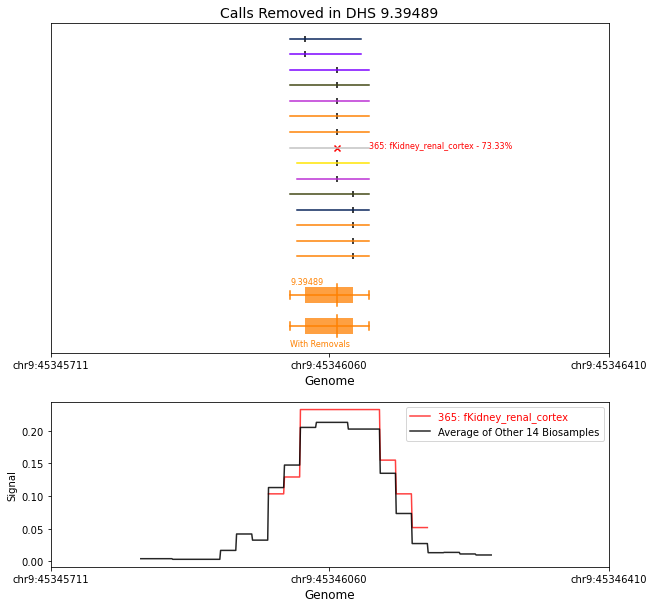

Calls Removed in DHS 6.94627


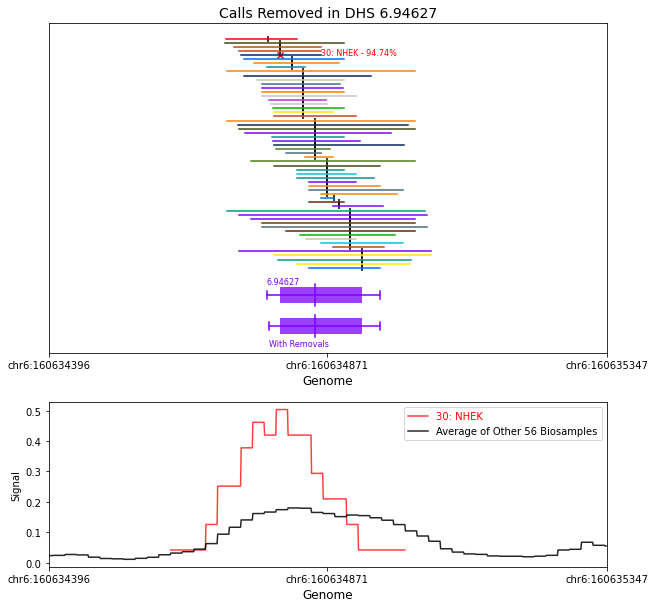

Calls Removed in DHS 7.45237


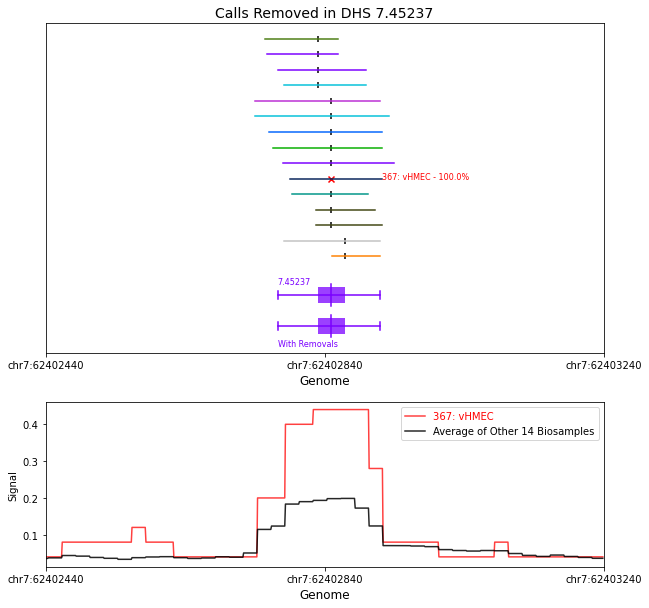

Calls Removed in DHS 1.62057


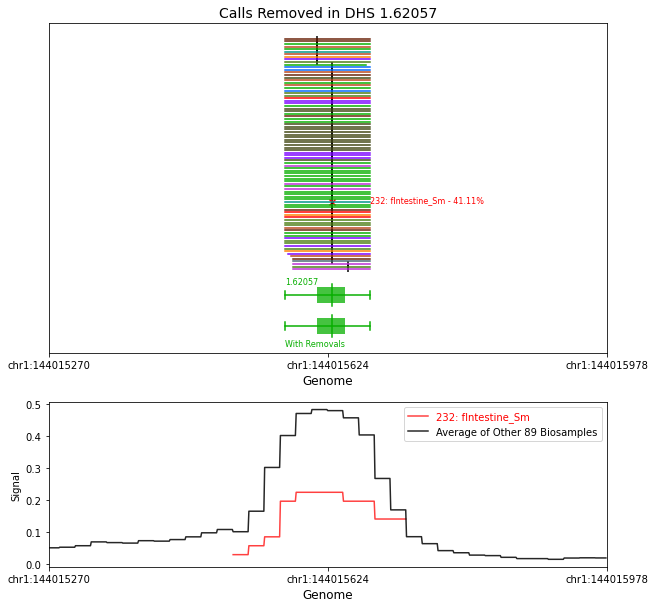

Calls Removed in DHS X.52158


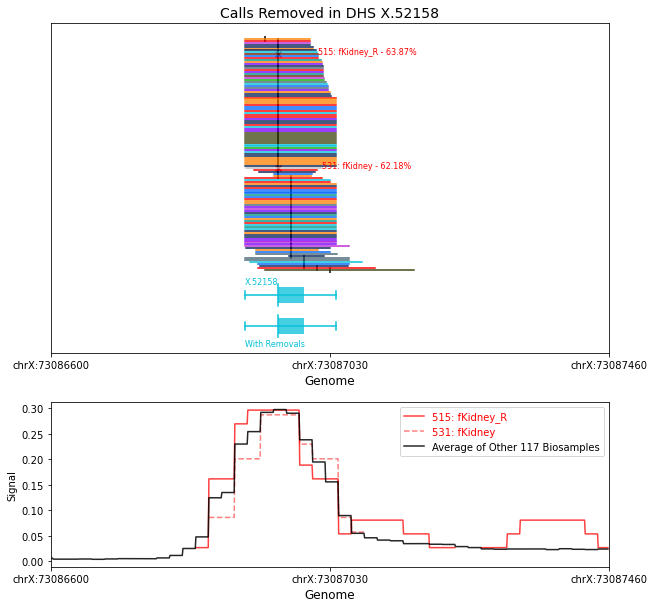

Calls Removed in DHS 9.363486


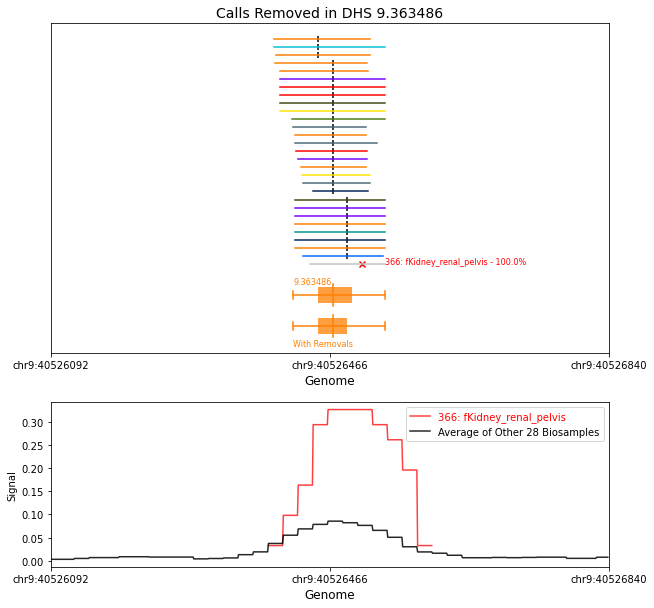

Calls Removed in DHS 13.23482


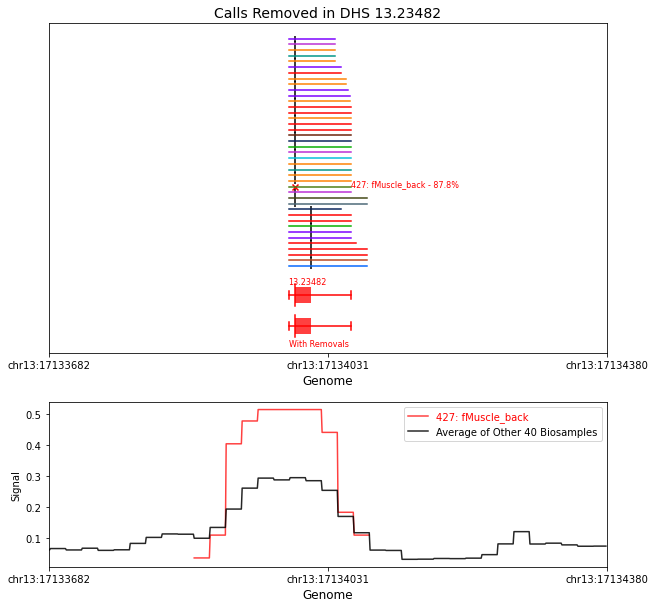

Calls Removed in DHS 12.68287


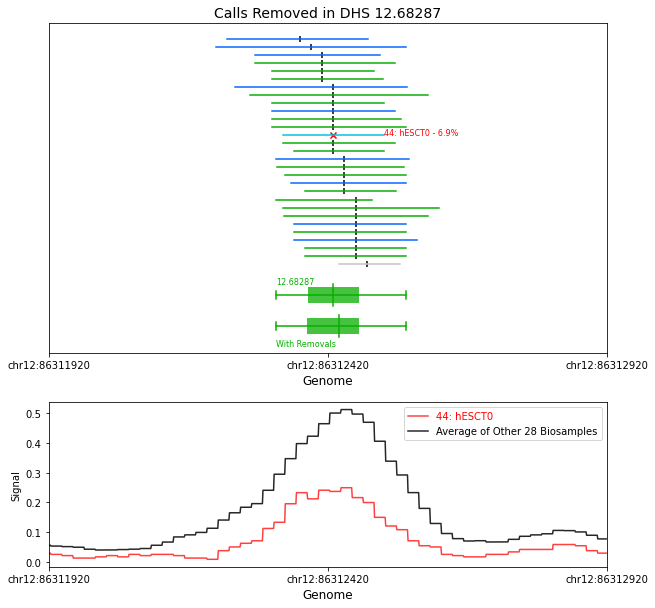

Calls Removed in DHS 9.25552


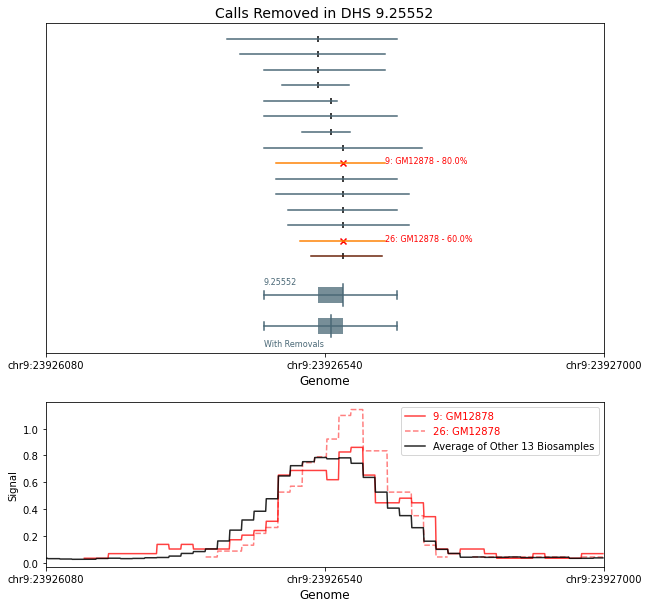

Calls Removed in DHS 20.1019


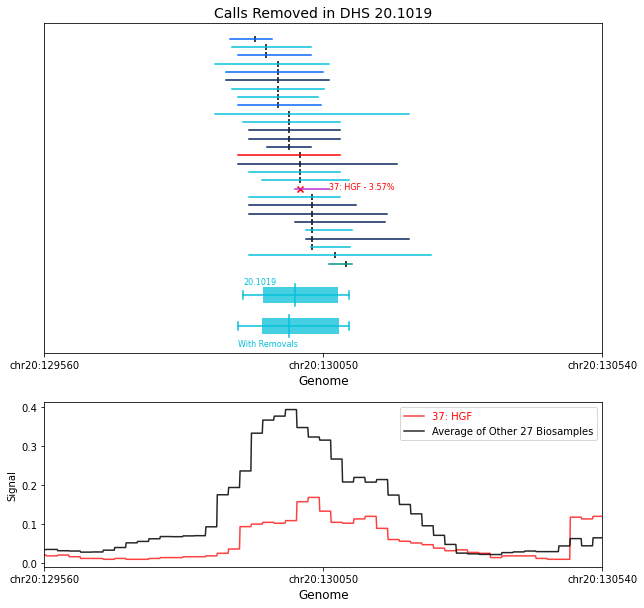

Calls Removed in DHS X.23807


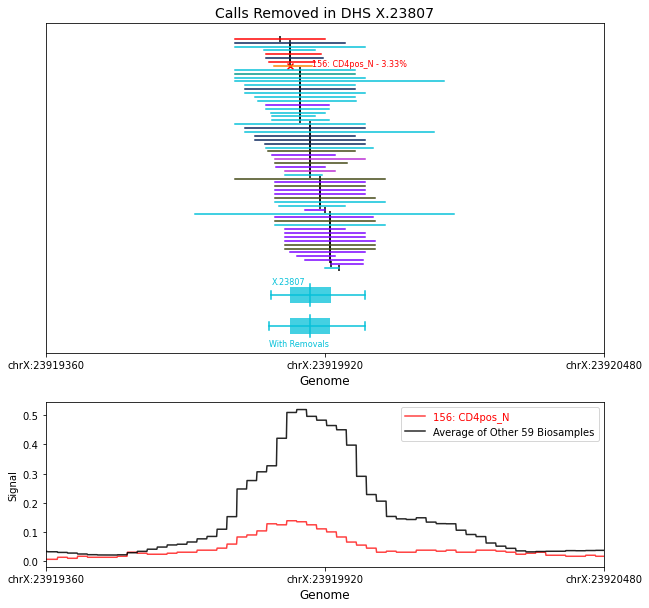

Calls Removed in DHS 4.94837


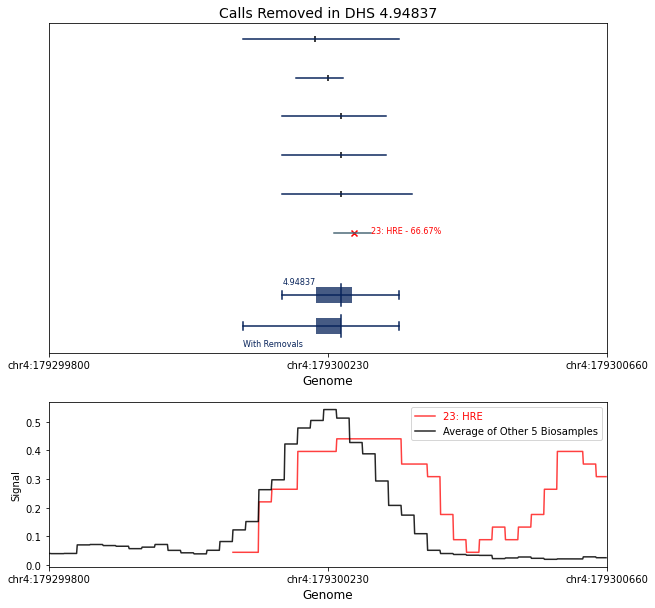

Calls Removed in DHS 7.68893


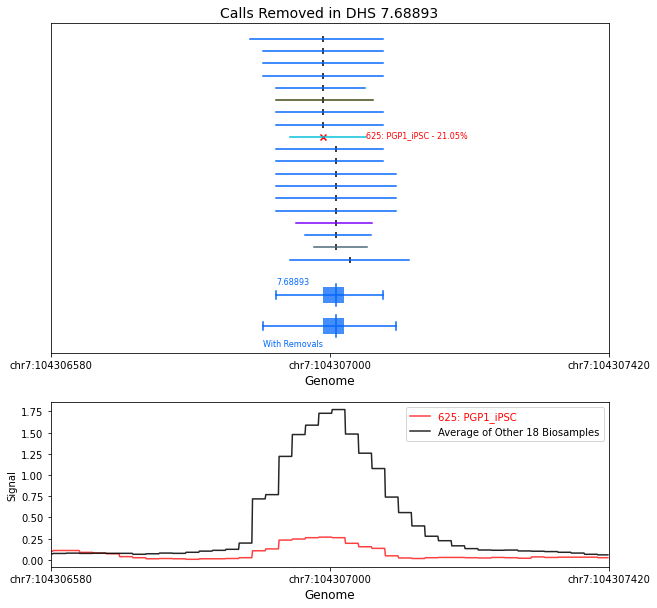

Calls Removed in DHS 4.456762


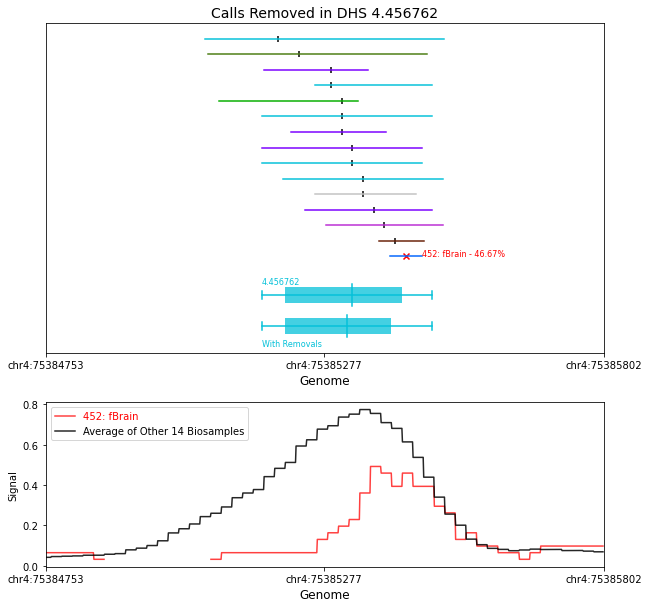

Calls Removed in DHS 1.62507


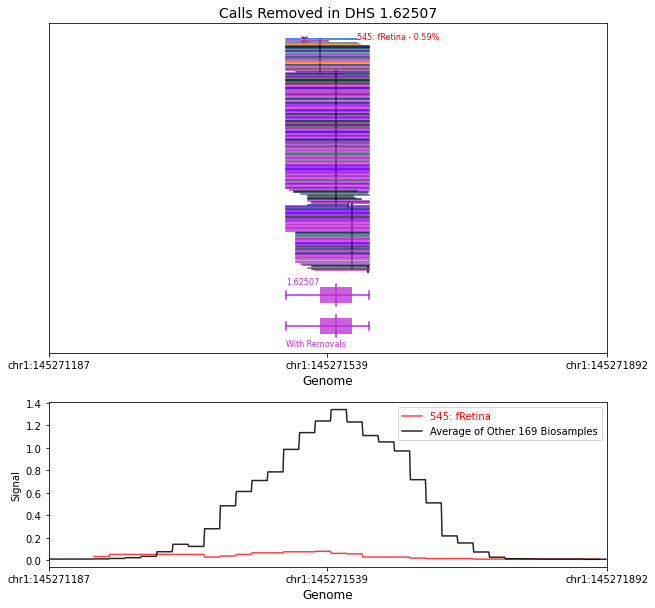

Calls Removed in DHS 7.91227


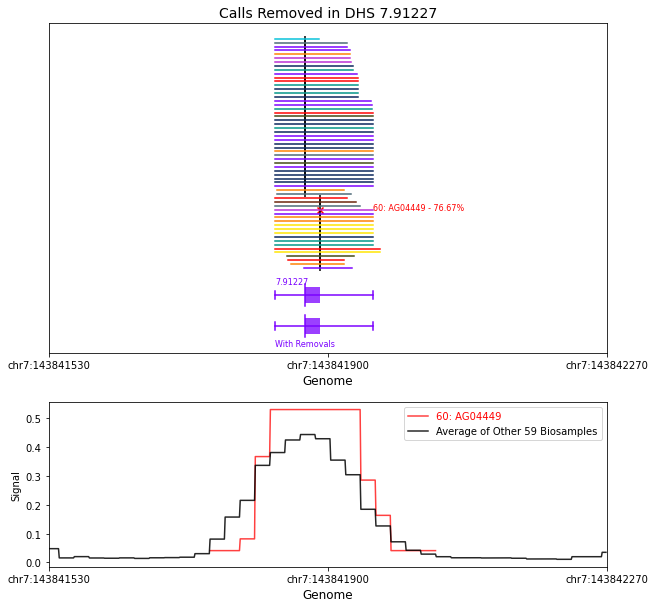

Calls Removed in DHS 21.69235


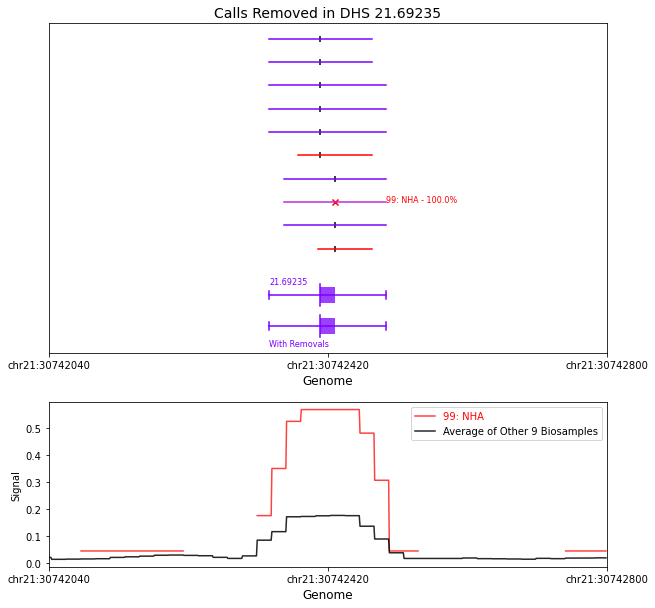

Calls Removed in DHS 9.379263


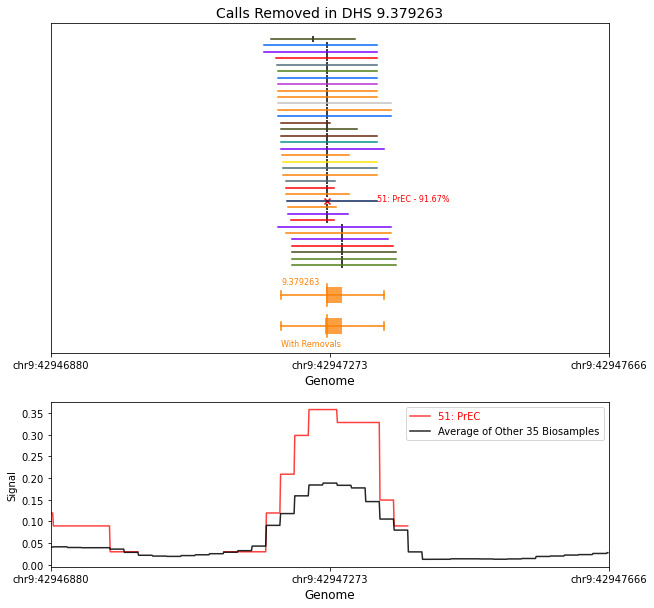

Calls Removed in DHS 12.675498


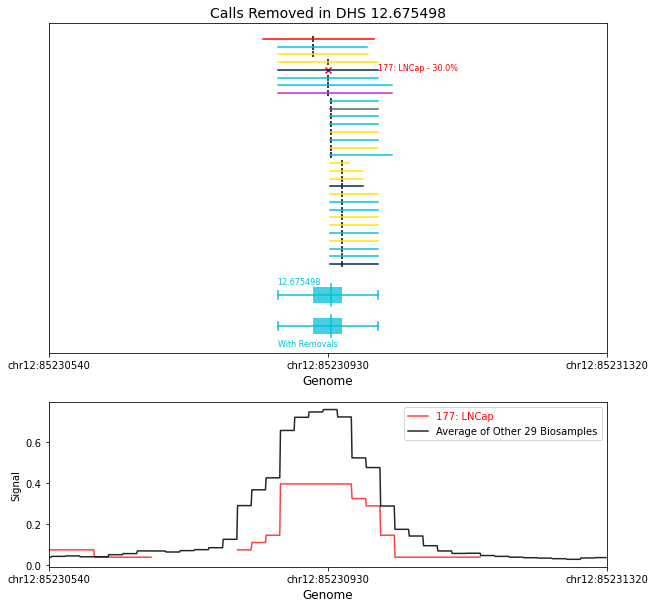

Calls Removed in DHS 4.304978


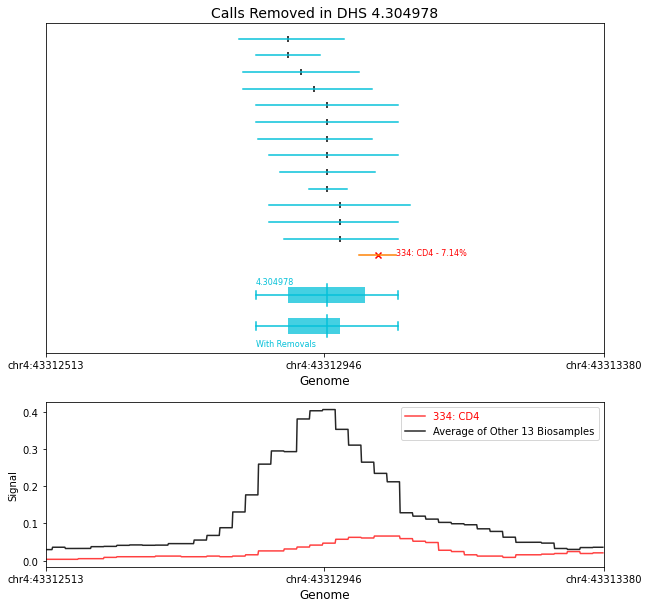

Calls Removed in DHS 9.581266


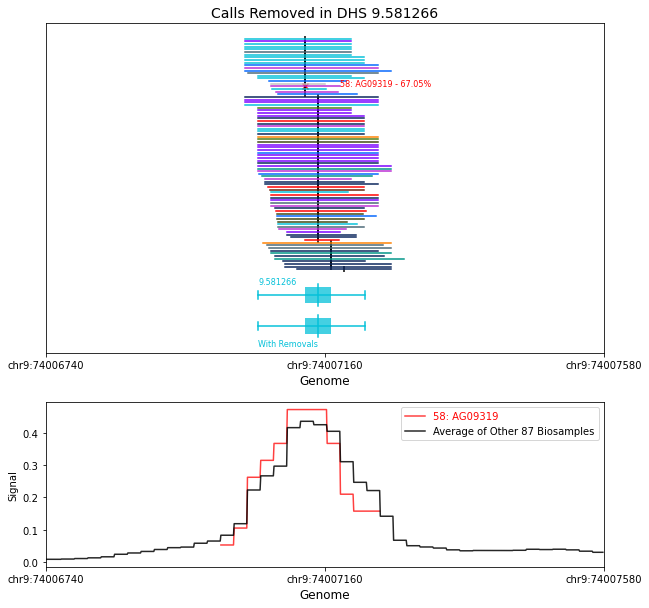

Calls Removed in DHS 4.159826


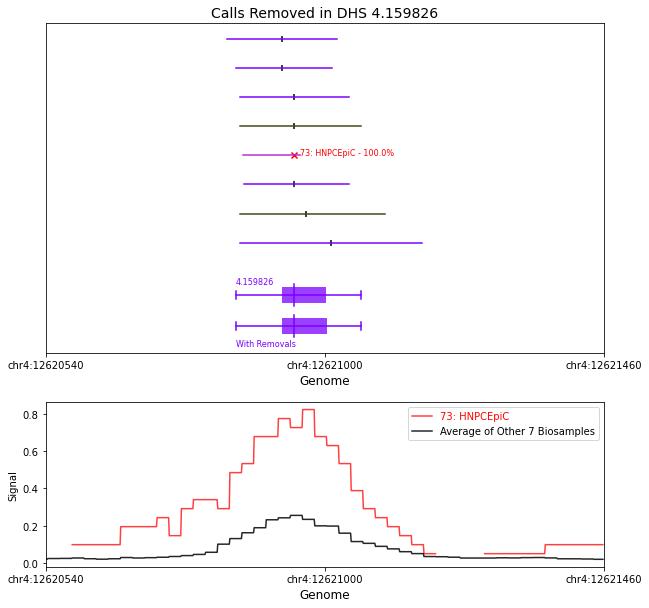

Calls Removed in DHS 2.807071


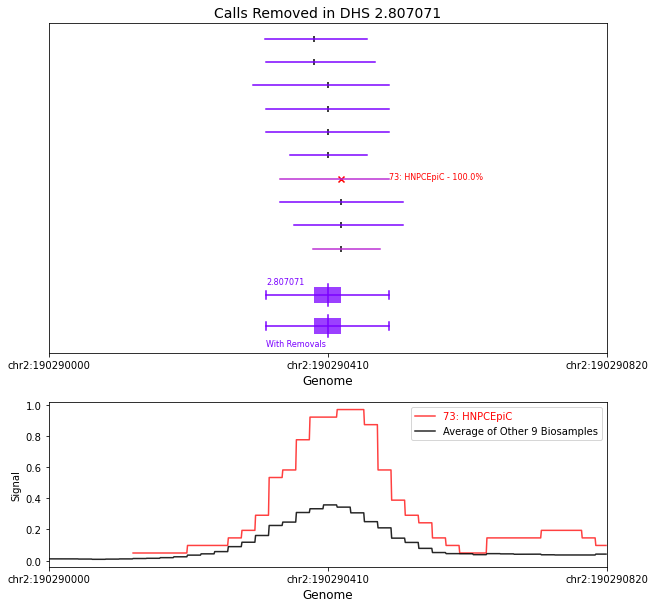

Calls Removed in DHS 20.64143


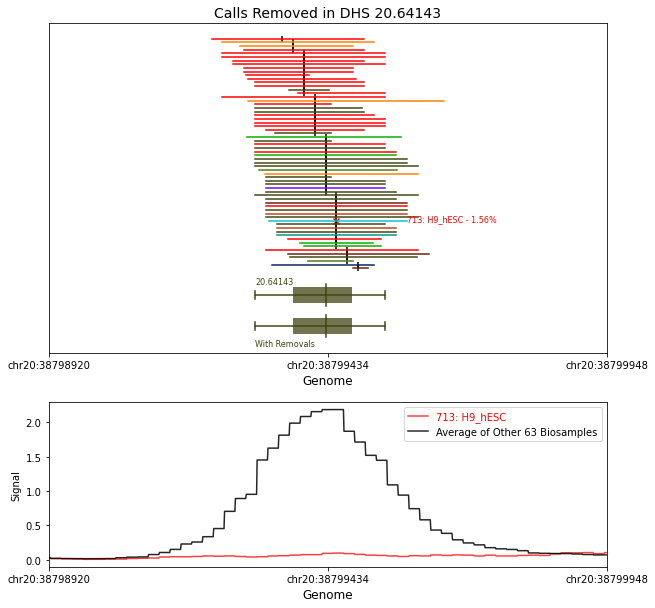

Calls Removed in DHS 2.5053


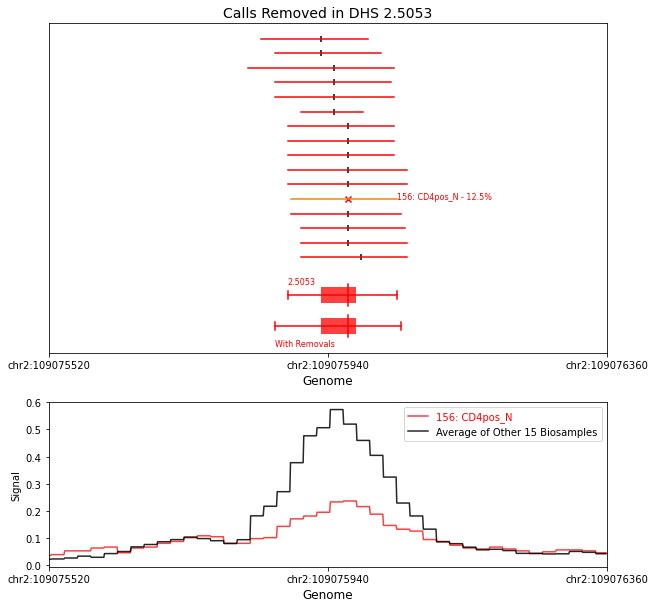

Calls Removed in DHS 1.671844


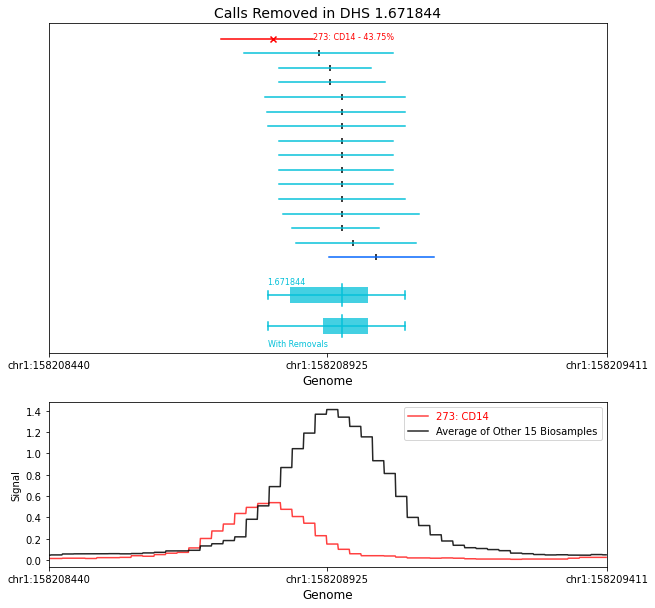

Calls Removed in DHS 3.11505


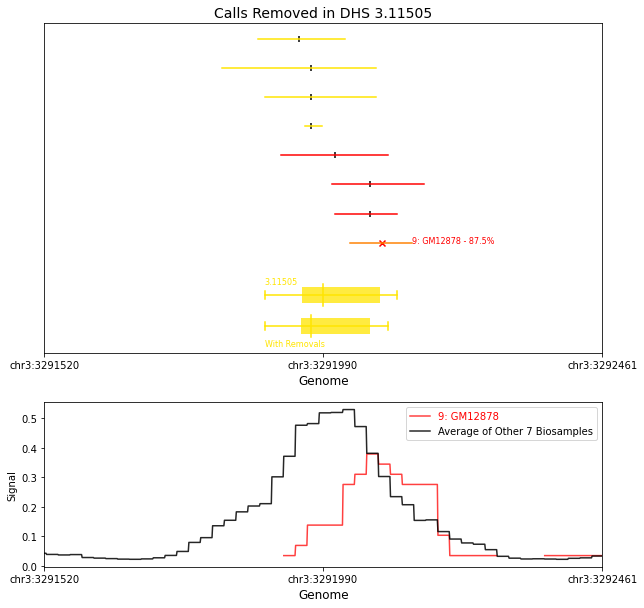

Calls Removed in DHS 8.758671


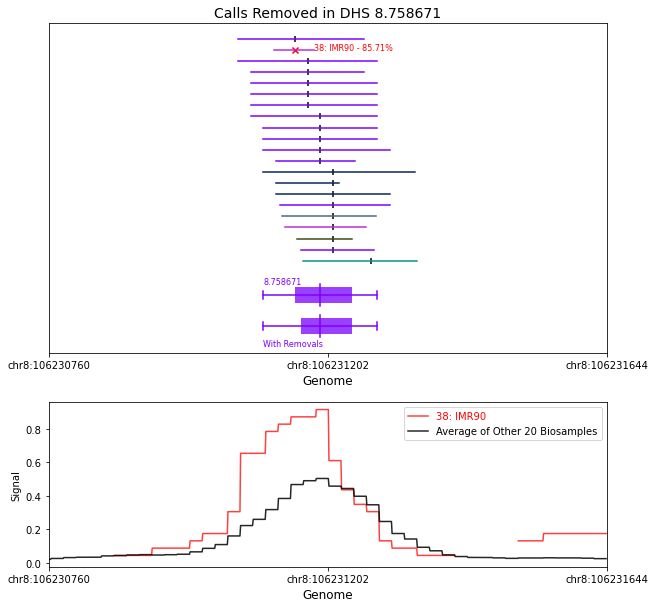

Calls Removed in DHS 4.16449


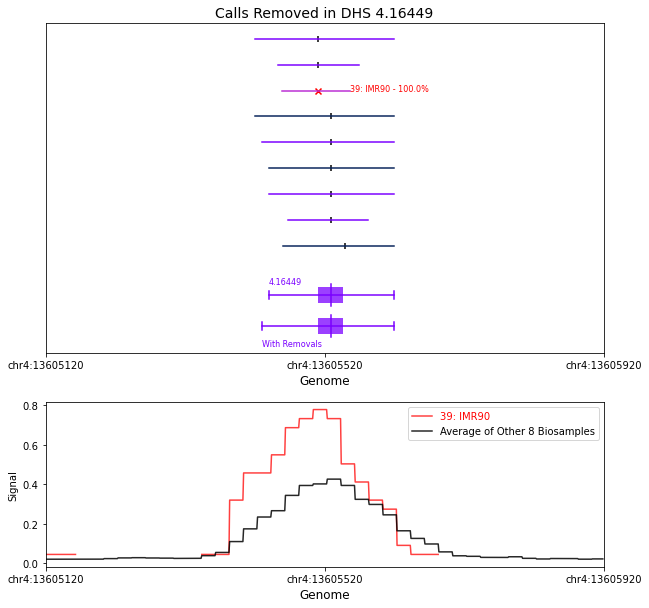

In [71]:
#most isolated DHSs with removed call (bw)
for i in np.argsort(-ordered_removed_call_DHS_mindistances)[:30]:
    plotting_removed_calls(i, signal_type='bw')

In [131]:
pd.set_option('display.max_columns', 15)
biosample_df.loc[[273, 619, 172, 110, 671, 669, 672, 498, 44, 171, 698, 625, 670, 662, 658, 626]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,...,Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
273,274,CD14,NaN,ENCSR452DCM,ENCLB665NTX,ENCBS945EIT,AG9060,...,8850000.0,Buffer A,2010-11-03,384036115,0.5923,147687,147325
619,620,PGP1_iPSC,Primitive / embryonic,ENCSR004SUL,ENCLB440GKD,ENCBS373AAA,AG3966,...,3100000.0,PBS+A,2014-02-28,134911762,0.4053,150758,150360
172,173,NT2_D1,NaN,ENCSR000EPS,ENCLB572ZZZ,ENCBS631LTU,AG4083,...,13800000.0,PBS+A,2010-04-19,33186554,0.3695,71585,71390
110,111,hESCT0,NaN,ENCSR000EMZ,ENCLB450ZZZ,ENCBS297CQV,AG4132,...,NaN,NaN,2009-11-16,22028913,0.5993,65076,64970
671,672,H9_DN3_early,Primitive / embryonic,ENCSR754LIN,ENCLB139ECN,ENCBS140HIH,AG3993,...,530000.0,PBS+A,2015-02-04,251853460,0.3489,121699,121229
669,670,H9_AzH_G2M,Primitive / embryonic,ENCSR943SYS,ENCLB458DKR,ENCBS417MAQ,AG3995,...,840000.0,PBS+A,2015-02-04,305263488,0.3779,153673,153071
672,673,H9_KO2_late,NaN,ENCSR964WHY,ENCLB666KBT,ENCBS853WXF,AG3992,...,818000.0,PBS+A,2015-02-04,375861620,0.3282,102588,101986
498,499,iPS_19_11,Primitive / embryonic,ENCSR383SNM,ENCLB521KWF,ENCBS087RTK,AG8844,...,10800000.0,PBS,2010-05-26,289623335,0.4154,207795,207293
44,45,hESCT0,Primitive / embryonic,ENCSR000EMZ,ENCLB449ZZZ,ENCBS293AAA,AG4188,...,NaN,NaN,2009-08-19,240791918,0.6453,315568,314868
171,172,NT2_D1,NaN,ENCSR000EPS,ENCLB571ZZZ,ENCBS578HFO,AG4084,...,9500000.0,PBS+A,40287,20876533,0.3238,46523,46433


**To compare with specific cases, distance and score histograms**

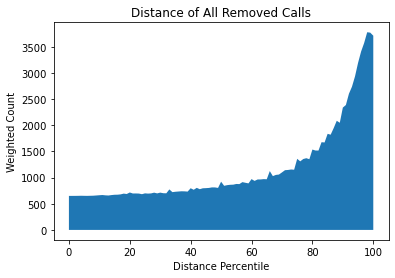

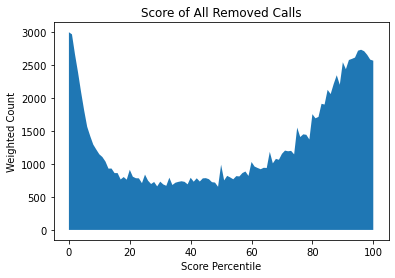

In [192]:
#weighted percentile approach
#0biosample_ind, 1DHS ind, 2distance lower, 3distance higher, 4distance weight
#5score lower, 6score higher, 7score weight, 8urdc ind
removed_call_score_percentile_plot = np.zeros(101)
removed_call_distance_percentile_plot = np.zeros(101)

for removed_call_info in removed_call_cross_fullpercentilerange_track:
    
    removed_call_distance_percentile_plot[int(removed_call_info[2]):
                                          int(removed_call_info[3])+1] += removed_call_info[4]#adding pseudo count
    
    
    removed_call_score_percentile_plot[int(removed_call_info[5]):
                                       int(removed_call_info[6])+1] += removed_call_info[7]#adding pseudo count
    

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_distance_percentile_plot)), removed_call_distance_percentile_plot)
plt.xlabel('Distance Percentile')
plt.ylabel('Weighted Count')
plt.title('Distance of All Removed Calls')
plt.show()

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_score_percentile_plot)), removed_call_score_percentile_plot)
plt.xlabel('Score Percentile')
plt.ylabel('Weighted Count')
plt.title('Score of All Removed Calls')
plt.show()

In [254]:
#weighted distance percentile average for all removed calls
np.sum(removed_call_distance_percentile_plot*np.arange(101))/np.sum(removed_call_distance_percentile_plot)

65.20613341422306

In [253]:
#weighted score percentile average for all removed calls
np.sum(removed_call_score_percentile_plot*np.arange(101))/np.sum(removed_call_score_percentile_plot)

56.57728006533106

DescribeResult(nobs=22569, minmax=(1, 99), mean=65.41220257875847, variance=797.953309084093, skewness=-0.5404676672123124, kurtosis=-1.0585961168340223)


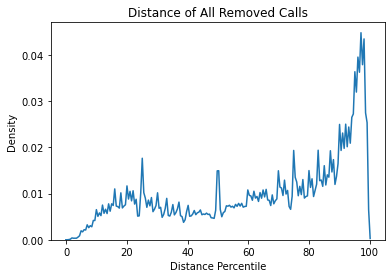

DescribeResult(nobs=22569, minmax=(0, 99), mean=48.8032699720856, variance=1152.5274955102827, skewness=-0.06356002054207957, kurtosis=-1.480751732659603)


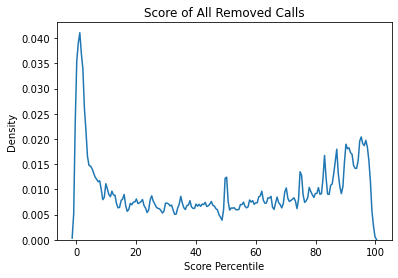

In [54]:
#[biosample ind, DHS ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
distance_percentiles_all_calls = removed_call_cross_percentile_track[:, 2]
score_percentiles_all_calls = removed_call_cross_percentile_track[:, 3]
#distance
fig = kde_wrapper(distance_percentiles_all_calls)
plt.xlabel('Distance Percentile')
plt.title('Distance of All Removed Calls')
plt.show()
#score
fig = kde_wrapper(score_percentiles_all_calls)
plt.xlabel('Score Percentile')
plt.title('Score of All Removed Calls')
plt.show()

In [189]:
#weighted percentile approach
#0biosample_ind, 1DHS ind, 2distance lower, 3distance higher, 4distance weight
#5score lower, 6score higher, 7score weight, 8urdc ind

weighted_score_ave_all_biosamples = []
weighted_distance_ave_all_biosamples = []
for ind in range(733):
    
    local_row_inds_ind = np.where(removed_call_cross_fullpercentilerange_track[:, 0]==ind)[0]
    removed_call_fullpercentilerange_track_ind = removed_call_cross_fullpercentilerange_track[local_row_inds_ind, :]

    removed_call_score_percentile_plot_ind = np.zeros(101)
    removed_call_distance_percentile_plot_ind = np.zeros(101)
    for removed_call_info in removed_call_fullpercentilerange_track_ind:

        removed_call_distance_percentile_plot_ind[int(removed_call_info[2]):
                                                 int(removed_call_info[3])+1] += removed_call_info[4]#adding pseudo count

        removed_call_score_percentile_plot_ind[int(removed_call_info[5]):
                                              int(removed_call_info[6])+1] += removed_call_info[7]#adding pseudo count

    weighted_score_ave = np.sum(removed_call_score_percentile_plot_ind*np.arange(101))/np.sum(removed_call_score_percentile_plot_ind)
    weighted_distance_ave = np.sum(removed_call_distance_percentile_plot_ind*np.arange(101))/np.sum(removed_call_distance_percentile_plot_ind)
    
    weighted_score_ave_all_biosamples.append(weighted_score_ave)
    weighted_distance_ave_all_biosamples.append(weighted_distance_ave)
    
weighted_score_ave_all_biosamples = np.array(weighted_score_ave_all_biosamples)
weighted_distance_ave_all_biosamples = np.array(weighted_distance_ave_all_biosamples)

/tmp/ipykernel_54159/1728004297.py:22: RuntimeWarning: invalid value encountered in double_scalars
  weighted_score_ave = np.sum(removed_call_score_percentile_plot_ind*np.arange(101))/np.sum(removed_call_score_percentile_plot_ind)
/tmp/ipykernel_54159/1728004297.py:23: RuntimeWarning: invalid value encountered in double_scalars
  weighted_distance_ave = np.sum(removed_call_distance_percentile_plot_ind*np.arange(101))/np.sum(removed_call_distance_percentile_plot_ind)


In [148]:
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

flipped_biosample_inds = np.append(added_biosample_inds, removed_biosample_inds)
flipped_DHS_inds = np.append(added_DHS_inds, removed_DHS_inds)

In [251]:
np.sum(np.bincount(flipped_biosample_inds)[np.bincount(flipped_biosample_inds)>250])/69292

0.4614529815851758

Text(0.5, 1.0, 'Weighted Mean Score with Number of Flipped Calls')

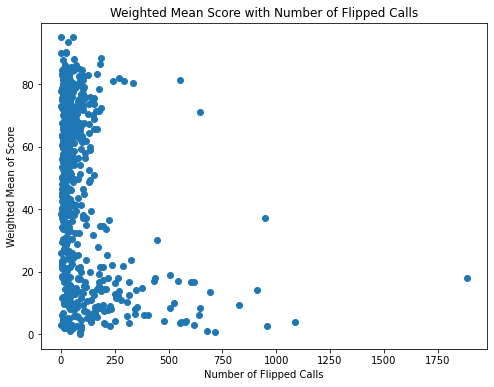

In [258]:
# biosamples_by_flip = np.argsort(-np.bincount(flipped_biosample_inds))
# biosamples_by_removed = np.argsort(-np.bincount(removed_biosample_inds))
# weighted_score_ave_biosamples_by_flip = weighted_score_ave_all_biosamples[biosamples_by_flip]
# weighted_score_ave_biosamples_by_removed = weighted_score_ave_all_biosamples[biosamples_by_removed]

fig = plt.figure(figsize=(8, 6))
fig.patch.set_facecolor('white')

plt.scatter(np.bincount(flipped_biosample_inds), weighted_score_ave_all_biosamples)

plt.xlabel('Number of Flipped Calls')
plt.ylabel('Weighted Mean of Score')
plt.title('Weighted Mean Score with Number of Flipped Calls')

**Specific Cases (See quality_of_NMF_recon_threshold_flip_01thresh_specific_cases) - Biosample 44**

In [37]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

DHS 10.119574


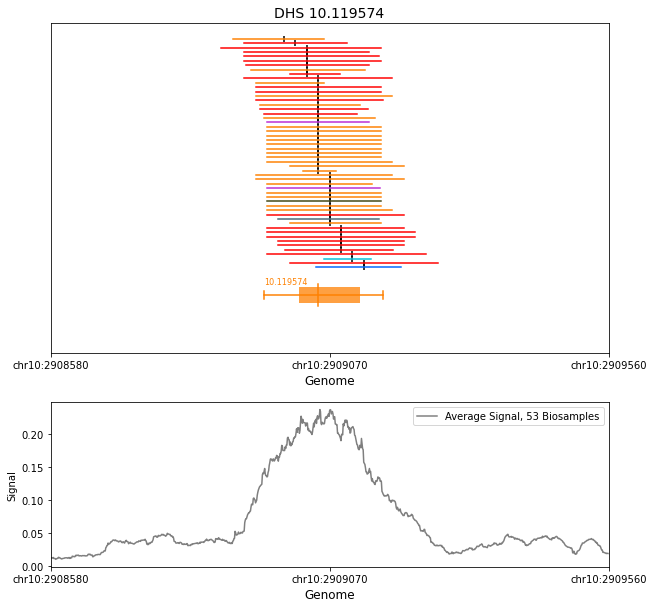

DHS 10.111486


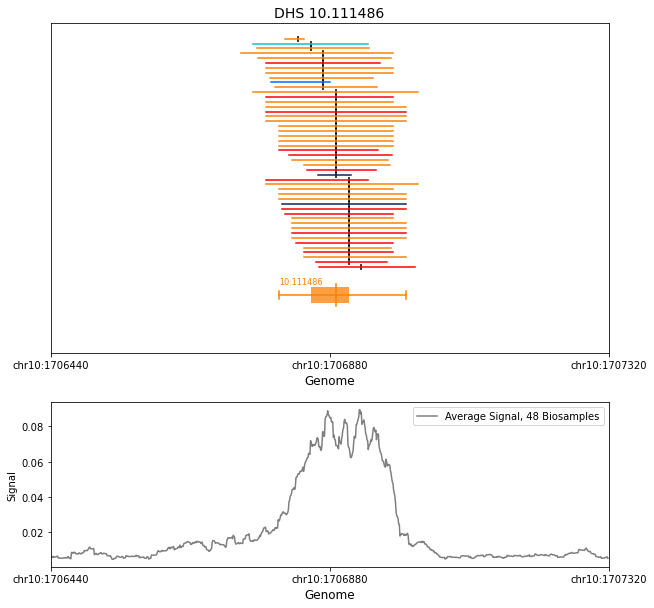

DHS 1.9528596


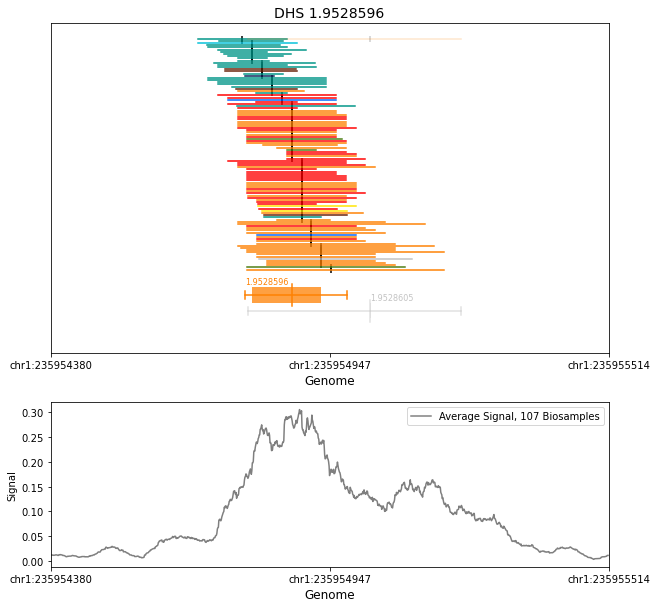

DHS 3.214352


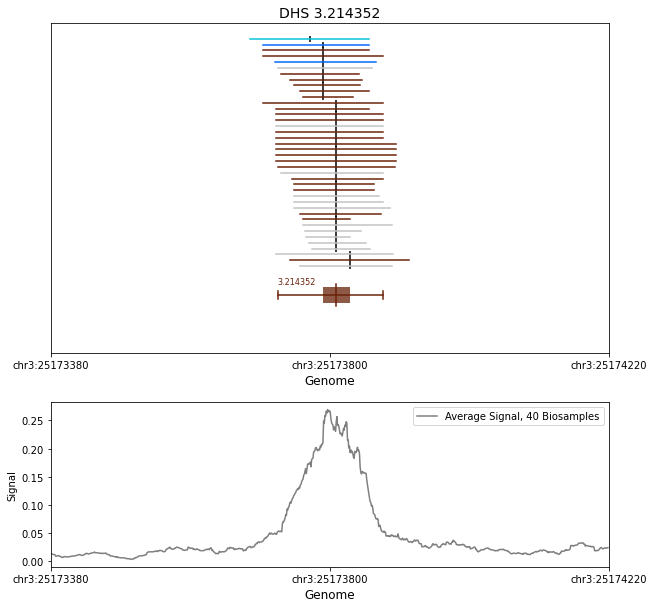

DHS 3.116067


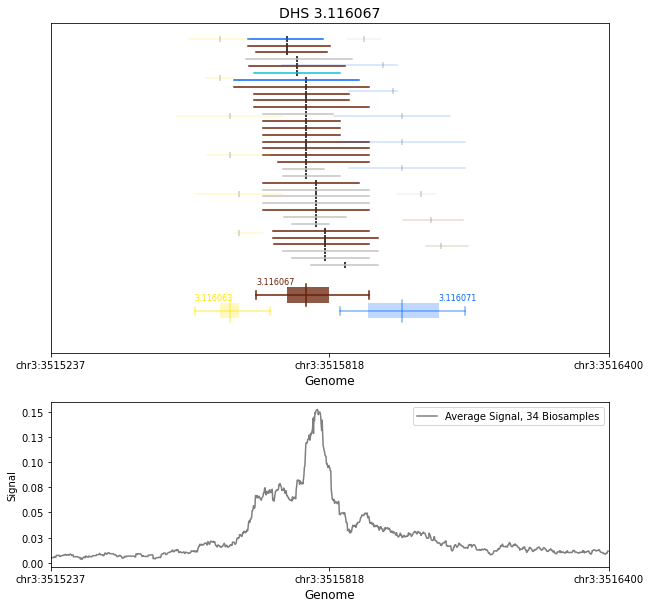

DHS 20.66042


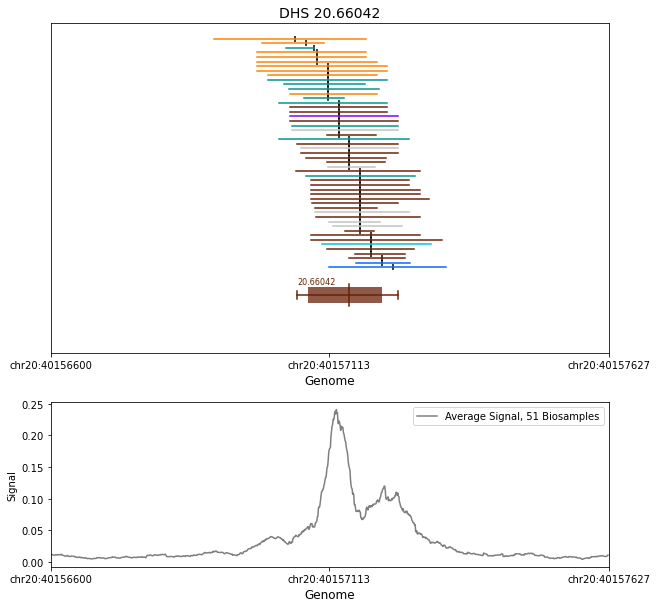

In [26]:
DHSs_with_44_removed = removed_DHS_inds[removed_biosample_inds==44]
comps_for_DHSs_with_44_removed = mixture_all_cycles_top_comp[0, DHSs_with_44_removed]
DHSs_with_44_removed_comp4 = DHSs_with_44_removed[comps_for_DHSs_with_44_removed==4]
for i in DHSs_with_44_removed_comp4[:3]:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True, pre_removal_ave=True, pre_removal_view=True)
DHSs_with_44_removed_comp9 = DHSs_with_44_removed[comps_for_DHSs_with_44_removed==9]
for i in DHSs_with_44_removed_comp9[:3]:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True, pre_removal_ave=True, pre_removal_view=True)

Distance of Removed Calls - Biosample 44: hESCT0


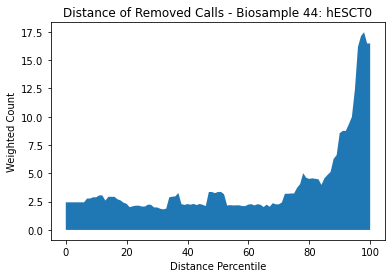

Score of Removed Calls - Biosample 44: hESCT0


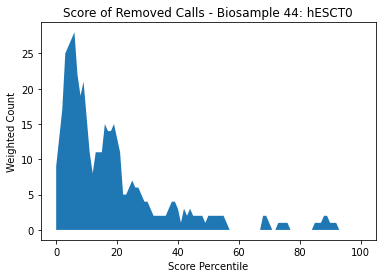

In [260]:
#weighted percentile approach
#0biosample_ind, 1DHS ind, 2distance lower, 3distance higher, 4distance weight
#5score lower, 6score higher, 7score weight, 8urdc ind

local_row_inds_44 = np.where(removed_call_cross_fullpercentilerange_track[:, 0]==44)[0]
removed_call_fullpercentilerange_track_44 = removed_call_cross_fullpercentilerange_track[local_row_inds_44, :]

removed_call_score_percentile_plot_44 = np.zeros(101)
removed_call_distance_percentile_plot_44 = np.zeros(101)

for removed_call_info in removed_call_fullpercentilerange_track_44:
    
    removed_call_distance_percentile_plot_44[int(removed_call_info[2]):
                                             int(removed_call_info[3])+1] += removed_call_info[4]#adding pseudo count
    
    
    
    removed_call_score_percentile_plot_44[int(removed_call_info[5]):
                                          int(removed_call_info[6])+1] += removed_call_info[7]#adding pseudo count
    
    

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_distance_percentile_plot_44)), removed_call_distance_percentile_plot_44)
plt.xlabel('Distance Percentile')
plt.ylabel('Weighted Count')
title = 'Distance of Removed Calls - Biosample 44: hESCT0'
plt.title(title)
print(title)
plt.show()

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_score_percentile_plot_44)), removed_call_score_percentile_plot_44)
plt.xlabel('Score Percentile')
plt.ylabel('Weighted Count')
title = 'Score of Removed Calls - Biosample 44: hESCT0'
plt.title(title)
print(title)
plt.show()


In [195]:
np.sum(removed_call_score_percentile_plot_44*np.arange(101))/np.sum(removed_call_score_percentile_plot_44)

17.83817427385892

DescribeResult(nobs=130, minmax=(6, 99), mean=64.44615384615385, variance=900.2490161001789, skewness=-0.5170684502798358, kurtosis=-1.152192762942394)


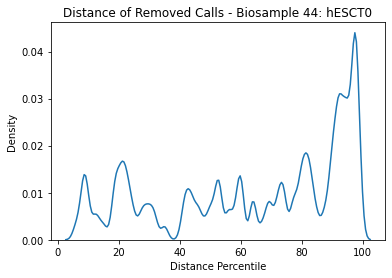

DescribeResult(nobs=130, minmax=(0, 90), mean=16.753846153846155, variance=304.32653548002384, skewness=2.032664506752031, kurtosis=4.533063781136393)


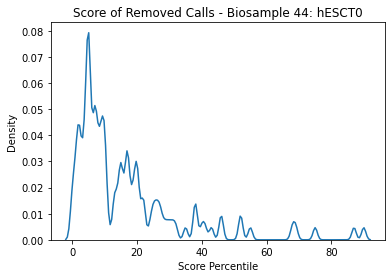

In [47]:
#[biosample ind, DHS ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
local_row_inds_44 = np.where(removed_call_cross_percentile_track[:, 0]==44)[0]
distance_percentiles_44 = removed_call_cross_percentile_track[local_row_inds_44, 2]
score_percentiles_44 = removed_call_cross_percentile_track[local_row_inds_44, 3]
#distance
fig = kde_wrapper(distance_percentiles_44)
plt.xlabel('Distance Percentile')
plt.title('Distance of Removed Calls - Biosample 44: hESCT0')
plt.show()
#score
fig = kde_wrapper(score_percentiles_44)
plt.xlabel('Score Percentile')
plt.title('Score of Removed Calls - Biosample 44: hESCT0')
plt.show()

**Specific Cases (See quality_of_NMF_recon_threshold_flip_01thresh_specific_cases) - Biosample 715**

DHS 1.217036


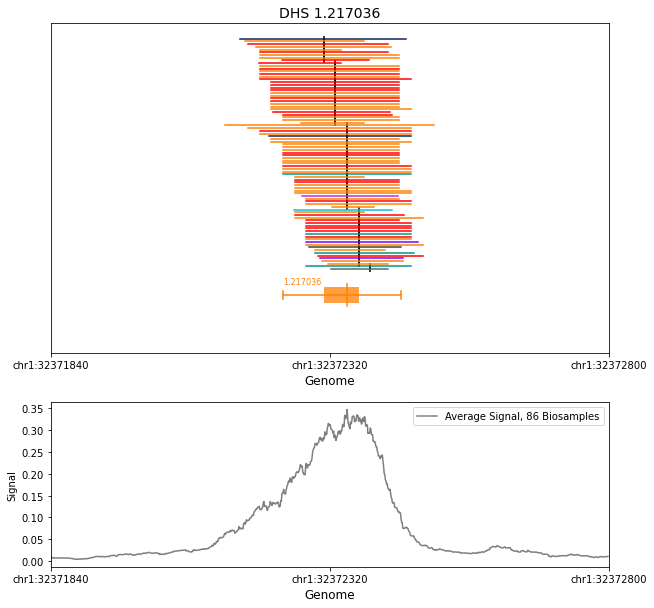

DHS 1.215103


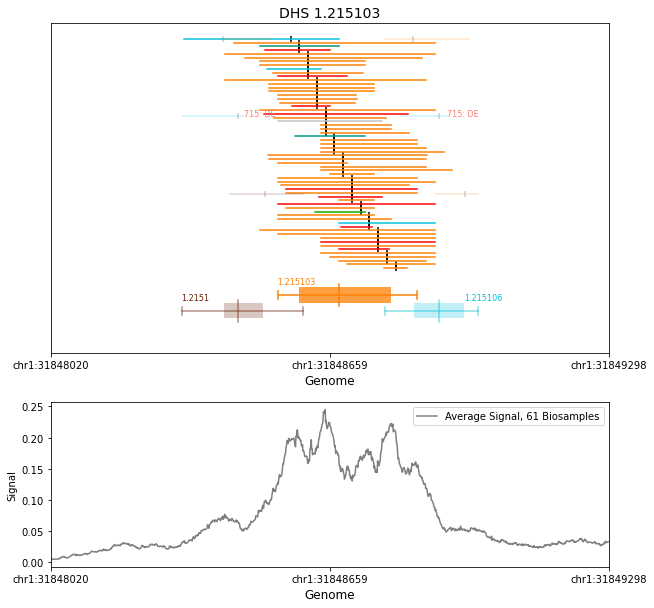

DHS 1.199939


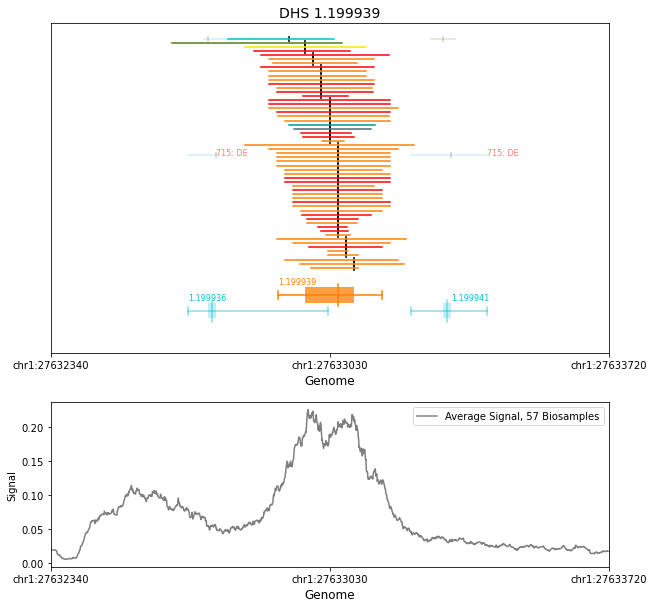

DHS 1.138008


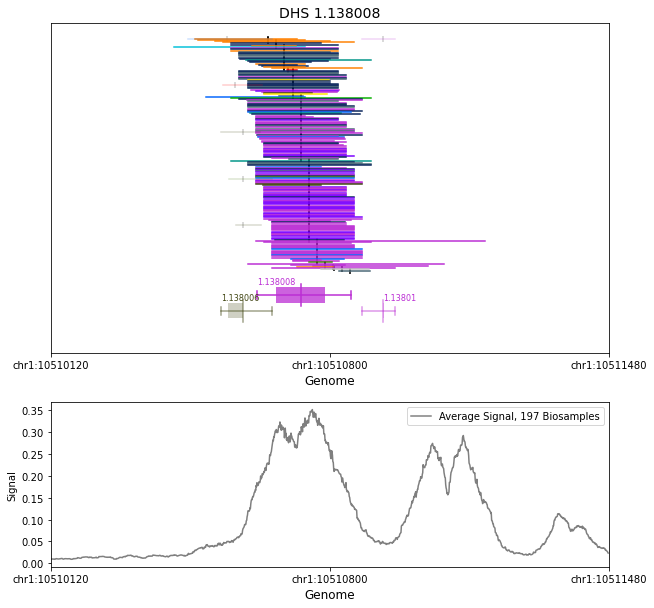

DHS 10.6666719


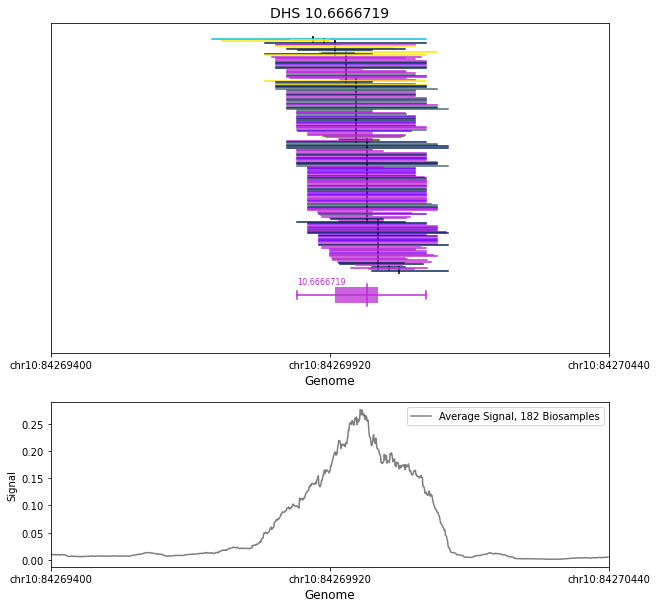

DHS 1.6543616


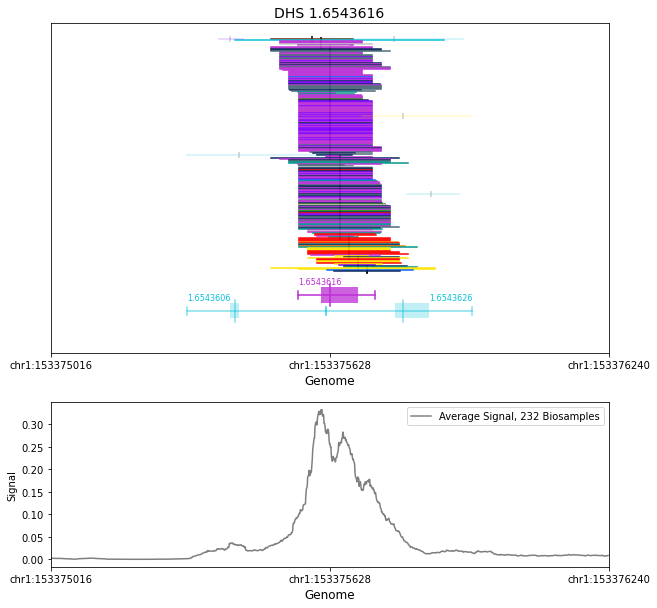

In [27]:
DHSs_with_715_removed = removed_DHS_inds[removed_biosample_inds==715]
comps_for_DHSs_with_715_removed = mixture_all_cycles_top_comp[0, DHSs_with_715_removed]
DHSs_with_715_removed_comp4 = DHSs_with_715_removed[comps_for_DHSs_with_715_removed==4]
for i in DHSs_with_715_removed_comp4[:3]:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True, pre_removal_ave=True, pre_removal_view=True)
DHSs_with_715_removed_comp1 = DHSs_with_715_removed[comps_for_DHSs_with_715_removed==1]
for i in DHSs_with_715_removed_comp1[:3]:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True, pre_removal_ave=True, pre_removal_view=True)

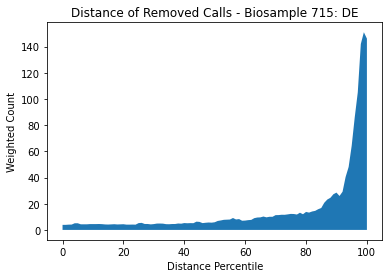

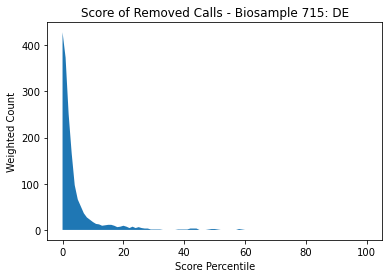

In [196]:
#weighted percentile approach
#0biosample_ind, 1DHS ind, 2distance lower, 3distance higher, 4distance weight
#5score lower, 6score higher, 7score weight, 8urdc ind

local_row_inds_715 = np.where(removed_call_cross_fullpercentilerange_track[:, 0]==715)[0]
removed_call_fullpercentilerange_track_715 = removed_call_cross_fullpercentilerange_track[local_row_inds_715, :]

removed_call_score_percentile_plot_715 = np.zeros(101)
removed_call_distance_percentile_plot_715 = np.zeros(101)
for removed_call_info in removed_call_fullpercentilerange_track_715:
    
    removed_call_distance_percentile_plot_715[int(removed_call_info[2]):
                                             int(removed_call_info[3])+1] += removed_call_info[4]#adding pseudo count
    
    removed_call_score_percentile_plot_715[int(removed_call_info[5]):
                                          int(removed_call_info[6])+1] += removed_call_info[7]#adding pseudo count

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_distance_percentile_plot_715)), removed_call_distance_percentile_plot_715)
plt.xlabel('Distance Percentile')
plt.ylabel('Weighted Count')
plt.title('Distance of Removed Calls - Biosample 715: DE')
plt.show()

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_score_percentile_plot_715)), removed_call_score_percentile_plot_715)
plt.xlabel('Score Percentile')
plt.ylabel('Weighted Count')
plt.title('Score of Removed Calls - Biosample 715: DE')
plt.show()

In [197]:
np.sum(removed_call_score_percentile_plot_715*np.arange(101))/np.sum(removed_call_score_percentile_plot_715)

3.977581120943953

DescribeResult(nobs=622, minmax=(5, 99), mean=76.16720257234726, variance=706.8415634983509, skewness=-1.1544743537279984, kurtosis=0.1135648635289126)


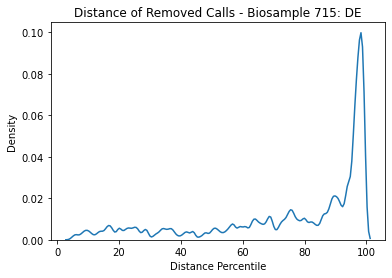

DescribeResult(nobs=622, minmax=(0, 58), mean=2.985530546623794, variance=45.51508820437941, skewness=4.702027696377394, kurtosis=27.297971806002185)


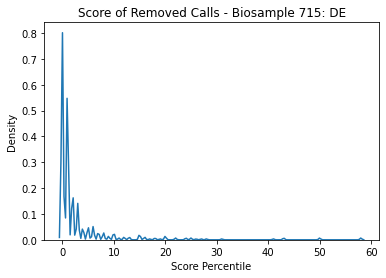

In [49]:
#[biosample ind, DHS ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
local_row_inds_715 = np.where(removed_call_cross_percentile_track[:, 0]==715)[0]
distance_percentiles_715 = removed_call_cross_percentile_track[local_row_inds_715, 2]
score_percentiles_715 = removed_call_cross_percentile_track[local_row_inds_715, 3]
#distance
fig = kde_wrapper(distance_percentiles_715)
plt.xlabel('Distance Percentile')
plt.title('Distance of Removed Calls - Biosample 715: DE')
plt.show()
#score
fig = kde_wrapper(score_percentiles_715)
plt.xlabel('Score Percentile')
plt.title('Score of Removed Calls - Biosample 715: DE')
plt.show()

**Specific Cases (See quality_of_NMF_recon_threshold_flip_01thresh_specific_cases) - Biosample 102**

DHS 7.4136682


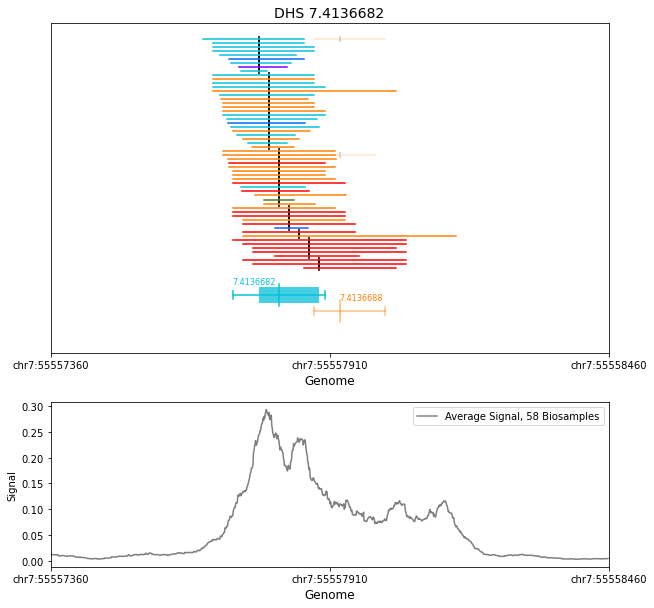

DHS 4.903983


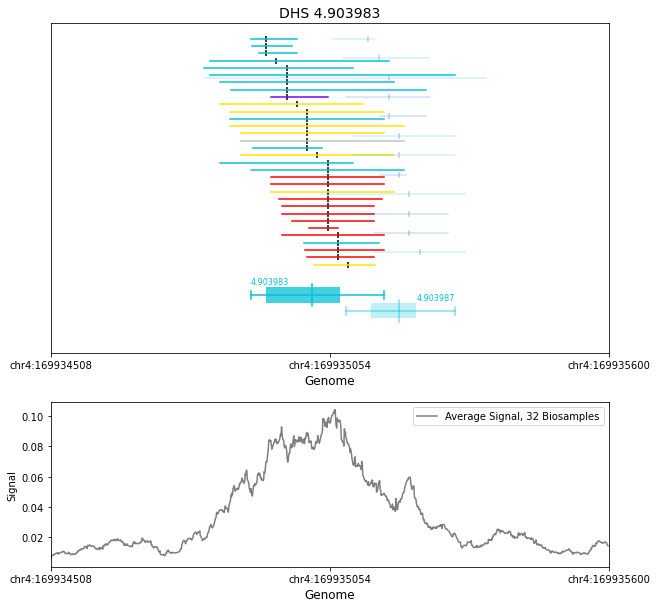

DHS 15.910456


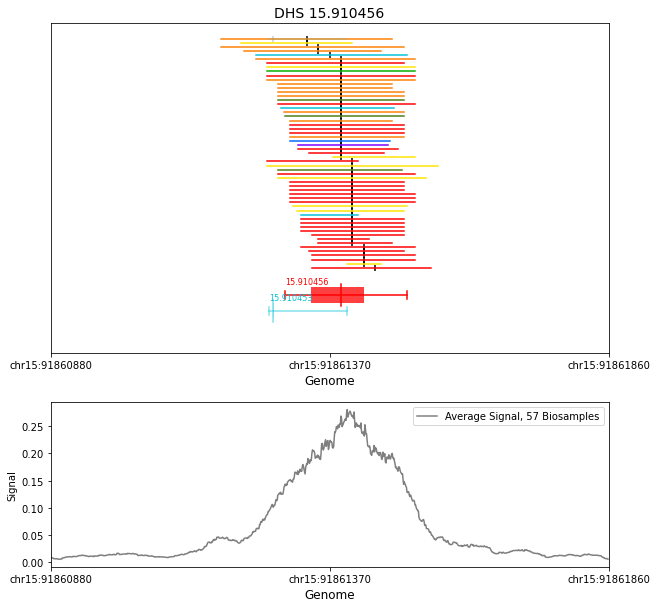

DHS 19.39551


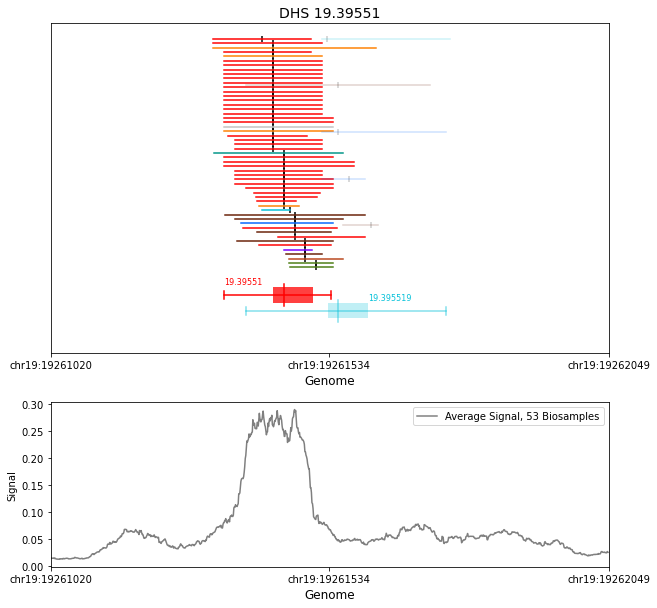

In [28]:
DHSs_with_102_removed = removed_DHS_inds[removed_biosample_inds==102]
comps_for_DHSs_with_102_removed = mixture_all_cycles_top_comp[0, DHSs_with_102_removed]
DHSs_with_102_removed_comp2 = DHSs_with_102_removed[comps_for_DHSs_with_102_removed==2]
for i in DHSs_with_102_removed_comp2[:3]:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True, pre_removal_ave=True, pre_removal_view=True)
DHSs_with_102_removed_comp14 = DHSs_with_102_removed[comps_for_DHSs_with_102_removed==14]
for i in DHSs_with_102_removed_comp14[:3]:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True, pre_removal_ave=True, pre_removal_view=True)

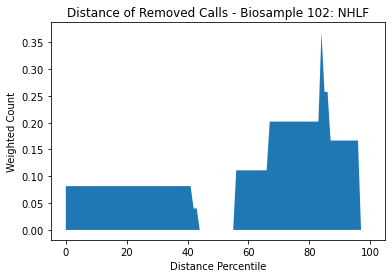

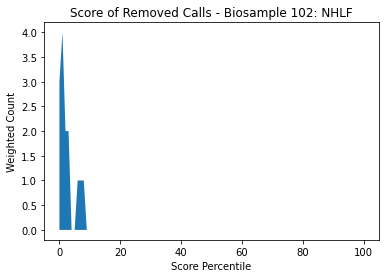

In [198]:
#weighted percentile approach
#0biosample_ind, 1DHS ind, 2distance lower, 3distance higher, 4distance weight
#5score lower, 6score higher, 7score weight, 8urdc ind

local_row_inds_102 = np.where(removed_call_cross_fullpercentilerange_track[:, 0]==102)[0]
removed_call_fullpercentilerange_track_102 = removed_call_cross_fullpercentilerange_track[local_row_inds_102, :]

removed_call_score_percentile_plot_102 = np.zeros(101)
removed_call_distance_percentile_plot_102 = np.zeros(101)
for removed_call_info in removed_call_fullpercentilerange_track_102:
    
    removed_call_distance_percentile_plot_102[int(removed_call_info[2]):
                                             int(removed_call_info[3])+1] += removed_call_info[4]#adding pseudo count
    
    removed_call_score_percentile_plot_102[int(removed_call_info[5]):
                                          int(removed_call_info[6])+1] += removed_call_info[7]#adding pseudo count

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_distance_percentile_plot_102)), removed_call_distance_percentile_plot_102)
plt.xlabel('Distance Percentile')
plt.ylabel('Weighted Count')
plt.title('Distance of Removed Calls - Biosample 102: NHLF')
plt.show()

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.fill_between(np.arange(len(removed_call_score_percentile_plot_102)), removed_call_score_percentile_plot_102)
plt.xlabel('Score Percentile')
plt.ylabel('Weighted Count')
plt.title('Score of Removed Calls - Biosample 102: NHLF')
plt.show()

In [199]:
np.sum(removed_call_score_percentile_plot_102*np.arange(101))/np.sum(removed_call_score_percentile_plot_102)

2.5

DescribeResult(nobs=5, minmax=(20, 90), mean=55.4, variance=1067.8, skewness=-0.2546842168658123, kurtosis=-1.7311780920213742)


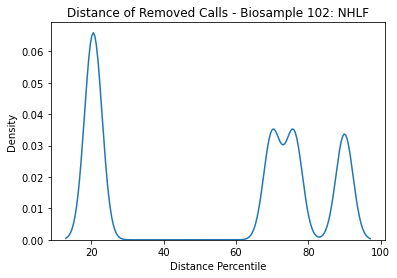

DescribeResult(nobs=5, minmax=(0, 7), mean=2.0, variance=8.5, skewness=1.2181208646399415, kurtosis=-0.1539792387543253)


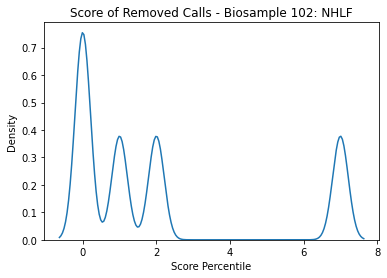

In [51]:
#[biosample ind, DHS ind, distance percentile, score percentile, urdc ind] - removed_call_cross_percentile_track order
local_row_inds_102 = np.where(removed_call_cross_percentile_track[:, 0]==102)[0]
distance_percentiles_102 = removed_call_cross_percentile_track[local_row_inds_102, 2]
score_percentiles_102 = removed_call_cross_percentile_track[local_row_inds_102, 3]
#distance
fig = kde_wrapper(distance_percentiles_102)
plt.xlabel('Distance Percentile')
plt.title('Distance of Removed Calls - Biosample 102: NHLF')
plt.show()
#score
fig = kde_wrapper(score_percentiles_102)
plt.xlabel('Score Percentile')
plt.title('Score of Removed Calls - Biosample 102: NHLF')
plt.show()

**DHSs from Removed Call Upset Plots (see quality_of_NMF_recon_threshold_flip_01thresh_flipped_call_metadata)**

Calls Removed in DHS 8.9052886


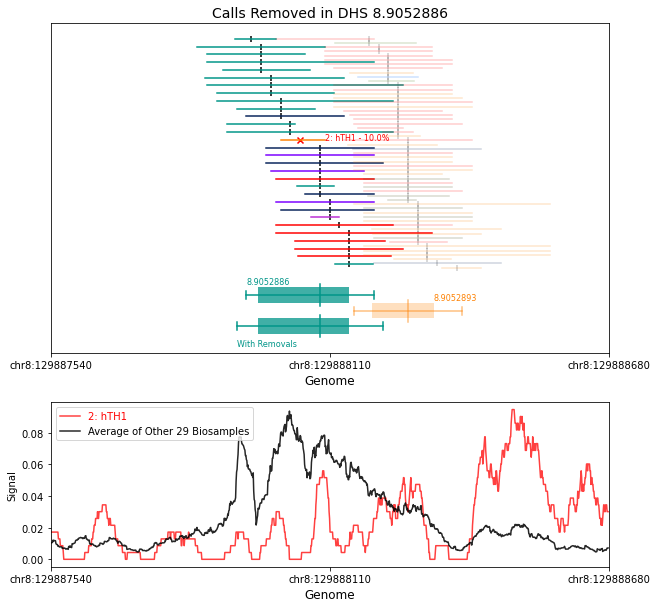

Calls Removed in DHS 9.6920868


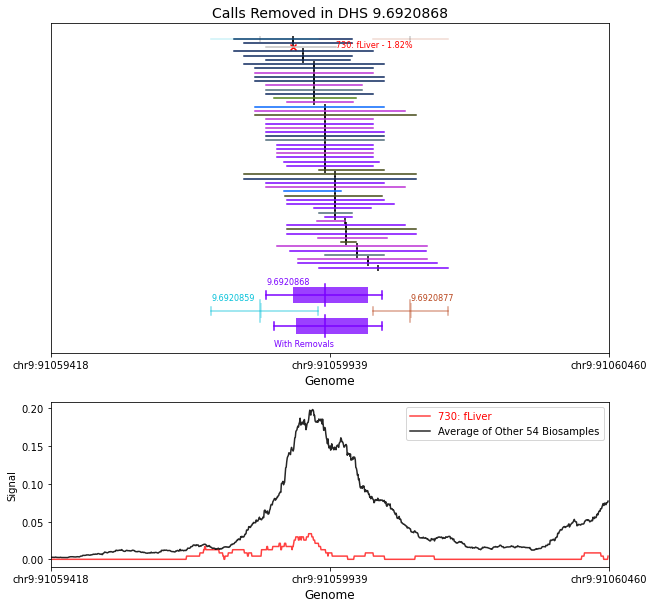

Calls Removed in DHS 9.9480632


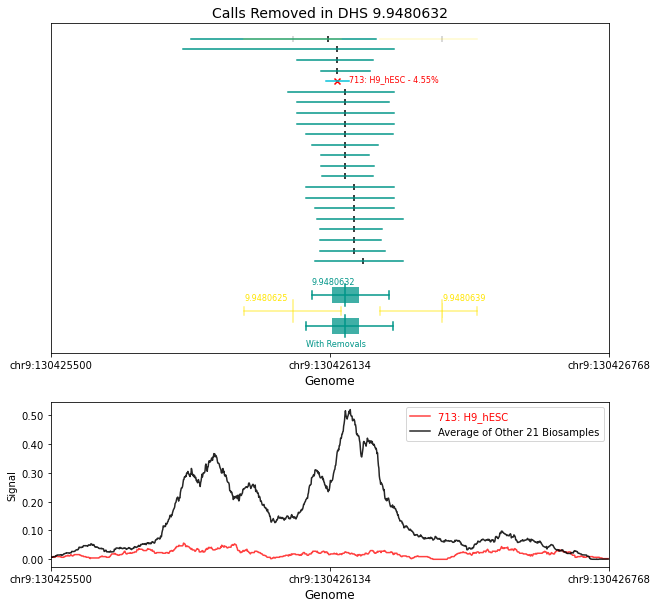

Calls Removed in DHS 6.214156


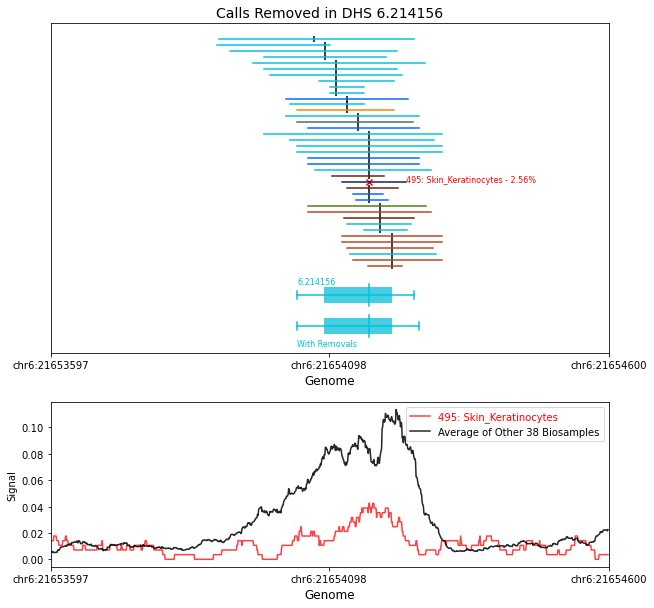

Calls Removed in DHS 15.81537


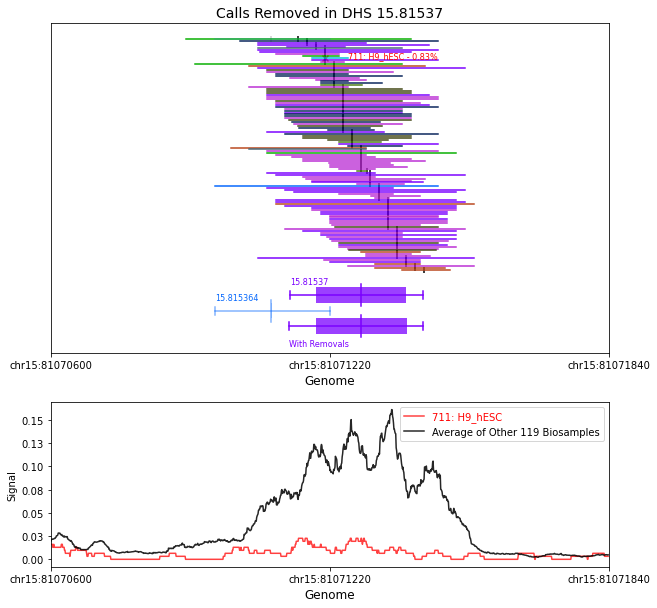

Calls Removed in DHS 19.98498


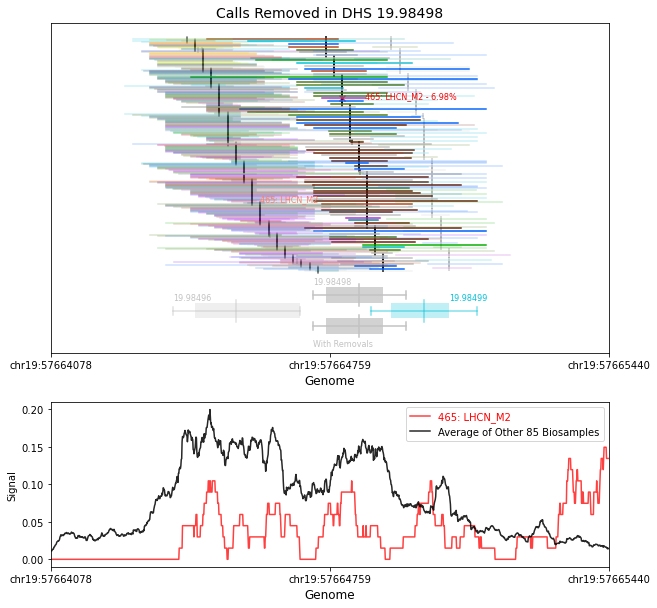

Calls Removed in DHS 9.724763


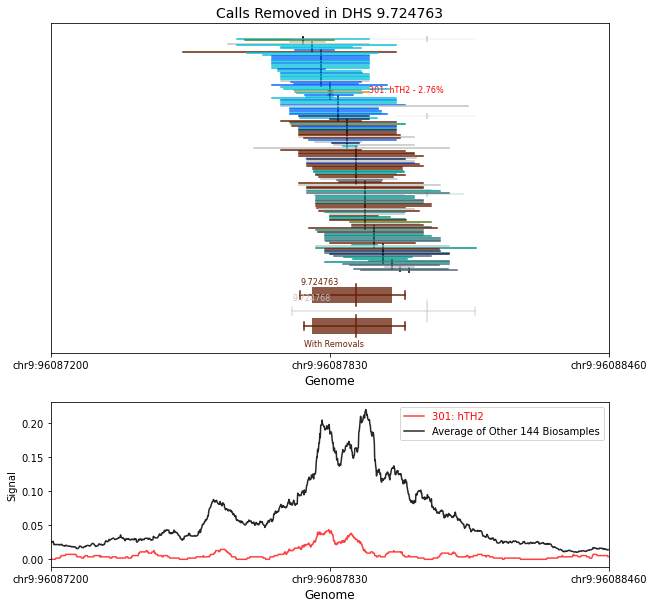

Calls Removed in DHS 21.790706


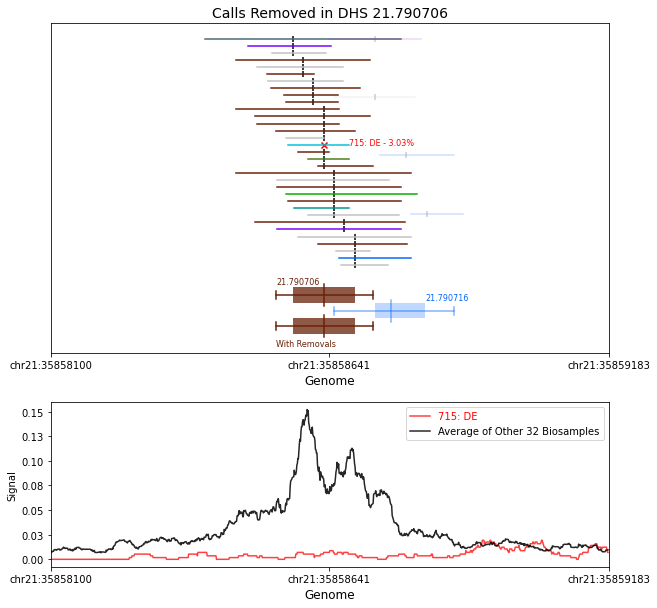

Calls Removed in DHS 14.289256


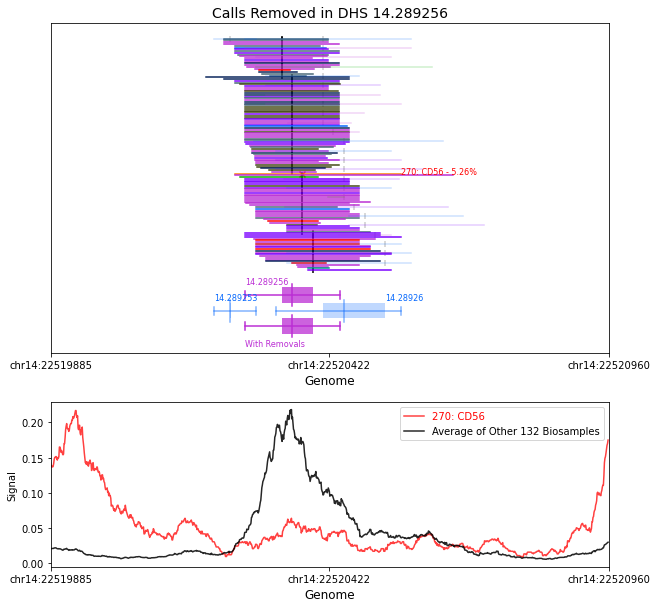

Calls Removed in DHS 1.2206447


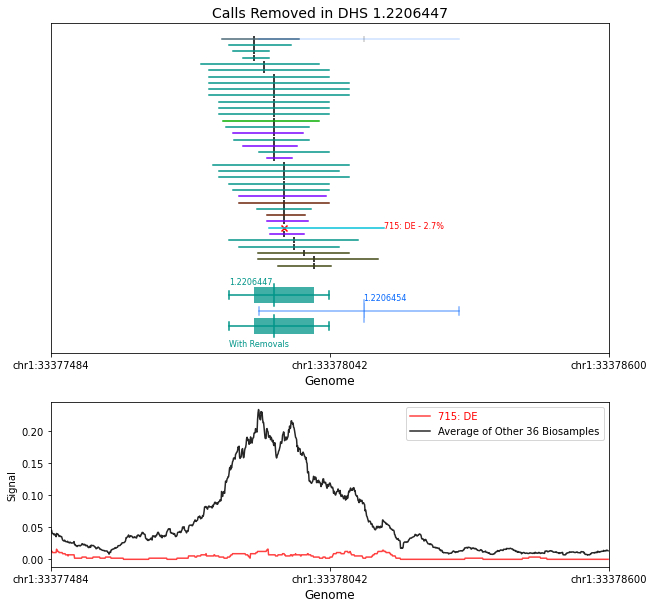

In [33]:
DHSs_to_plot_low_signal_low_distance = [3293189, 3391499, 3448844, 2768910, 1138706, 1572891, 3399711, 1998879,  950318, 57397]

for i in DHSs_to_plot_low_signal_low_distance:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True)

Calls Removed in DHS 2.9570749


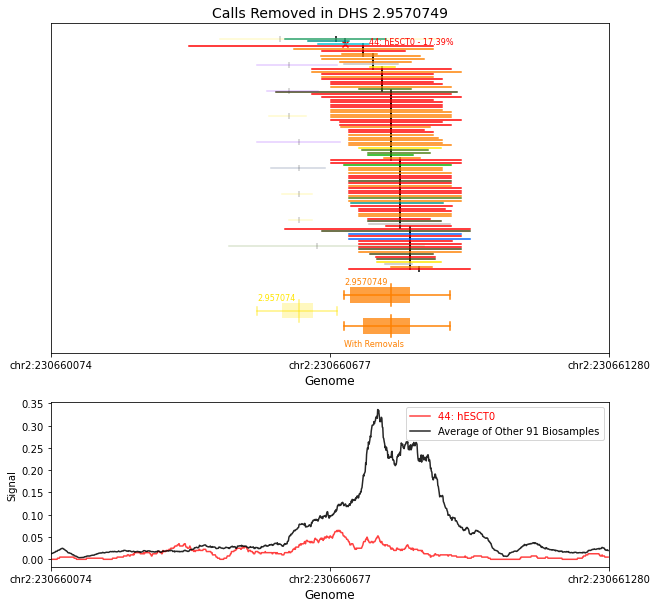

Calls Removed in DHS X.1018964


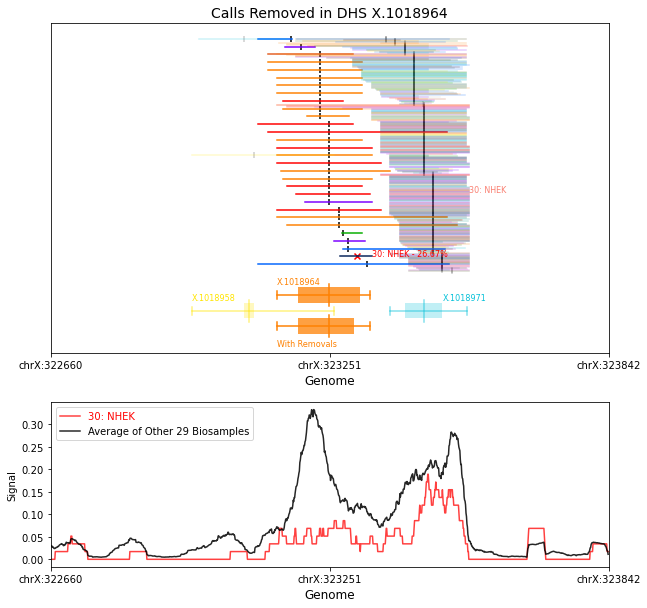

Calls Removed in DHS 6.1015766


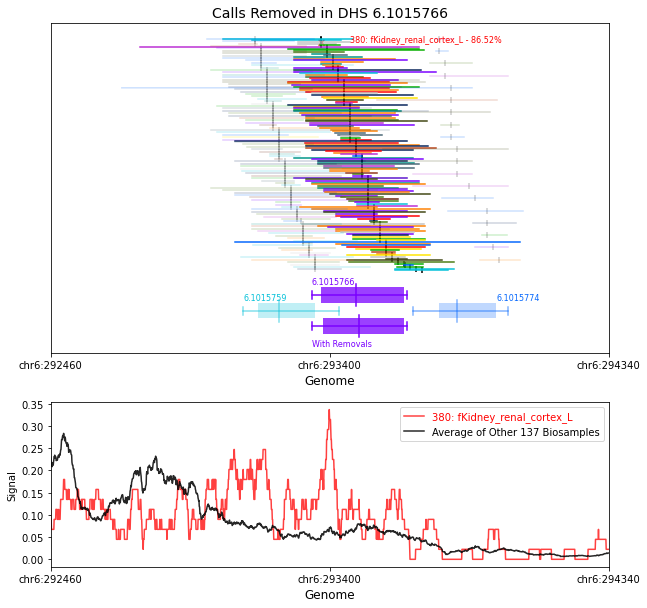

Calls Removed in DHS 2.807985


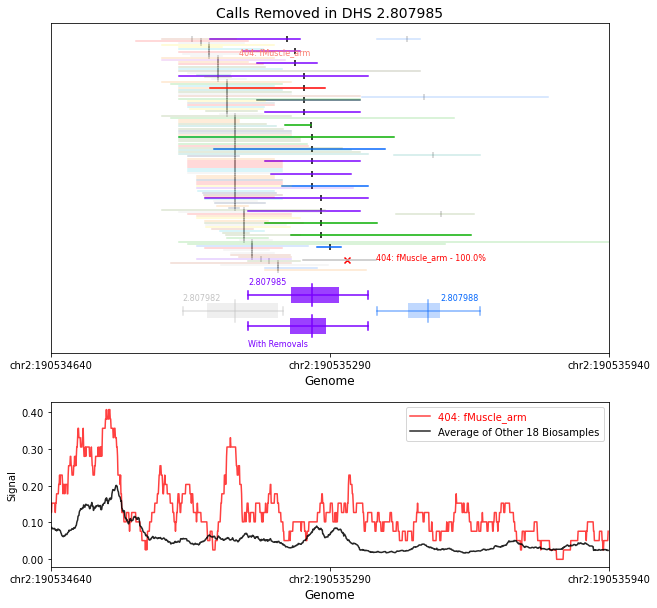

Calls Removed in DHS 3.555084


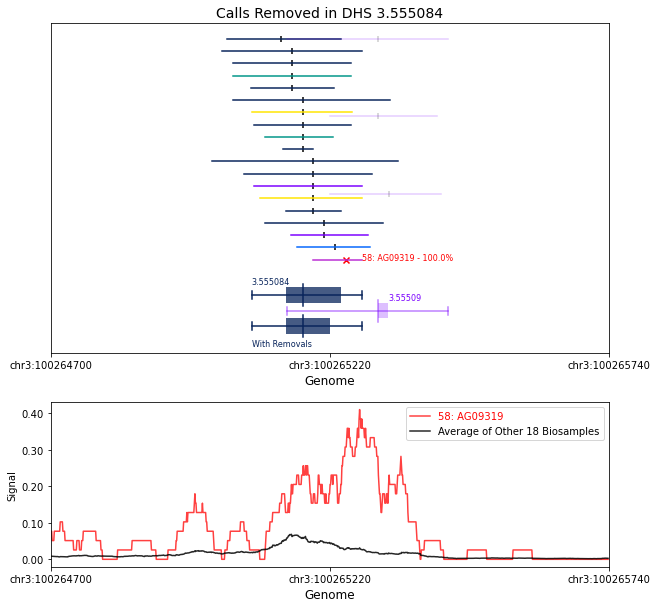

Calls Removed in DHS 9.610678


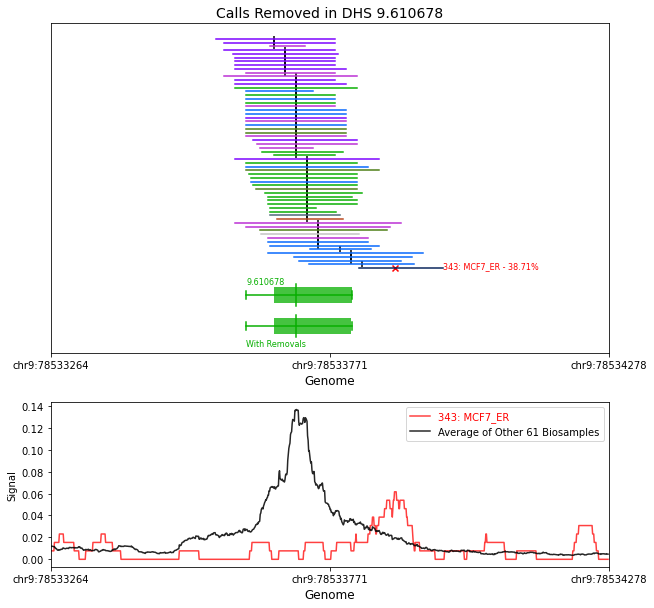

Calls Removed in DHS 22.963081


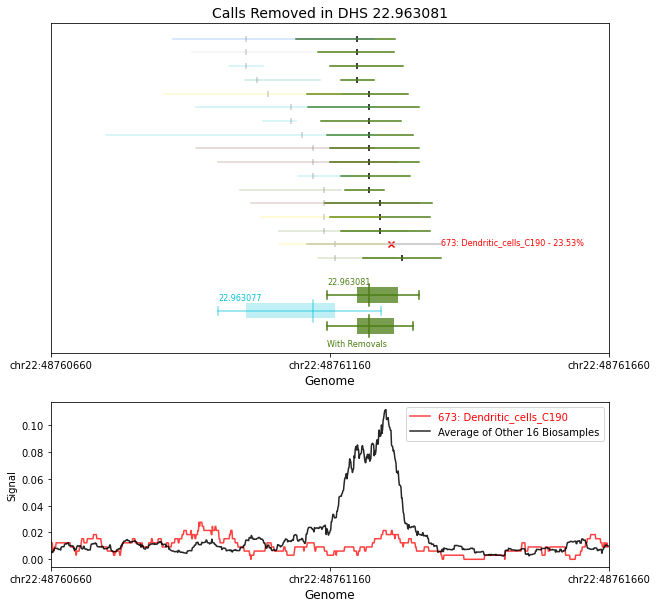

Calls Removed in DHS 3.97085


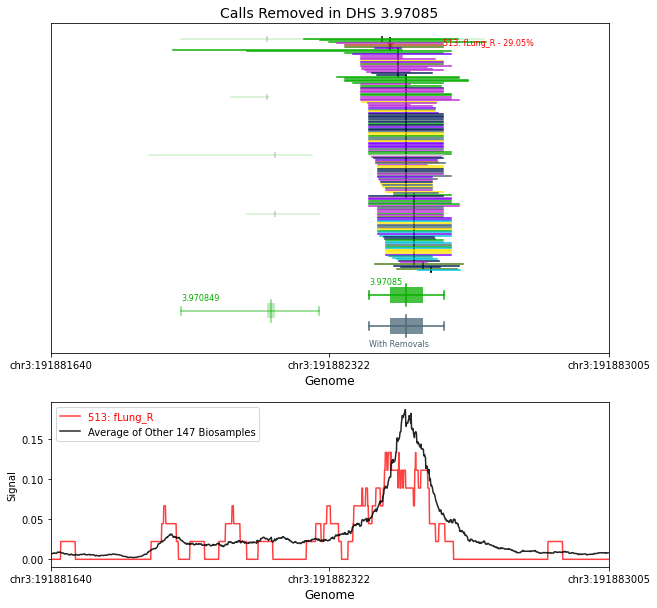

Calls Removed in DHS 10.3046867


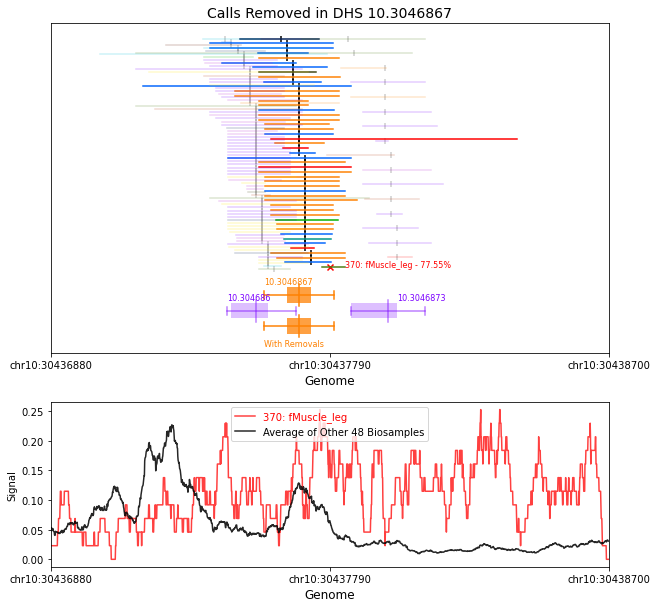

Calls Removed in DHS 10.344875


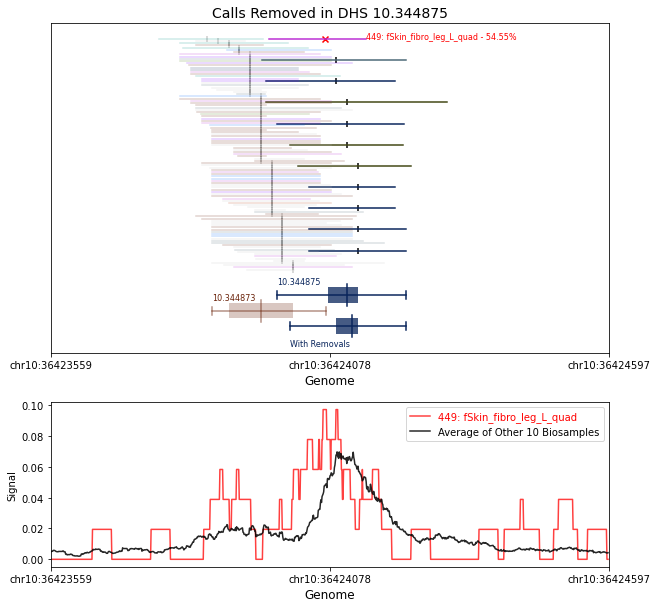

Calls Removed in DHS 9.9226646


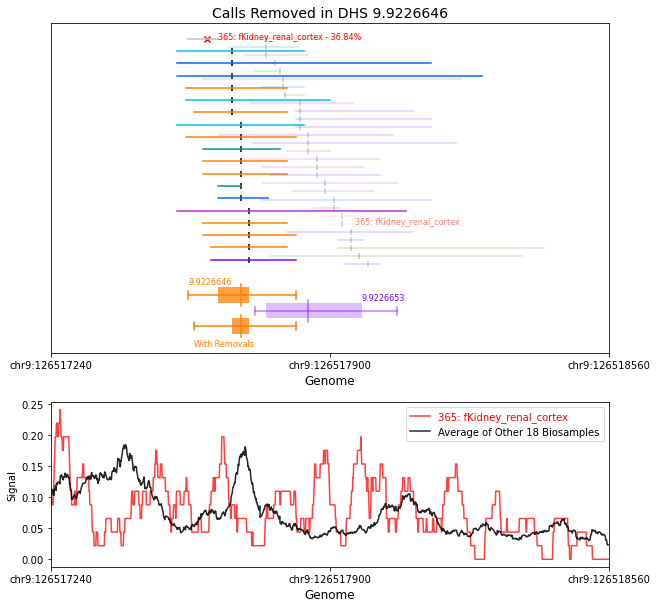

Calls Removed in DHS 14.557974


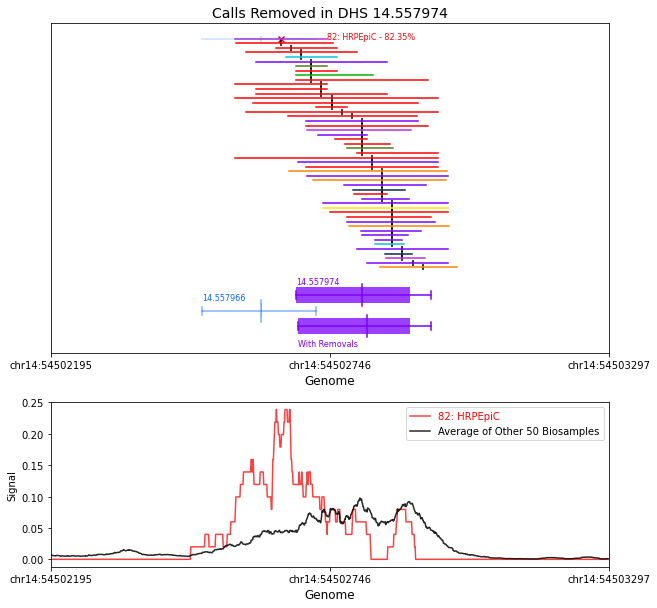

Calls Removed in DHS 14.751898


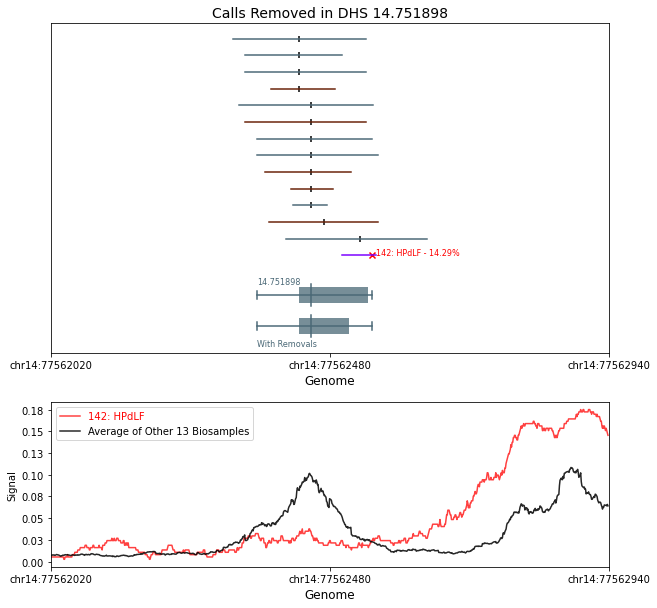

Calls Removed in DHS 4.5943771


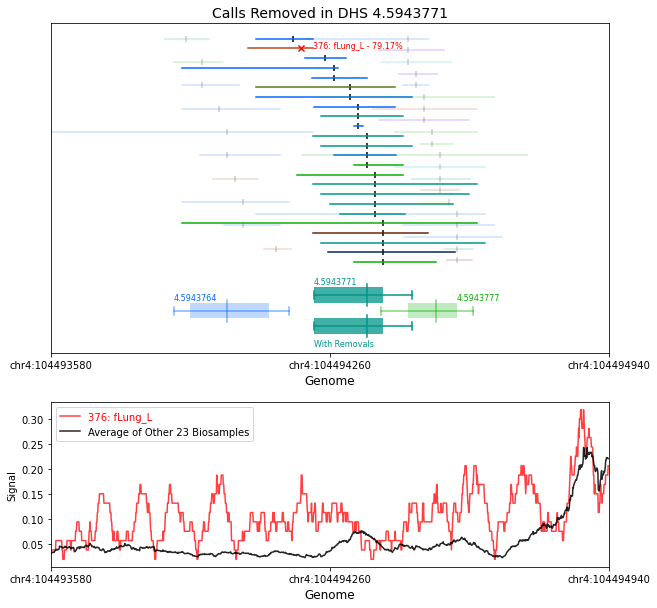

Calls Removed in DHS 2.409268


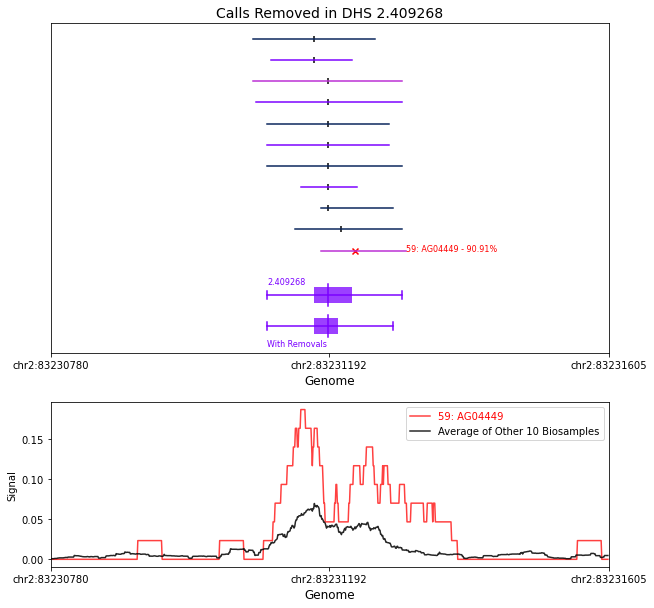

In [36]:
DHSs_to_plot_high_signal_high_distance = [1859586, 3465218, 2736131, 1810437, 2195464, 3375113, 2072585, 2310155,  352267, 360465, 3440659,  983059, 1015828, 2433046, 1687574]

for i in DHSs_to_plot_high_signal_high_distance:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True)

Calls Removed in DHS 2.860048


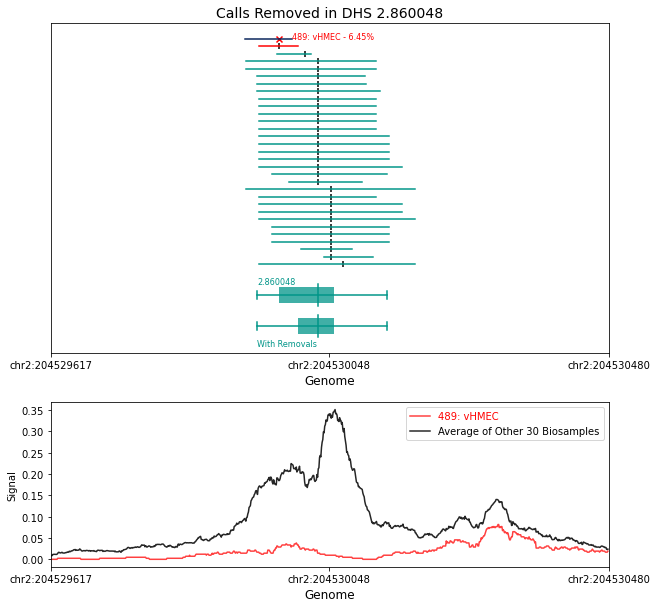

Calls Removed in DHS 2.88613


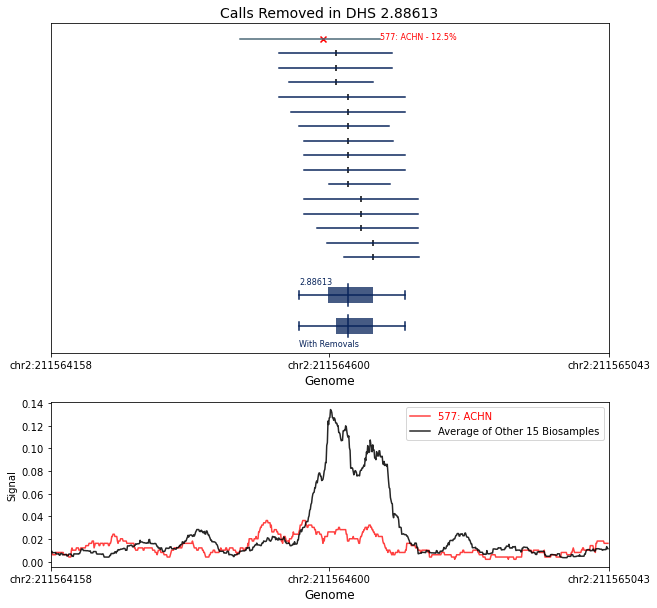

Calls Removed in DHS 11.504684


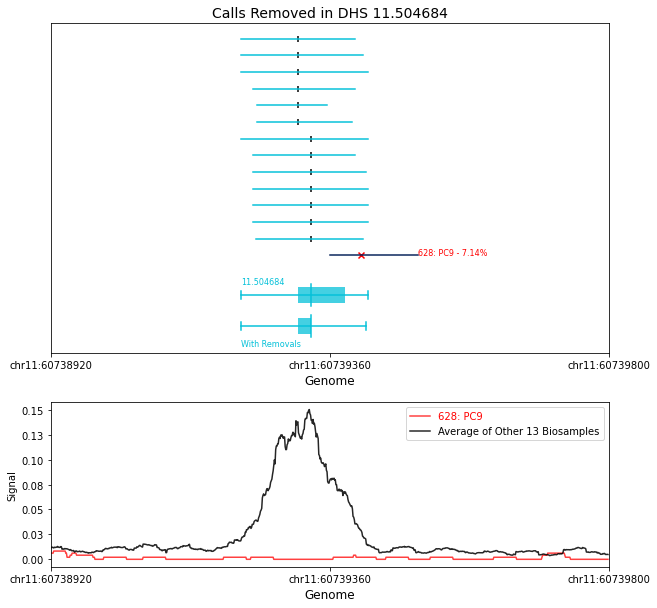

Calls Removed in DHS 14.3516605


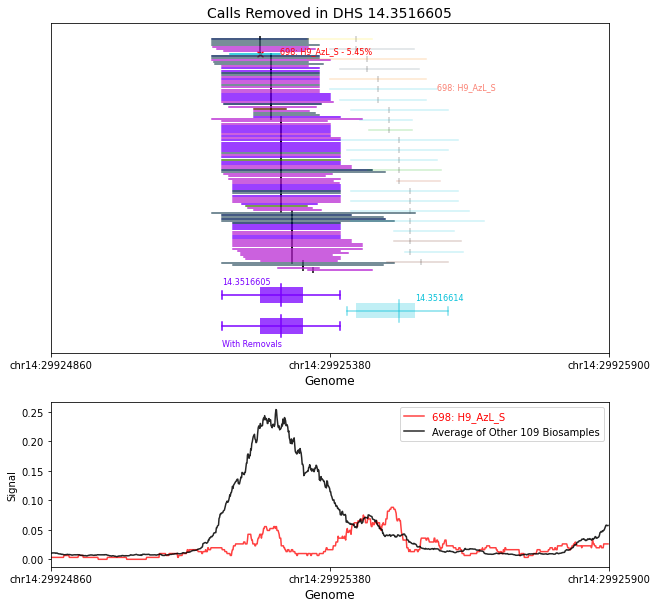

Calls Removed in DHS 2.973994


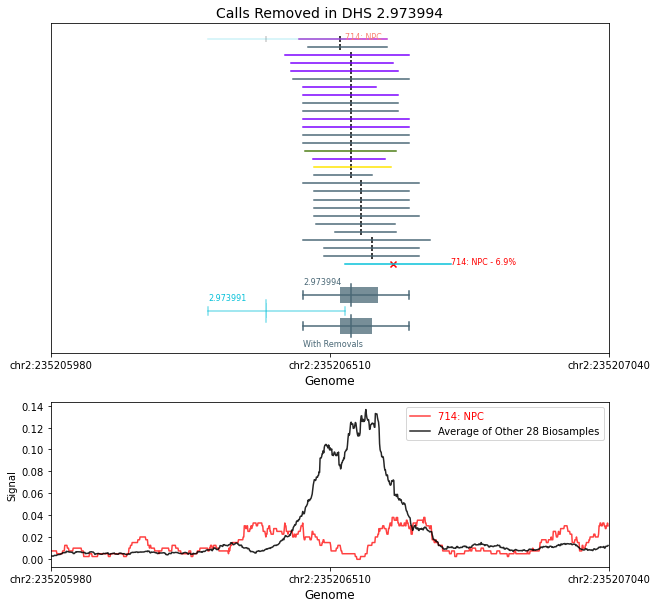

Calls Removed in DHS 5.9516691


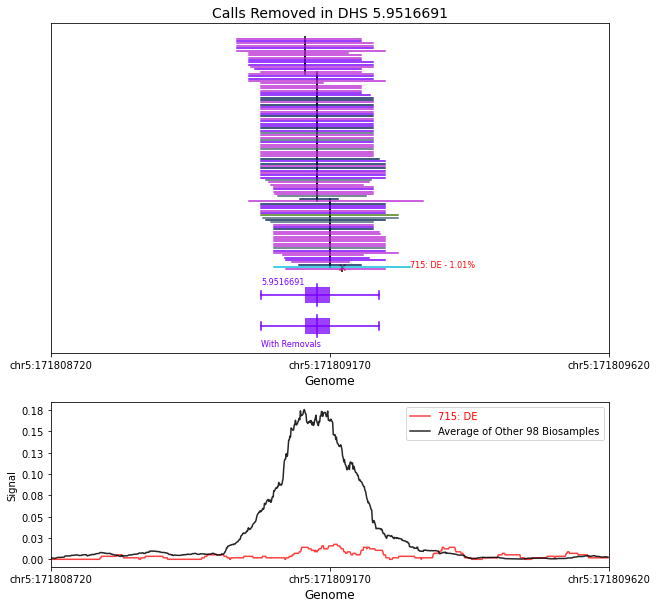

Calls Removed in DHS 3.423246


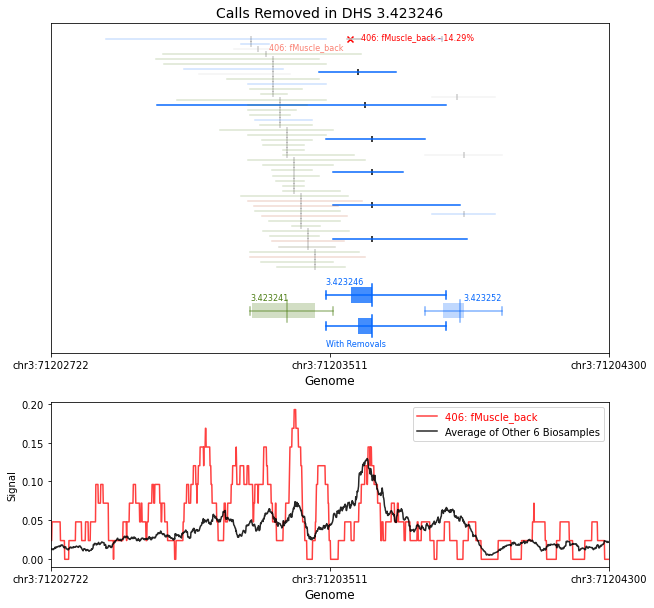

Calls Removed in DHS 6.324893


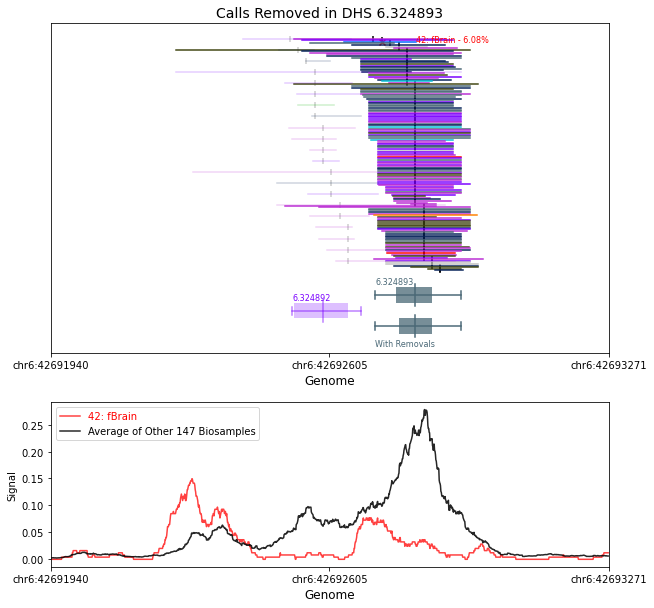

Calls Removed in DHS 7.368365


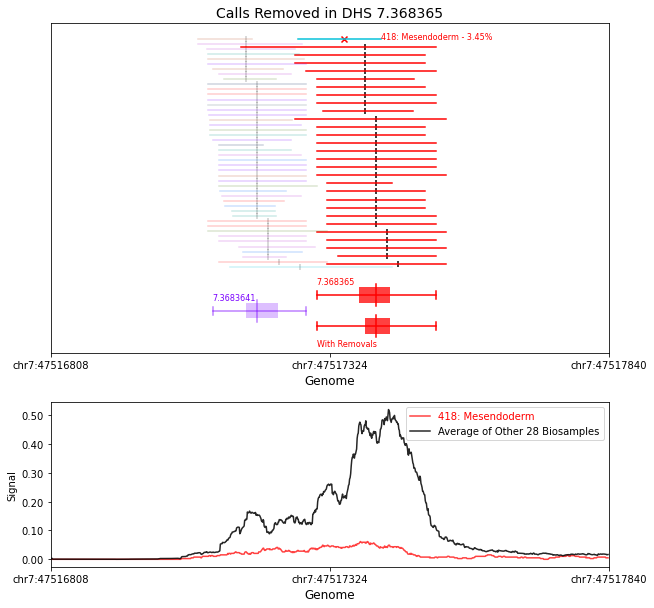

Calls Removed in DHS 1.668021


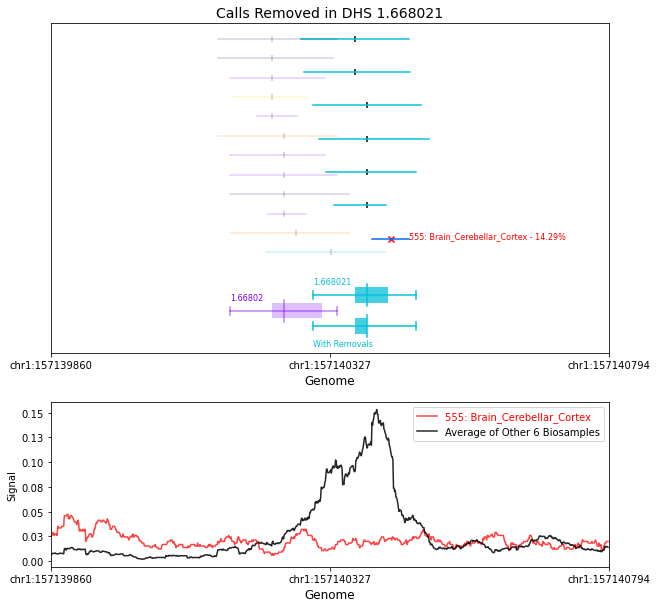

In [35]:
DHSs_to_plot_low_signal_high_distance = [1826816, 1835013,  557062,  958477, 1867811, 2719782, 2170922, 2801706, 3014700, 188462]

for i in DHSs_to_plot_low_signal_high_distance:
    ind = np.where(unique_removed_DHS_calls_DHS_inds==i)[0][0]
    plotting_removed_calls(ind, signal_type='bam', bam_norm=True)

**testing is median is different than FWHM for start and end locations**

In [241]:
fwhm_vs_median_urdc = []
for chunk_info in unique_removed_DHS_calls:
    fwhm_start, fwhm_end = calc_start_end(chunk_info)
    median_start = int(np.median(chunk_info[:, 1].astype(int)))
    median_end = int(np.median(chunk_info[:, 2].astype(int)))
    fwhm_vs_median_urdc.append([fwhm_start, 
                                median_start, 
                                median_start-fwhm_start, 
                                fwhm_end, median_end, 
                                median_end-fwhm_end])
fwhm_vs_median_urdc = np.array(fwhm_vs_median_urdc)

In [267]:
np.where((np.abs(fwhm_vs_median_urdc[:, 2])>1) | (np.abs(fwhm_vs_median_urdc[:, 5])>1))[0].shape

(18192,)

**Overlapping core regions**

In [39]:
core_start = np.array(DHS_metadata['core_start']).astype(float)
core_end = np.array(DHS_metadata['core_end']).astype(float)
chrm = np.array(DHS_metadata['seqname'])
identifiers = np.array(DHS_metadata['identifier'])
summit = np.array(DHS_metadata['summit']).astype(float)

start = np.array(DHS_metadata['start']).astype(float)
end = np.array(DHS_metadata['end']).astype(float)

start_right = start[1:]
end_right = end[1:]

start_adj = start[:-1]
end_adj = end[:-1]

core_start_right = core_start[1:]
core_end_right = core_end[1:]
chrm_right = chrm[1:]

core_start_adj = core_start[:-1]
core_end_adj = core_end[:-1]
chrm_adj = chrm[:-1]

In [40]:
core_start_lim = np.where(core_start < start, start, core_start)
core_end_lim = np.where(core_end > end, end, core_end)

right_start_lim = np.where(core_start_right < start_right, start_right, core_start_right)
adj_start_lim = np.where(core_start_adj < start_adj, start_adj, core_start_adj)

right_end_lim = np.where(core_end_right > end_right, end_right, core_end_right)
adj_end_lim = np.where(core_end_adj > end_adj, end_adj, core_end_adj)

In [42]:
# today = date.today()
# bed_path_name = os.path.join('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/', 'DHS_nonnan_core_start_end_CT' + today.strftime("%Y%m%d") + '.bed')
# f = open(bed_path_name, 'w')
# for i in range(len(chrm)):
#     if ((~np.isnan(core_start[i])) & (~np.isnan(core_end[i]))):
#         f.write(chrm[i] + '\t' + str(core_start[i].astype(int)) + '\t' + str(core_end[i].astype(int) + 1) + '\t' + str(identifiers[i]) + '\t' + str(i) + '\n')
# f.close()

In [43]:
# today = date.today()
# bed_path_name = os.path.join('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/', 'DHS_limited_nonnan_core_start_end_CT' + today.strftime("%Y%m%d") + '.bed')
# f = open(bed_path_name, 'w')
# for i in range(len(chrm)):
#     if ((~np.isnan(core_start_lim[i])) & (~np.isnan(core_end_lim[i]))):
#         f.write(chrm[i] + '\t' + str(core_start_lim[i].astype(int)) + '\t' + str(core_end_lim[i].astype(int) + 1) + '\t' + str(identifiers[i]) + '\t' + str(i) + '\n')
# f.close()

In [243]:
# today = date.today()
# bed_path_name = os.path.join('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/', 'DHS_summit_CT' + today.strftime("%Y%m%d") + '.bed')
# f = open(bed_path_name, 'w')
# for i in range(len(chrm)):
#     f.write(chrm[i] + '\t' + str(summit[i].astype(int)) + '\t' + str((summit[i]).astype(int) + 1) + '\t' + str(identifiers[i]) + '\t' + str(i) + '\n')
# f.close()

In [262]:
DHS_inds_summits_overlapping_cores = []
f = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/DHS_summits_with_overlapping_limited_core_regions_CT20220420.bed', 'r')
for line in f:
    line = re.split('\||\t|;', line.strip())
    if len(line) > 10:
        DHS_inds_summits_overlapping_cores.append(int(line[4]))
DHS_inds_summits_overlapping_cores = np.array(DHS_inds_summits_overlapping_cores)
DHS_inds_summits_overlapping_cores.shape

(7984,)

In [293]:
DHS_ind_pairs_fullcores_overlapping_fullcores = set([])
f = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/DHS_core_regions_overlapping_other_DHS_core_regions_CT20220420.bed', 'r')
for line in f:
    line = re.split('\||\t|;', line.strip())
    if ((len(line) > 10) & 
        (tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))) not in DHS_ind_pairs_fullcores_overlapping_fullcores)):
        
        DHS_ind_pairs_fullcores_overlapping_fullcores.add(tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))))
        
DHS_ind_pairs_fullcores_overlapping_fullcores = np.array(list(DHS_ind_pairs_fullcores_overlapping_fullcores))
DHS_ind_pairs_fullcores_overlapping_fullcores.shape

/tmp/ipykernel_184670/2232599042.py:10: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  DHS_ind_pairs_fullcores_overlapping_fullcores = np.array(list(DHS_ind_pairs_fullcores_overlapping_fullcores))


(13107,)

In [287]:
DHS_ind_pairs_cores_overlapping_cores = set([])
f = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/DHS_limited_core_regions_overlapping_other_DHS_limited_core_regions_CT20220420.bed', 'r')
for line in f:
    line = re.split('\||\t|;', line.strip())
    if ((len(line) > 10) & 
        (tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))) not in DHS_ind_pairs_cores_overlapping_cores)):
        
        DHS_ind_pairs_cores_overlapping_cores.add(tuple(np.sort(np.unique(np.array(line[4::5]).astype(int)))))
        
DHS_ind_pairs_cores_overlapping_cores = np.array(list(DHS_ind_pairs_cores_overlapping_cores))
DHS_ind_pairs_cores_overlapping_cores.shape

/tmp/ipykernel_184670/1638290964.py:10: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  DHS_ind_pairs_cores_overlapping_cores = np.array(list(DHS_ind_pairs_cores_overlapping_cores))


(10415,)

**step by step resolving overlap examples**

In [45]:
file = open('/home/ctrader/Hold/NMF/DHS/resolving_dhs_overlaps_examples/chunk0700_partial_CT20220419.txt', "r")
step_data = []
all_steps = []
for line in file:
    line = (line.strip().split())
    if (line[0] == 'seqname'): #new step
        if step_data:
            all_steps.append(np.array(step_data))
        step_data = []
    else:
        step_data.append(line)
all_steps.append(np.array(step_data))

In [46]:
DHS_metadata['start'] = DHS_metadata['start'].astype(int)
DHS_metadata['end'] = DHS_metadata['end'].astype(int)

Step 1 of Isolated Peak Merging: Chunk0700_21_1 - Chunk0700_33_1


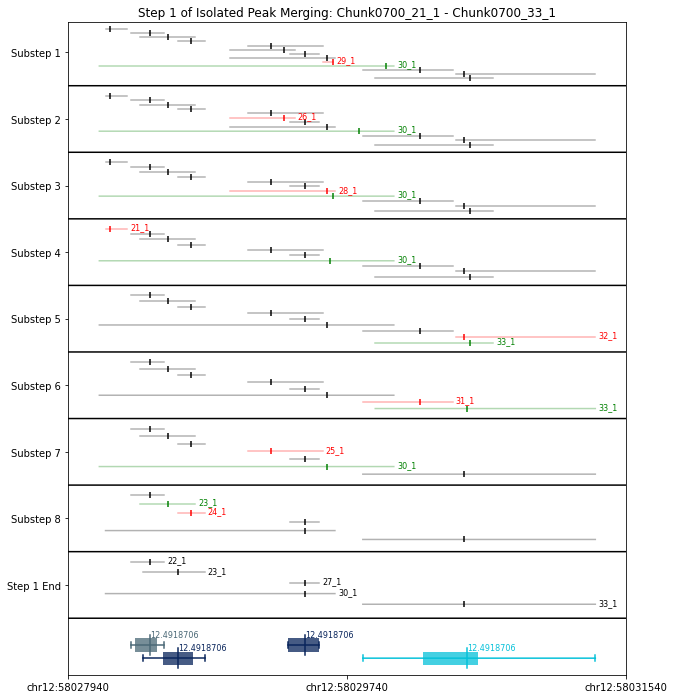

In [48]:
buffer=200
fig, axes = plt.subplots(nrows=1, figsize=(10,12))
fig.patch.set_facecolor('white')

start_height = 10
min_start = np.nan
max_end = np.nan

#plotting each line
for current_step, step_num in zip(all_steps, range(len(all_steps))):
    height = start_height - step_num
    min_start = np.nanmin([min_start, np.nanmin(current_step[:, 2].astype(int))])
    max_end = np.nanmax([max_end, np.nanmax(current_step[:, 3].astype(int))])
    if step_num < len(all_steps)-1:
        next_step = all_steps[step_num+1]
        current_rows = current_step[:, 0].astype(int)
        next_rows = next_step[:, 0].astype(int)
        missing_row = list(set(current_rows) - set(next_rows))[0]
        missing_row_ind = np.where(current_rows==(list(set(current_rows) - set(next_rows))))[0][0]
        current_numpeaks = current_step[np.where(current_step[:, 0]!=str(missing_row))[0], 7].astype(int)
        new_numpeaks = next_step[:, 7].astype(int)
        difference_numpeaks_ind = np.where(current_numpeaks-new_numpeaks!=0)[0][0]
        if difference_numpeaks_ind >= missing_row_ind:
            difference_numpeaks_ind += 1
        for row, ind in zip(current_step, range(len(current_step))):
            c = 'k'
            if ind == missing_row_ind:
                c = 'r'
                axes.text(row[3].astype(int)+20, height - 0.01, row[4], fontsize=8, c=c)
            if ind == difference_numpeaks_ind:
                c = 'g'
                axes.text(row[3].astype(int)+20, height - 0.01, row[4], fontsize=8, c=c)
            axes.plot(np.arange(int(row[2]), int(row[3]) + 1), 
                      np.ones(int(row[3]) - int(row[2]) + 1) * height,
                      c=c,
                      alpha=0.3)
            axes.scatter(int(row[9]), height, c=c, marker='|')
            height -= 0.8 / len(current_step)
    else:
        for row, ind in zip(current_step, range(len(current_step))):
            c = 'k'
            axes.plot(np.arange(int(row[2]), int(row[3]) + 1), 
                      np.ones(int(row[3]) - int(row[2]) + 1) * height,
                      c=c,
                      alpha=0.3)
            axes.scatter(int(row[9]), height, c=c, marker='|')
            axes.text(row[3].astype(int)+20, height - 0.01, row[4], fontsize=8, c=c)
            height -= 0.8 / len(current_step)

# minimum starting peak location 
min_start = int(min_start)
#maximum ending peak location
max_end = int(max_end)

# horizontal bars
for i in range(len(all_steps)):
    axes.plot(np.arange(min_start - buffer, max_end + 1 + buffer), 
              np.ones(max_end - min_start + 1 + (2 * buffer)) * (start_height - 0.85 - i),
              c='k')

dhss_of_interest = DHS_metadata[(DHS_metadata['start']>=min_start) & 
                                (DHS_metadata['end']<=max_end) & 
                                (DHS_metadata['seqname']=='chr12')]
starts = np.array(dhss_of_interest['start']).astype(int)
ends = np.array(dhss_of_interest['end']).astype(int)
core_starts = np.array(dhss_of_interest['core_start']).astype(int)
core_ends = np.array(dhss_of_interest['core_end']).astype(int)
summits = np.array(dhss_of_interest['summit']).astype(int)
comps = np.array(dhss_of_interest['component'])
identifiers = np.array(dhss_of_interest['identifier'])

for i in range(len(starts)-1):
    if i % 2 == 1:
        adjustment = 0.45
    else:
        adjustment = 0.65
    c = color[np.array(comps_for_heatmap)==comps[i]][0]
    if core_starts[i] < starts[i]:
        core_start = starts[i]
    else:
        core_start = core_starts[i]
    if core_ends[i] > ends[i]:
        core_end = ends[i]
    else:
        core_end = core_ends[i]
    dhs_rect = patches.Rectangle((core_start, 0 + adjustment),
                                  core_end - core_start, 
                                  0.2,
                                  facecolor=c,
                                  alpha=0.75)
    axes.add_patch(dhs_rect)
    axes.text(summits[i], 0.22 + adjustment, identifiers[0], fontsize=8, c=c)
    #plotting range of DHS
    axes.plot(np.arange(starts[i], ends[i] + 1), 
              np.ones(ends[i].astype(int) - starts[i].astype(int) + 1) * (0.1) + adjustment,
              c=c)
    axes.plot([starts[i].astype(int), starts[i].astype(int)], 
              [0.05 + adjustment, 0.15 + adjustment],
              c=c)
    axes.plot([ends[i].astype(int), ends[i].astype(int)], 
              [0.05 + adjustment, 0.15 + adjustment],
              c=c)
    axes.plot([summits[i].astype(int), summits[i].astype(int)], 
              [-0.05 + adjustment, 0.25 + adjustment],
              c=c)
axes.set_xlim([min_start-buffer, max_end+buffer])
axes.set_ylim([0.3, 10.1])
axes.set_yticks(np.flip(np.arange(1, 10)+0.65))
axes.set_yticklabels(['Substep 1', 'Substep 2', 'Substep 3', 'Substep 4', 'Substep 5', 'Substep 6', 'Substep 7',
                      'Substep 8', 'Step 1 End'])
chrm = 'chr12'
axes.set_xticks([min_start-buffer, int((max_end+min_start)/2), max_end+buffer])
axes.set_xticklabels([chrm + ':' + str(min_start-buffer), chrm + ':' + str(int((max_end+min_start)/2)), chrm + ':' + str(max_end+buffer)])
title = 'Step 1 of Isolated Peak Merging: Chunk0700_21_1 - Chunk0700_33_1'
axes.set_title(title)
today = date.today()
plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_removal_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
print(title)